# Notebook 3 - Genetic Algorithm Poker Agent

> **Reproduce:** `.venv/Scripts/python scripts/build_notebooks.py --execute 03_genetic_algorithm_poker_agent`
> (about 3 minutes on 6 worker processes; the source is `notebooks/src/03_genetic_algorithm_poker_agent.py`,
> the adjustable numbers are in the *NOTEBOOK CONFIGURATION* cell below). The agent itself was evolved by
> `.venv/Scripts/python scripts/train_ga.py` (about 25 minutes on 21 cores); this notebook only *reads* those
> artifacts from `artifacts/models/ga/` and runs fresh, seeded evaluations on top of them.

## 1. Overview and research question

**Research question.** *Can a small, human-readable strategy (18 numbers) be discovered by evolution alone -
with no labelled data and no teacher to imitate - and what does the evolved strategy look like?*

Four sub-questions structure the notebook:

1. **Did evolution work?** Is the evolved population better than the random population it started from, measured
   on deals and opponents that were never used for selection?
2. **What did it find?** How do the evolved genes differ from the hand-made styles (nit, tag, lag, ...)?
3. **How strong is it?** Duplicate-deal BB/100 with 95% confidence intervals against bots, hand-made styles and the
   (held-out) equity teacher.
4. **How does it play?** VPIP, PFR, aggression and fold/call/raise frequencies.

### What is a "GA agent"?

A *genome* is a vector of 18 bounded real numbers (thresholds on hand strength, bluff and sizing frequencies,
opponent-adaptation weights). A fixed, readable **rule cascade** turns the genome plus the current observation into
one of five abstract actions (fold / check-call / raise 1/2 pot / raise pot / all-in). A *genetic algorithm* keeps a
population of genomes, scores each one by **playing simulated heads-up matches**, and breeds the next population
from the better ones (selection, crossover, mutation). Nothing is differentiated and nothing is labelled: the only
training signal is chips won in play.

### How it differs from the EBM and XGBoost agents

| | EBM / XGBoost agents | Genetic algorithm agent |
|---|---|---|
| Training signal | **supervised imitation**: predict the action of a transparent equity "teacher" on teacher-generated states | **profit in simulated play** (BB/100 against a pool of opponents) |
| Needs labels / a teacher | yes - the teacher *is* the label source | no - the teacher is never seen in training; it is only a **held-out opponent** |
| Model | additive boosted trees (EBM shape functions) / gradient-boosted trees (SHAP) | 18 named genes inside a fixed rule cascade |
| Explanation | feature contributions (shape functions, SHAP values) | which rule fired, with which gene values (`explain`) |
| Ceiling | bounded by the teacher it imitates (no search) | whatever the cascade can express and the fitness rewards |
| Main weakness | copies the teacher's mistakes; accuracy is not skill | noisy fitness, opponent-pool dependence, tiny hypothesis space |

**Honest framing.** The GA is *not* tabula rasa: the initial population contains three hand-made styles (tag, lag, nit)
and the training pool contains the five hand-made styles as sparring partners. What it does *not* get is any label,
teacher or human decision data.

### Evidence labels used throughout

* **[saved]** - read from the artifacts of the training run (`artifacts/models/ga/`), never recomputed. The training-time numbers
  (fitness curves, per-generation and population validation) were recorded under the **legacy single-table duplicate protocol**;
  the `final_evaluation` was recomputed under the corrected two-table protocol (section 3.5).
* **[fresh]** - simulated in this notebook with a visible seed (`EVAL_SEED`, seed namespace `eval`), on deals that no
  training or validation step ever saw.
* **[demo]** - a small illustration with the real package code; it is not evidence about strength.

Every number printed below is computed from those sources; sentences that quote numbers are generated from them.

In [1]:
# ==========================================
# NOTEBOOK CONFIGURATION
# ==========================================
EVAL_SEED = 777_001  # master seed of every FRESH simulation here (namespace "eval"); the training run used 2026
EVAL_PAIRS = 600  # duplicate pairs (2 hands each) per matchup in the fresh evaluation (section 8b)
EVAL_PAIRS_TEACHER = 2000  # more pairs against the teacher: the matchup that matters most (and is noisiest)
DEMO_SEED = 7  # RNG seed of the operator demos (section 4) and of every bootstrap in this notebook
DEMO_HAND_SEEDS = (24, 29, 38)  # deals of the decision-trace demo (section 2): value bet / disciplined fold / all-in
VARIANCE_SESSIONS = 60  # independent sessions per scheme and opponent in the duplicate-deal variance experiment (section 3)
VARIANCE_SESSION_HANDS = 100  # hands per session in that experiment
CRN_PAIRS = 400  # duplicate pairs of the common-random-numbers demo (section 3)
AA_PAIRS = 4000  # duplicate pairs of each identical-agents (A/A) test of the duplicate protocols (section 3.5)
PROTOCOL_PAIRS = 800  # duplicate pairs per opponent of the legacy vs two-table replay of the saved final evaluation (section 3.5)
STYLE_LEAGUE_HANDS = 1000  # hands per pairing of the 9-agent league used for playing-style statistics (section 8c)
SWAP_OPPONENTS = ("teacher", "balanced", "bluffer", "nit", "lag")  # opponents of the gene-group swap test (section 8d)
N_WORKERS = 6  # worker processes for the simulations (shared machine: keep <= 6)

In [2]:
import json
import multiprocessing
import shutil
import textwrap
import time
from concurrent.futures import ProcessPoolExecutor
from dataclasses import replace
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from scipy import stats

from poker_arena.agents.ga_agent import (
    GENE_HIGHS,
    GENE_LOWS,
    GENE_NAMES,
    GENE_SPECS,
    HELD_OUT_PRESETS,
    PRESETS,
    TRAINING_PRESETS,
    GeneticAgent,
    Genome,
)
from poker_arena.agents.registry import AgentSpec, create_agent
from poker_arena.cards import ALL_CARDS
from poker_arena.config import ARTIFACTS_DIR, MODELS_DIR, GameConfig, derive_seed
from poker_arena.data.evaluation import pair_results, summarize
from poker_arena.engine.deals import Deal
from poker_arena.engine.session import HandSession
from poker_arena.equity import preflop_equity
from poker_arena.evolution.fitness import (
    VALIDATION_NAMESPACE,
    FitnessConfig,
    MatchRunner,
    PokerFitness,
    opponent_from_name,
    training_pool,
)
from poker_arena.evolution.run import FINAL_LABEL
from poker_arena.explain import notebook_plots as nbp
from poker_arena.tournament import KeepHandsPolicy, MatchConfig, load_results, run_match, run_tournament
from poker_arena.tournament.config import SINGLE_TABLE, TWO_TABLE
from poker_arena.tournament.stats import pool_groups, scale_to_bb_per_100, t_estimate
from poker_arena.training.ga import (
    Bounds,
    GAConfig,
    blx_crossover,
    gaussian_mutation,
    make_initial_population,
    mutation_scale_at,
    next_generation,
    population_diversity,
    tournament_select,
    uniform_crossover,
)

NOTEBOOK_STARTED = time.perf_counter()
nbp.apply_style()

# ---- the saved training run (everything below that says [saved] comes from these files) ----
GA_DIR = MODELS_DIR / "ga"


def read_json(name: str) -> dict:
    return json.loads((GA_DIR / name).read_text(encoding="utf-8"))


meta, run_cfg, best_doc = read_json("metadata.json"), read_json("config.json"), read_json("best_genome.json")
pop_doc, hof_doc, history_json = read_json("population_final.json"), read_json("hall_of_fame.json"), read_json("history.json")
history = pd.read_csv(GA_DIR / "history.csv")
TRAIN, FINAL = meta["training"], meta["final_evaluation"]
GAME = GameConfig.from_dict(meta["game_config"])
GA_CONFIG = GAConfig(**run_cfg["ga"])
BOUNDS = Bounds.for_genome()
EVOLVED_AGENT = GeneticAgent.load(GA_DIR, name="evolved")  # validates schema version and gene set
EVOLVED = EVOLVED_AGENT.genome
assert EVOLVED.to_dict() == best_doc["genes"]
SPAN = GENE_HIGHS - GENE_LOWS


def to_unit(vector) -> np.ndarray:
    """Gene values rescaled to [0, 1] of each gene's allowed range (makes genes comparable)."""
    return (np.asarray(vector, dtype=float) - GENE_LOWS) / SPAN


# ---- small display helpers (formatting only) ----
def md_table(frame: pd.DataFrame, floatfmt: str = "{:.3f}") -> Markdown:
    """A pandas frame as a GitHub-flavoured markdown table (deterministic, renders everywhere)."""
    header = "| " + " | ".join(map(str, frame.columns)) + " |"
    rule = "|" + "|".join("---" for _ in frame.columns) + "|"
    cell = lambda v: floatfmt.format(v) if isinstance(v, (float, np.floating)) else str(v)  # noqa: E731
    rows = ["| " + " | ".join(cell(v) for v in row) + " |" for row in frame.itertuples(index=False)]
    return Markdown("\n".join([header, rule, *rows]))


def ci_text(estimate: float, low: float, high: float) -> str:
    return f"{estimate:+.0f} [{low:+.0f}, {high:+.0f}]"


def verdict(low: float, high: float) -> str:
    """Words for a confidence interval of a BB/100 difference from zero (never more than the CI supports)."""
    return "wins" if low > 0 else "loses" if high < 0 else "no significant difference"


SUITS = {"s": "♠", "h": "♥", "d": "♦", "c": "♣"}


def pretty(cards) -> str:
    return " ".join(card[0] + SUITS[card[1]] for card in cards) or "-"


# ---- agents as picklable registry specs ----
# The registry builds the evolved agent from artifacts/models/ga/. To run the hand-made presets (and edited genomes)
# through the very same evaluation helpers, each genome is written in the same two-file artifact format into
# artifacts/tmp/ and addressed by its folder: GeneticAgent.load(model_dir=...) is the registry's own entry point.
GENOME_SPEC_DIR = ARTIFACTS_DIR / "tmp" / "nb03_genomes"
EVOLVED_SPEC = AgentSpec("ga", {}, label="evolved")


def genome_spec(label: str, genome: Genome) -> AgentSpec:
    folder = GENOME_SPEC_DIR / label
    folder.mkdir(parents=True, exist_ok=True)
    (folder / "best_genome.json").write_text(json.dumps({"schema_version": meta["schema_version"], "genes": genome.to_dict()}))
    (folder / "metadata.json").write_text(
        json.dumps({"schema_version": meta["schema_version"], "gene_names": list(GENE_NAMES), "equity_samples": meta["equity_samples"]})
    )
    return AgentSpec("ga", {"model_dir": str(folder)}, label=label)


def preset_spec(name: str) -> AgentSpec:
    return genome_spec(name, PRESETS[name])


def run_pairs(jobs: dict) -> dict[object, np.ndarray]:
    """Duplicate-pair evaluations of many matchups on ONE process pool: ``{key: (hero, opponent, pairs, seed_parts[, protocol])}``
    -> ``{key: BB per pair of the hero}`` (``poker_arena.data.evaluation.pair_results``: two-table protocol unless stated;
    deterministic, any worker count)."""
    with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=multiprocessing.get_context("spawn")) as pool:
        futures = {
            key: pool.submit(pair_results, job[0], job[1], job[2], job[3], GAME, 1, protocol=job[4] if len(job) > 4 else TWO_TABLE)
            for key, job in jobs.items()
        }
        return {key: future.result() for key, future in futures.items()}


display(Markdown(f"Loaded the saved run created at `{meta['created_at']}`; evolved genome validated by `GeneticAgent.load` "
                 f"(schema version {meta['schema_version']}, {len(GENE_NAMES)} genes)."))

Loaded the saved run created at `2026-10-11T13:05:43+00:00`; evolved genome validated by `GeneticAgent.load` (schema version 1, 18 genes).

### Reproducibility box

Everything needed to regenerate the agent, and the seeds that keep every random stream apart.

In [3]:
cfg = run_cfg["effective_config"]
timing = meta["timings_seconds"]
lib = meta["library_versions"]
display(Markdown(f"""
| item | value |
|---|---|
| **Command** | `.venv/Scripts/python scripts/train_ga.py` (config block at the top of the script; `--smoke` for a 1-2 minute check, `--evaluate-only` to refresh only the held-out evaluation) |
| **Master seed** | `{cfg['RANDOM_SEED']}`: operators, training deals, validation deals and agent streams all derive from it through `derive_seed(namespace, ...)` |
| **Search** | {GA_CONFIG.generations} generations x {GA_CONFIG.population_size} genomes; elitism {GA_CONFIG.elite_count}; tournament size {GA_CONFIG.tournament_size}; {GA_CONFIG.crossover_kind.upper()}-{GA_CONFIG.blx_alpha} crossover (rate {GA_CONFIG.crossover_rate}); Gaussian mutation (rate {GA_CONFIG.mutation_rate}, scale {GA_CONFIG.mutation_scale} of each gene range, decaying to x{GA_CONFIG.mutation_end_factor}); {GA_CONFIG.immigrant_count} random immigrants per generation; hall of fame {GA_CONFIG.hall_of_fame_size} |
| **Fitness games** | {TRAIN['hands_per_evaluation']} hands per genome per generation, split over {len(TRAIN['training_opponents'])} pool opponents + hall of fame; Monte-Carlo equity with {meta['equity_samples']} samples post-flop |
| **Training pool** | {', '.join(TRAIN['training_opponents'])} (+ hall of fame of earlier champions) |
| **Initial population** | {', '.join(cfg['SEED_PRESETS'])} (hand-made) + {GA_CONFIG.population_size - len(cfg['SEED_PRESETS'])} uniformly random genomes |
| **Validation (never used for selection)** | {', '.join(TRAIN['validation_opponents'])}; {cfg['VALIDATION_PAIRS']} duplicate pairs per opponent, identical deals every generation |
| **Final held-out evaluation** | {FINAL['pairs_per_opponent']} duplicate pairs ({FINAL['hands_per_opponent']} hands) against {len(FINAL['opponents'])} opponents, identical deals for the evolved genome and the reference presets |
| **Duplicate protocol** | training and per-generation validation: legacy single-table (the metadata does not record it); `final_evaluation`: two-table, recomputed `{meta.get('final_evaluation_refreshed_at', 'n/a')}` with `--evaluate-only`; every fresh simulation in this notebook: two-table, the package default - see section 3.5 |
| **Game** | heads-up NLHE, blinds {GAME.small_blind}/{GAME.big_blind}, stacks reset to {GAME.starting_stack} ({GAME.stack_in_bb:.0f} BB) before every hand |
| **Cost of the run** | evolution {timing['evolution'] / 60:.0f} min + final evaluation {timing['final_evaluation'] / 60:.1f} min on {run_cfg['n_workers_used']} worker processes |
| **Libraries** | python {lib['python']}, numpy {lib['numpy']}, pandas {lib['pandas']}, pokerkit {lib['pokerkit']}, scipy {lib['scipy']} |
| **This notebook (fresh simulations)** | `EVAL_SEED = {EVAL_SEED}`, namespace `eval`, {N_WORKERS} worker processes; results do not depend on the worker count |
"""))


| item | value |
|---|---|
| **Command** | `.venv/Scripts/python scripts/train_ga.py` (config block at the top of the script; `--smoke` for a 1-2 minute check, `--evaluate-only` to refresh only the held-out evaluation) |
| **Master seed** | `2026`: operators, training deals, validation deals and agent streams all derive from it through `derive_seed(namespace, ...)` |
| **Search** | 40 generations x 40 genomes; elitism 2; tournament size 3; BLX-0.3 crossover (rate 0.8); Gaussian mutation (rate 0.2, scale 0.12 of each gene range, decaying to x0.4); 2 random immigrants per generation; hall of fame 3 |
| **Fitness games** | 3000 hands per genome per generation, split over 8 pool opponents + hall of fame; Monte-Carlo equity with 120 samples post-flop |
| **Training pool** | random, call_station, maniac, nit, tag, lag, passive, maniac-ish (+ hall of fame of earlier champions) |
| **Initial population** | tag, lag, nit (hand-made) + 37 uniformly random genomes |
| **Validation (never used for selection)** | random, call_station, maniac, balanced, bluffer, teacher; 150 duplicate pairs per opponent, identical deals every generation |
| **Final held-out evaluation** | 1500 duplicate pairs (3000 hands) against 9 opponents, identical deals for the evolved genome and the reference presets |
| **Duplicate protocol** | training and per-generation validation: legacy single-table (the metadata does not record it); `final_evaluation`: two-table, recomputed `2026-10-11T18:44:11+00:00` with `--evaluate-only`; every fresh simulation in this notebook: two-table, the package default - see section 3.5 |
| **Game** | heads-up NLHE, blinds 5/10, stacks reset to 1000 (100 BB) before every hand |
| **Cost of the run** | evolution 23 min + final evaluation 0.9 min on 21 worker processes |
| **Libraries** | python 3.13.2, numpy 2.5.4, pandas 3.0.6, pokerkit 0.7.6, scipy 1.18.1 |
| **This notebook (fresh simulations)** | `EVAL_SEED = 777001`, namespace `eval`, 6 worker processes; results do not depend on the worker count |


## 2. Genome and strategy representation

### 2.1 The 18 genes

Every gene has hard bounds (the search space is a box) and a plain-English meaning. Thresholds are expressed as
**equity against a random hand** (0.50 = an average hand, about 0.85 = pocket aces before the flop). That scale is the
one the whole project uses - it is cheap (an O(1) table look-up before the flop, a 120-sample Monte-Carlo estimate
after it) but it is *not* the equity against a betting range, which is why several genes (`call_margin`,
`fold_big_bet`, `deep_stack_caution`) are deliberate corrections that evolution is free to set.

In [4]:
specs = pd.DataFrame([s.to_dict() for s in GENE_SPECS])
gene_table = pd.DataFrame(
    {
        "group": specs["group"],
        "gene": [f"`{n}`" for n in specs["name"]],
        "range": [f"[{lo:g}, {hi:g}]" for lo, hi in zip(specs["low"], specs["high"])],
        "default (tag)": specs["default"],
        "evolved": [EVOLVED.to_dict()[n] for n in specs["name"]],
        "meaning": specs["description"],
    }
)
display(md_table(gene_table, "{:.3f}"))

| group | gene | range | default (tag) | evolved | meaning |
|---|---|---|---|---|---|
| preflop | `pf_play_btn` | [0.33, 0.65] | 0.420 | 0.404 | Button (first to act): minimum equity to enter the pot; weaker hands fold. |
| preflop | `pf_open_raise` | [0.38, 0.8] | 0.500 | 0.418 | Button: equity at/above which it raises first-in; between pf_play_btn and this it limps. |
| preflop | `pf_bb_raise` | [0.4, 0.85] | 0.580 | 0.455 | Big blind after a limp: raise (isolate) with at least this equity, otherwise check. |
| preflop | `pf_defend` | [0.33, 0.8] | 0.500 | 0.404 | Minimum equity to call a preflop raise (the pot-odds requirement must be met as well). |
| preflop | `pf_3bet` | [0.5, 0.95] | 0.680 | 0.631 | Equity at/above which the agent re-raises (3-bets) a raise. |
| preflop | `pf_shove` | [0.62, 0.95] | 0.800 | 0.918 | Equity at/above which the agent jams all-in over a preflop raise (4-bet/shove). |
| postflop | `value_bet` | [0.5, 0.92] | 0.620 | 0.590 | Bet for value when checked to with adjusted equity at/above this. |
| postflop | `value_raise` | [0.55, 0.98] | 0.780 | 0.851 | Raise a bet with adjusted equity at/above this. |
| postflop | `shove_threshold` | [0.7, 1] | 0.920 | 0.933 | Go all-in postflop with adjusted equity at/above this (1.0 = practically never). |
| defence | `call_margin` | [-0.1, 0.2] | 0.030 | 0.038 | Equity required to call = pot odds + this margin (negative = calls light, positive = tight). |
| defence | `fold_big_bet` | [0, 0.3] | 0.080 | 0.229 | Extra equity required per pot-size of the bet faced: big bets show a stronger range than 'random hand' equity assumes. |
| defence | `deep_stack_caution` | [0, 0.15] | 0.040 | 0.055 | Equity subtracted when stacks are deep relative to the pot (scaled by SPR up to 8): more chips behind = more to lose. |
| defence | `position_bonus` | [-0.05, 0.12] | 0.030 | -0.005 | Equity added when in position (button postflop) and subtracted out of position. |
| aggression | `bluff_freq` | [0, 0.7] | 0.120 | 0.024 | Probability of betting a weak hand when checked to (pure bluff). |
| aggression | `semi_bluff_freq` | [0, 1] | 0.500 | 0.462 | Probability of betting/raising a flush or open-ended straight draw instead of calling. |
| aggression | `big_bet_prob` | [0, 1] | 0.350 | 0.329 | Probability that a bet or raise is pot-sized instead of half-pot. |
| adaptation | `adapt_fold` | [0, 1] | 0.300 | 0.627 | Bluff/semi-bluff frequency added per +1.0 of opponent fold-to-bet above neutral (bluff more against folders, less against callers). |
| adaptation | `adapt_aggression` | [-0.4, 0.4] | 0.000 | -0.187 | Call margin added per +1.0 of opponent aggression above neutral (>0 tightens against aggressive opponents, <0 calls them down lighter). |

### 2.2 From genome to decision: a fixed rule cascade

The agent never learns *how* to decide; it only learns the numbers inside this cascade (legal actions are always
respected: the abstract action is resolved against the engine's legal-action mask). `adjusted equity` = equity +
position bonus - deep-stack caution.

| situation | rules, checked in this order | genes involved |
|---|---|---|
| **Preflop, big blind after a limp** | raise if equity >= `pf_bb_raise`, else check | `pf_bb_raise`, `big_bet_prob` |
| **Preflop, button first to act** | fold below `pf_play_btn`; limp up to `pf_open_raise`; raise above | `pf_play_btn`, `pf_open_raise`, `big_bet_prob` |
| **Preflop, facing a raise** | jam if equity >= `pf_shove`; 3-bet if >= `pf_3bet` (first raise only); call if >= max(`pf_defend`, required equity); else fold | `pf_shove`, `pf_3bet`, `pf_defend`, `call_margin`, `fold_big_bet`, `adapt_aggression` |
| **Post-flop, checked to** | all-in if adjusted >= `shove_threshold`; value bet if >= `value_bet`; semi-bluff a flush / open-ended draw with prob. `semi_bluff_freq` (+ adaptation); else bluff with prob. `bluff_freq` (+ adaptation); else check | `shove_threshold`, `value_bet`, `semi_bluff_freq`, `bluff_freq`, `adapt_fold`, `big_bet_prob` |
| **Post-flop, facing a bet** | all-in if >= `shove_threshold`; raise if >= `value_raise`; semi-bluff raise a draw; call if adjusted >= pot odds + `call_margin` + `fold_big_bet` x bet size + `adapt_aggression` x opponent aggression; else fold | `shove_threshold`, `value_raise`, `semi_bluff_freq`, `call_margin`, `fold_big_bet`, `adapt_aggression` |
| **Everywhere post-flop** | adjusted equity = equity + `position_bonus` (in position, minus out of position) - `deep_stack_caution` x min(SPR, 8) / 8 | `position_bonus`, `deep_stack_caution` |

Bluff and sizing decisions use two random coins per decision, drawn from the agent's private seeded generator on
*every* decision, so a run is exactly reproducible. `strategy_card()` rewrites a genome as readable rules:

In [5]:
display(Markdown("**Evolved strategy `[saved]`** - `Genome.strategy_card()`\n\n" + "\n".join(f"- {line}" for line in EVOLVED.strategy_card())))

**Evolved strategy `[saved]`** - `Genome.strategy_card()`

- Button, first to act: fold below equity 0.40, limp up to 0.42, raise at or above 0.42.
- Big blind vs a limp: raise with equity >= 0.45, otherwise check.
- Preflop vs a raise: call with equity >= 0.40 (and pot odds +0.04), 3-bet at >= 0.63, jam all-in at >= 0.92.
- Postflop (adjusted equity): bet for value at >= 0.59; facing a bet, raise at >= 0.85, go all-in at >= 0.93.
- Facing a bet: call when equity >= pot odds +0.04 + 0.23 per pot-size of the bet.
- Adjusted equity = equity -0.00 in position (+0.00 out of position) minus up to 0.06 for deep stacks.
- Bluffs 2% of weak hands when checked to; semi-bluffs 46% of flush/straight draws.
- Bet sizing: pot-size 33% of the time, otherwise half pot.
- Adaptation: bluff frequency +0.63 per +1.0 opponent fold-to-bet above neutral; call margin -0.19 per +1.0 opponent aggression above neutral.

### 2.3 Decision traces of real hands `[demo]`

Three hands played by the evolved agent (on the button) against the equity teacher, with the engine's `HandSession`
(allowed in notebooks; agents never see anything but the restricted observation). `explain()` reports which rule fired,
the gene values involved and the numbers behind the decision. The three deals were picked from a scan of the first 60
seeds to show a value bet, a disciplined fold and an all-in; they say nothing about strength.

In [6]:
ACTION_WORDS = {"CHECK_CALL": "check/call", "RAISE_SMALL": "raise 1/2 pot", "RAISE_POT": "raise pot", "ALL_IN": "all-in", "FOLD": "fold"}


def demo_trace(seed: int) -> tuple[str, pd.DataFrame, int]:
    """Play one deterministic hand (evolved on the button vs the teacher) and tabulate the evolved agent's decisions."""
    hero = GeneticAgent.load(GA_DIR, name="evolved")
    villain = create_agent("teacher")
    hero.reset(derive_seed("test", "nb03-demo", seed, "hero"))
    villain.reset(derive_seed("test", "nb03-demo", seed, "villain"))
    deal = Deal.from_seed(derive_seed("test", "nb03-demo", seed, "deal"))
    session = HandSession(GAME, deal, 0, (hero, villain), collect_explanations=True)
    rows = []
    while not session.is_complete:
        seat = session.actor_seat
        step = session.step()
        if seat == 0:
            details = step.decision.explanation["details"]
            obs = step.observation
            rows.append(
                {
                    "street": obs.street.name.lower(),
                    "board": pretty(obs.board),
                    "pot": obs.pot,
                    "to call": obs.to_call,
                    "action": ACTION_WORDS[step.decision.abstract],
                    "rule that fired": details["rules"][0].replace("->", "=>"),
                    "genes used": ", ".join(details["genes"]),
                }
            )
    record = session.finish()
    header = (
        f"**Hand (deal seed {seed})** - evolved (button) holds {pretty(deal.button_hole)}, teacher holds {pretty(deal.bb_hole)}, "
        f"board {pretty(deal.board)}. Evolved result: {record.result.payoffs[0] / GAME.big_blind:+.1f} BB."
    )
    return header, pd.DataFrame(rows), record.result.payoffs[0]


for hand_seed in DEMO_HAND_SEEDS:
    header, trace, _ = demo_trace(hand_seed)
    display(Markdown(header))
    display(md_table(trace))

**Hand (deal seed 24)** - evolved (button) holds A♠ 3♦, teacher holds 4♣ 4♦, board 8♠ 3♥ 8♦ T♠ T♣. Evolved result: +8.0 BB.

| street | board | pot | to call | action | rule that fired | genes used |
|---|---|---|---|---|---|---|
| preflop | - | 15 | 5 | raise 1/2 pot | A3o (equity 0.56) >= pf_play_btn 0.40 and >= pf_open_raise 0.42 => open-raise (1/2 pot) | pf_play_btn, pf_open_raise, big_bet_prob |
| flop | 8♠ 3♥ 8♦ | 60 | 20 | check/call | flop: equity 0.64 => adjusted 0.58 (-0.00 position, -0.06 deep stacks); adjusted >= required 0.40: pot odds 0.25 + call_margin +0.04 + fold_big_bet 0.11 + adapt_aggression -0.00 => call | position_bonus, deep_stack_caution, call_margin, fold_big_bet, adapt_aggression |
| turn | 8♠ 3♥ 8♦ T♠ | 120 | 40 | check/call | turn: equity 0.61 => adjusted 0.55 (-0.00 position, -0.05 deep stacks); adjusted >= required 0.40: pot odds 0.25 + call_margin +0.04 + fold_big_bet 0.11 + adapt_aggression -0.00 => call | position_bonus, deep_stack_caution, call_margin, fold_big_bet, adapt_aggression |
| river | 8♠ 3♥ 8♦ T♠ T♣ | 160 | 0 | raise pot | river: equity 0.71 => adjusted 0.66 (-0.00 position, -0.04 deep stacks); adjusted >= value_bet 0.59 => value bet (pot-size) | position_bonus, deep_stack_caution, value_bet, big_bet_prob |

**Hand (deal seed 29)** - evolved (button) holds Q♥ K♥, teacher holds T♠ A♣, board 8♣ 3♠ 7♠ 9♦ 7♣. Evolved result: -12.0 BB.

| street | board | pot | to call | action | rule that fired | genes used |
|---|---|---|---|---|---|---|
| preflop | - | 15 | 5 | raise 1/2 pot | KQs (equity 0.63) >= pf_play_btn 0.40 and >= pf_open_raise 0.42 => open-raise (1/2 pot) | pf_play_btn, pf_open_raise, big_bet_prob |
| preflop | - | 80 | 40 | check/call | KQs (equity 0.63) >= max(pf_defend 0.40, required 0.60: pot odds 0.33 + call_margin +0.04 + fold_big_bet 0.23 + adapt_aggression -0.00) => call | pf_defend, call_margin, fold_big_bet |
| flop | 8♣ 3♠ 7♠ | 180 | 60 | check/call | flop: equity 0.47 => adjusted 0.43 (-0.00 position, -0.03 deep stacks); adjusted >= required 0.40: pot odds 0.25 + call_margin +0.04 + fold_big_bet 0.11 + adapt_aggression -0.00 => call | position_bonus, deep_stack_caution, call_margin, fold_big_bet, adapt_aggression |
| turn | 8♣ 3♠ 7♠ 9♦ | 360 | 120 | fold | turn: equity 0.28 => adjusted 0.26 (-0.00 position, -0.01 deep stacks); adjusted < required 0.40: pot odds 0.25 + call_margin +0.04 + fold_big_bet 0.11 + adapt_aggression -0.00 => fold | position_bonus, deep_stack_caution, call_margin, fold_big_bet, adapt_aggression |

**Hand (deal seed 38)** - evolved (button) holds 9♥ A♠, teacher holds Q♣ Q♥, board A♣ 3♦ A♥ 3♠ 2♣. Evolved result: +100.0 BB.

| street | board | pot | to call | action | rule that fired | genes used |
|---|---|---|---|---|---|---|
| preflop | - | 15 | 5 | raise pot | A9o (equity 0.61) >= pf_play_btn 0.40 and >= pf_open_raise 0.42 => open-raise (pot-size) | pf_play_btn, pf_open_raise, big_bet_prob |
| preflop | - | 120 | 60 | check/call | A9o (equity 0.61) >= max(pf_defend 0.40, required 0.60: pot odds 0.33 + call_margin +0.04 + fold_big_bet 0.23 + adapt_aggression -0.00) => call | pf_defend, call_margin, fold_big_bet |
| flop | A♣ 3♦ A♥ | 360 | 180 | all-in | flop: equity 0.96 => adjusted 0.94 (-0.00 position, -0.01 deep stacks); adjusted >= shove_threshold 0.93 => all-in | position_bonus, deep_stack_caution, shove_threshold |

## 3. Fitness function design

The fitness of a genome is the *only* thing the algorithm optimises, so every choice below targets one failure mode
of "just maximise average BB/100 against some bots":

| design choice | what it does | failure mode it prevents |
|---|---|---|
| **Duplicate pairs** | every deal is played twice with the two players swapped between button and big blind (today at two independent tables; this GA was trained with the legacy single-table version, section 3.5) | card luck dominating the signal; seat/position imbalance |
| **Common random numbers (CRN)** | within a generation every genome plays the *same* deals against the *same* opponents | ranking genomes by luck of the draw instead of by strategy |
| **Fresh deals every generation** | deal seeds derive from the generation index | memorising a fixed set of deals; fitness values are therefore comparable *within* a generation only |
| **Diverse opponent pool + hall of fame** | random, calling station, maniac, five hand-made styles and the most recent champions | beating one exploitable opponent; mild co-evolution keeps the target moving |
| **Saturating utility** (`cap * tanh(x / cap)`) | profit against ONE opponent counts less beyond the cap | "bleed the weakest bot dry" outweighing "do not lose to solid players" (and the huge, rare all-in swings against stations) |
| **Worst-case blend** (`(1 - w) * mean + w * worst`) | a genome is judged partly by its toughest opponent | specialists that exploit weak bots at the price of losing to solid ones |
| **Degeneracy penalty** | penalises too many all-ins or too few played hands | trivial "shove everything" / "fold everything" optima |
| **Held-out opponents and deals** | validation and final evaluation use other seed namespaces; `balanced`, `bluffer` and the `teacher` never appear in training | selecting on the test set; claiming skill that is only overfitting |
| **Finalists re-ranked on fresh deals** | the best genomes of the last generation are re-evaluated on new deal sets | the winner's curse of picking the maximum of noisy scores |

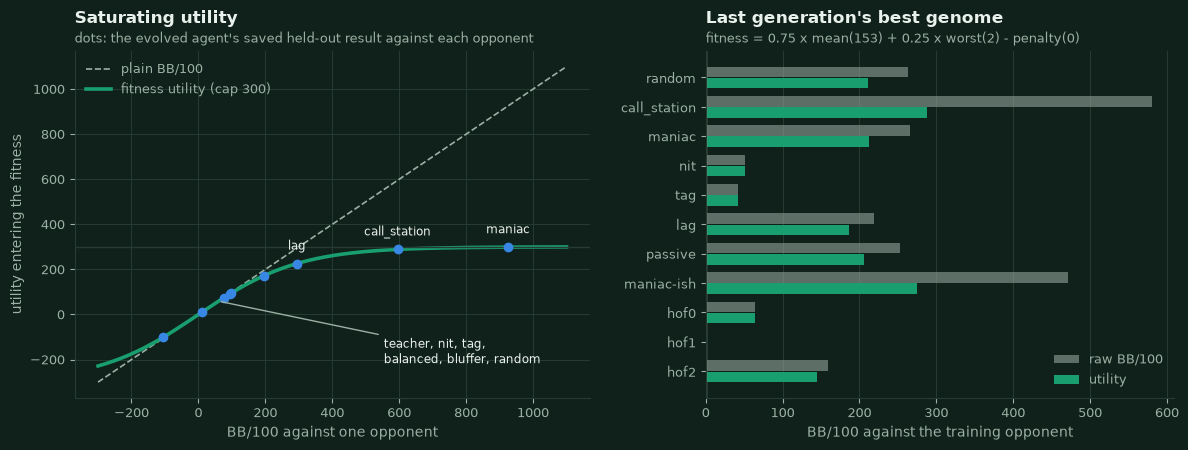

**[saved]** Recomputing the fitness of every generation's best genome from the stored per-opponent BB/100 with the package's utility and the blend above reproduces the saved `best_fitness` to within 2.8e-14 (max abs. difference over 40 generations). For the last generation's best genome the raw mean over its training opponents is +215 BB/100, but its fitness is 115: the saturation and the worst-case term (hof1: +2 BB/100) are what the selection actually sees.

In [7]:
fit_cfg = FitnessConfig(
    game=GAME,
    master_seed=run_cfg["seeds"]["master_seed"],
    training_opponents=training_pool(TRAIN["training_opponents"]),
    hands_per_evaluation=TRAIN["hands_per_evaluation"],
    equity_samples=meta["equity_samples"],
    worst_case_weight=TRAIN["fitness"]["worst_case_weight"],
    profit_saturation=TRAIN["fitness"]["profit_saturation_bb100"],
    max_all_in_share=TRAIN["fitness"]["max_all_in_share"],
    min_vpip=TRAIN["fitness"]["min_vpip"],
    degeneracy_penalty=TRAIN["fitness"]["degeneracy_penalty_bb100"],
)
fitness_fn = PokerFitness(fit_cfg, MatchRunner(1))  # nothing is simulated here: only its saturating utility is used
utility = lambda x: fitness_fn._utility(x)  # noqa: E731 - the package function that scores one opponent
CAP, W = fit_cfg.profit_saturation, fit_cfg.worst_case_weight

# the fitness formula, recomputed from the per-opponent numbers stored for each generation's best genome
SPECIAL = {"raw_mean_bb100", "worst_bb100", "penalty"}
recomputed = []
for record in history_json:
    per_opponent = {k: v for k, v in record["best_details"].items() if k not in SPECIAL}
    u = np.array([utility(v) for v in per_opponent.values()])
    recomputed.append((1 - W) * u.mean() + W * u.min() - record["best_details"]["penalty"])
max_error = float(np.max(np.abs(np.array(recomputed) - history["best_fitness"].to_numpy())))

last = history_json[-1]["best_details"]
opp_last = {k: v for k, v in last.items() if k not in SPECIAL}
u_last = {k: utility(v) for k, v in opp_last.items()}
final_eval = FINAL["results"]["evolved"]
final_opponents = list(FINAL["opponents"])

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12.0, 4.6), gridspec_kw={"width_ratios": [1.1, 1.0]})
xs = np.linspace(-300, 1100, 300)
ax.plot(xs, xs, color=nbp.MUTED, linestyle="--", linewidth=1.2, label="plain BB/100")
ax.plot(xs, [utility(x) for x in xs], color=nbp.ACCENT, linewidth=2.6, label=f"fitness utility (cap {CAP:.0f})")
ax.axhline(CAP, color=nbp.GRID, linewidth=1.0)
cluster = [n for n in final_opponents if abs(final_eval[n]["bb_per_100"]) < 200]  # too close together to label one by one
for name in final_opponents:
    x = final_eval[name]["bb_per_100"]
    ax.plot(x, utility(x), "o", color=nbp.SERIES[1], markersize=6, zorder=3)
    if name not in cluster:
        ax.annotate(name, (x, utility(x)), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=8.5, color=nbp.TEXT)
cluster_text = "\n".join(textwrap.wrap(", ".join(sorted(cluster, key=lambda n: final_eval[n]["bb_per_100"])), 26))
ax.annotate(cluster_text, (60, utility(60)), xytext=(0.60, 0.10), textcoords="axes fraction", fontsize=8.5, color=nbp.TEXT,
            arrowprops={"arrowstyle": "-", "color": nbp.MUTED})  # fmt: skip
ax.set_xlabel("BB/100 against one opponent")
ax.set_ylabel("utility entering the fitness")
nbp.title(ax, "Saturating utility", "dots: the evolved agent's saved held-out result against each opponent")
ax.legend(loc="upper left")

names = list(opp_last)
y = np.arange(len(names))
ax2.barh(y - 0.19, [opp_last[n] for n in names], height=0.36, color=nbp.MUTED, alpha=0.55, label="raw BB/100")
ax2.barh(y + 0.19, [u_last[n] for n in names], height=0.36, color=nbp.ACCENT, label="utility")
ax2.set_yticks(y, names)
ax2.invert_yaxis()
ax2.axvline(0, color=nbp.MUTED, linewidth=1.0)
ax2.grid(axis="y", visible=False)
ax2.set_xlabel("BB/100 against the training opponent")
mean_u, worst_u = np.mean(list(u_last.values())), min(u_last.values())
nbp.title(ax2, "Last generation's best genome", f"fitness = {1 - W:.2f} x mean({mean_u:.0f}) + {W:.2f} x worst({worst_u:.0f}) - penalty({last['penalty']:.0f})")
ax2.legend(loc="lower right")
fig.tight_layout()
nbp.savefig("nb03_fitness_design", fig)
plt.show()
display(Markdown(
    f"**[saved]** Recomputing the fitness of every generation's best genome from the stored per-opponent BB/100 with the package's "
    f"utility and the blend above reproduces the saved `best_fitness` to within {max_error:.1e} (max abs. difference over "
    f"{len(history_json)} generations). For the last generation's best genome the raw mean over its training opponents is "
    f"{last['raw_mean_bb100']:+.0f} BB/100, but its fitness is {history['best_fitness'].iloc[-1]:.0f}: the saturation and the worst-case term "
    f"({min(opp_last, key=opp_last.get)}: {min(opp_last.values()):+.0f} BB/100) are what the selection actually sees."
))

### 3.1 Why duplicate deals: a real variance experiment `[fresh]`

We play the evolved agent against four opponents in two ways with the same engine and the same agents:
**duplicate** (each deal played at two independent tables with the seats complemented - the current protocol) and **independent** deals
(a new deal per hand, button alternating).
Each scheme is cut into independent sessions of fixed length and we compare the spread of the *session BB/100 estimates*.
Duplicate dealing cancels *card* luck; it cannot cancel the luck that comes from an opponent's own random decisions,
so the gain should depend on who the opponent is.

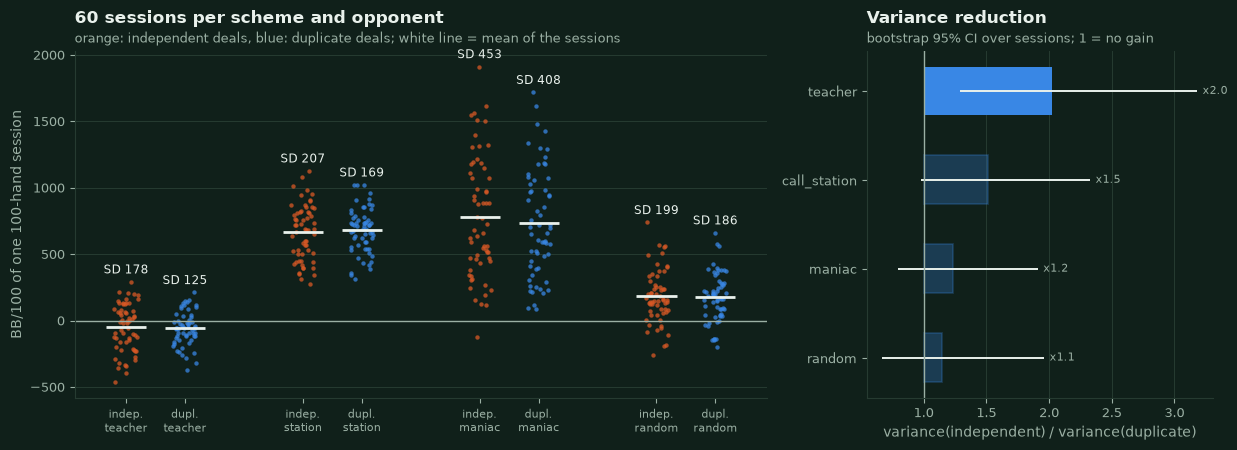

**[fresh]** (35s)

* vs **teacher**: SD of a 100-hand estimate 178 BB/100 (independent deals) -> 125 (duplicate); variance ratio x2.0 (95% CI 1.3-3.2)
* vs **call_station**: SD of a 100-hand estimate 207 BB/100 (independent deals) -> 169 (duplicate); variance ratio x1.5 (95% CI 1.0-2.3)
* vs **maniac**: SD of a 100-hand estimate 453 BB/100 (independent deals) -> 408 (duplicate); variance ratio x1.2 (95% CI 0.8-1.9)
* vs **random**: SD of a 100-hand estimate 199 BB/100 (independent deals) -> 186 (duplicate); variance ratio x1.1 (95% CI 0.7-2.0)

In [8]:
SILENT = KeepHandsPolicy(first=0, biggest_pots=0, biggest_wins_each=0)
VARIANCE_OPPONENTS = ("teacher", "call_station", "maniac", "random")


def session_bb100(opponent: str, duplicate: bool) -> np.ndarray:
    """BB/100 of the evolved agent in each independent session (``run_match``: sessions get fresh agents)."""
    match_cfg = MatchConfig(
        game=GAME, num_hands=VARIANCE_SESSIONS * VARIANCE_SESSION_HANDS, seed=EVAL_SEED, duplicate=duplicate,
        session_hands=VARIANCE_SESSION_HANDS, n_workers=N_WORKERS, keep_hands=SILENT,
    )  # fmt: skip
    result = run_match(EVOLVED_SPEC, AgentSpec(opponent, label=opponent), match_cfg)
    sign = 1.0 if result.label_a == "evolved" else -1.0  # the alphabetically first label is agent A
    chips = result.arrays.profit_chips.astype(float).reshape(VARIANCE_SESSIONS, VARIANCE_SESSION_HANDS).sum(axis=1)
    return sign * 100.0 * chips / GAME.big_blind / VARIANCE_SESSION_HANDS


started = time.perf_counter()
variance = {(opp, dup): session_bb100(opp, dup) for opp in VARIANCE_OPPONENTS for dup in (False, True)}
boot_rng = np.random.default_rng(DEMO_SEED)


def variance_ratio_ci(plain: np.ndarray, paired: np.ndarray, n_boot: int = 4000) -> tuple[float, float, float]:
    ratios = [
        np.var(boot_rng.choice(plain, len(plain)), ddof=1) / np.var(boot_rng.choice(paired, len(paired)), ddof=1)
        for _ in range(n_boot)
    ]
    point = np.var(plain, ddof=1) / np.var(paired, ddof=1)
    return point, *np.percentile(ratios, [2.5, 97.5])


ratios = {opp: variance_ratio_ci(variance[opp, False], variance[opp, True]) for opp in VARIANCE_OPPONENTS}

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [2.0, 1]})
jitter = np.random.default_rng(DEMO_SEED)
positions, labels = [], []
for i, opp in enumerate(VARIANCE_OPPONENTS):
    for j, dup in enumerate((False, True)):
        values, x = variance[opp, dup], i * 3 + j
        ax.scatter(x + jitter.uniform(-0.2, 0.2, len(values)), values, s=10, color=nbp.SERIES[1] if dup else nbp.SERIES[2], alpha=0.75, linewidths=0)
        ax.hlines(values.mean(), x - 0.34, x + 0.34, color=nbp.TEXT, linewidth=2)
        ax.annotate(f"SD {values.std(ddof=1):.0f}", (x, values.max()), xytext=(0, 6), textcoords="offset points", ha="center", color=nbp.TEXT, fontsize=8.5)
        positions.append(x)
        labels.append(f"{'dupl.' if dup else 'indep.'}\n{opp.replace('call_station', 'station')}")
ax.set_xticks(positions, labels)
ax.tick_params(axis="x", labelsize=8)
ax.set_ylabel(f"BB/100 of one {VARIANCE_SESSION_HANDS}-hand session")
ax.axhline(0, color=nbp.MUTED, linewidth=1)
ax.grid(axis="x", visible=False)
nbp.title(ax, f"{VARIANCE_SESSIONS} sessions per scheme and opponent", "orange: independent deals, blue: duplicate deals; white line = mean of the sessions")
nbp.bar_with_ci(ax2, list(ratios), [r[0] for r in ratios.values()], [r[1] for r in ratios.values()], [r[2] for r in ratios.values()],
                colors=nbp.SERIES[1], horizontal=True, reference=1.0, value_format="x{:.1f}")  # fmt: skip
ax2.set_xlabel("variance(independent) / variance(duplicate)")
nbp.title(ax2, "Variance reduction", "bootstrap 95% CI over sessions; 1 = no gain")
fig.tight_layout()
nbp.savefig("nb03_duplicate_variance", fig)
plt.show()
lines = [
    f"* vs **{opp}**: SD of a {VARIANCE_SESSION_HANDS}-hand estimate {variance[opp, False].std(ddof=1):.0f} BB/100 (independent deals) -> "
    f"{variance[opp, True].std(ddof=1):.0f} (duplicate); variance ratio x{ratios[opp][0]:.1f} (95% CI {ratios[opp][1]:.1f}-{ratios[opp][2]:.1f})"
    for opp in VARIANCE_OPPONENTS
]
display(Markdown(f"**[fresh]** ({time.perf_counter() - started:.0f}s)\n\n" + "\n".join(lines)))

### 3.2 Why common random numbers: paired genome comparisons `[fresh]`

Within a generation every genome plays the same deals. To see what that buys *on top of* duplicate pairing, we evaluate two genomes
(evolved and the hand-made `tag`) against the same opponent in two ways: on the *same* deals (CRN, what the GA does) and on
*different* deals. The standard error of the **difference** between the two genomes is what decides whether the
ranking is signal or luck. (Sharing the deals is free and guarantees that two genomes are never ranked on different luck;
whether it also lowers the noise is what is measured.)

In [9]:
CRN_OPPONENT = "balanced"
tag_spec, opp_spec = preset_spec("tag"), preset_spec(CRN_OPPONENT)
crn = run_pairs(
    {
        "evolved": (EVOLVED_SPEC, opp_spec, CRN_PAIRS, (EVAL_SEED, "crn-same-deals")),
        "tag, same deals": (tag_spec, opp_spec, CRN_PAIRS, (EVAL_SEED, "crn-same-deals")),
        "tag, other deals": (tag_spec, opp_spec, CRN_PAIRS, (EVAL_SEED, "crn-other-deals")),
    }
)
to100 = lambda x: scale_to_bb_per_100(x, 2)  # noqa: E731 - BB per pair -> BB/100
x, y_same, y_other = to100(crn["evolved"]), to100(crn["tag, same deals"]), to100(crn["tag, other deals"])
n = len(x)
se_crn = float(np.std(x - y_same, ddof=1) / np.sqrt(n))
se_independent = float(np.sqrt(np.var(x, ddof=1) / n + np.var(y_other, ddof=1) / n))
rho = float(np.corrcoef(x, y_same)[0, 1])
crn_gain = (se_independent / se_crn) ** 2  # how many times fewer hands the shared deals save for the same precision
crn_reading = (
    f"the same ranking evidence costs {crn_gain:.1f}x fewer hands" if crn_gain >= 1.15
    else "sharing the deals made no measurable difference here" if crn_gain > 0.87
    else f"sharing the deals made it slightly worse here (x{crn_gain:.1f})"
)
crn_word = "a substantial gain" if crn_gain >= 1.5 else "a small gain" if crn_gain >= 1.15 else "no measurable gain"
display(Markdown(
    f"**[fresh]** evolved vs tag, both against `{CRN_OPPONENT}`, {CRN_PAIRS} duplicate pairs each:\n\n"
    f"* evolved {x.mean():+.0f} BB/100, tag {y_same.mean():+.0f} BB/100 (same deals); difference {x.mean() - y_same.mean():+.0f}.\n"
    f"* per-pair results of the two genomes on the same deals are correlated (r = {rho:.2f}).\n"
    f"* standard error of the difference: **{se_crn:.0f} BB/100 with shared deals (CRN)** vs {se_independent:.0f} BB/100 if the genomes had been "
    f"evaluated on different deals - {crn_reading}.\n"
))

**[fresh]** evolved vs tag, both against `balanced`, 400 duplicate pairs each:

* evolved +1 BB/100, tag -22 BB/100 (same deals); difference +23.
* per-pair results of the two genomes on the same deals are correlated (r = -0.03).
* standard error of the difference: **64 BB/100 with shared deals (CRN)** vs 60 BB/100 if the genomes had been evaluated on different deals - sharing the deals made it slightly worse here (x0.9).


### 3.3 Fresh deals per generation, and deals that nothing was trained on `[saved]` `[fresh]`

Training deals are seeded by `(master seed, generation, opponent index, pair)` in the `ga_fitness` namespace, validation
deals by `(master seed, "validation", ...)` and the final evaluation by `(master seed, "final", ...)` in `ga_validation`;
this notebook uses namespace `eval`. We regenerate those deals and count overlaps.

In [10]:
master = run_cfg["seeds"]["master_seed"]
N_CHECK = 100  # pairs per (generation, opponent) checked


def deal_set(namespace: str, *parts, pairs: int) -> set[tuple[str, ...]]:
    return {Deal.from_seed(derive_seed(namespace, *parts, "deal", p)).cards for p in range(pairs)}


train_deals = set().union(*(deal_set("ga_fitness", master, g, j, pairs=N_CHECK) for g in range(GA_CONFIG.generations) for j in range(len(TRAIN["training_opponents"]))))
valid_deals = set().union(*(deal_set("ga_validation", master, "validation", j, pairs=cfg["VALIDATION_PAIRS"]) for j in range(len(TRAIN["validation_opponents"]))))
final_deals = set().union(*(deal_set("ga_validation", master, "final", j, pairs=N_CHECK) for j in range(len(FINAL["opponents"]))))
eval_deals = set().union(*(deal_set("eval", EVAL_SEED, o, pairs=N_CHECK) for o in ("teacher", "balanced", "nit", "random")))
per_generation = [deal_set("ga_fitness", master, g, 0, pairs=N_CHECK) for g in range(GA_CONFIG.generations)]
shared_between_generations = sum(len(a & b) for i, a in enumerate(per_generation) for b in per_generation[i + 1 :])
overlap = {
    "training (all generations) vs validation": len(train_deals & valid_deals),
    "training vs final evaluation": len(train_deals & final_deals),
    "training vs this notebook's evaluation": len(train_deals & eval_deals),
    "validation vs this notebook's evaluation": len(valid_deals & eval_deals),
    "generation g vs generation g' (same opponent index)": shared_between_generations,
}
display(Markdown(
    f"Checked {len(train_deals):,} training, {len(valid_deals):,} validation, {len(final_deals):,} final-evaluation and {len(eval_deals):,} "
    f"notebook deals. Identical deals found:\n\n" + "\n".join(f"* {k}: **{v}**" for k, v in overlap.items())
))

Checked 32,000 training, 900 validation, 900 final-evaluation and 400 notebook deals. Identical deals found:

* training (all generations) vs validation: **0**
* training vs final evaluation: **0**
* training vs this notebook's evaluation: **0**
* validation vs this notebook's evaluation: **0**
* generation g vs generation g' (same opponent index): **0**

### 3.4 The teacher is excluded from training - by construction `[saved]`

`training_pool()` refuses trained or supervised agents, so the claim "the GA never saw the teacher" does not depend on
a configuration value being right:

In [11]:
try:
    training_pool(["random", "teacher"])
except ValueError as error:
    display(Markdown(f"`training_pool(['random', 'teacher'])` raises `ValueError`: *{error}*"))
held_out = [o for o, flag in FINAL["opponents"].items() if not flag["in_training_pool"]]
display(Markdown(
    f"* training pool: {', '.join(TRAIN['training_opponents'])} (+ hall of fame)\n"
    f"* held-out opponents of the final evaluation (not in the pool): **{', '.join(held_out)}** "
    f"(`{', '.join(HELD_OUT_PRESETS)}` are hand-made styles reserved for held-out use; `teacher` is the supervised learners' label source)\n"
    f"* the other final-evaluation opponents are in the training pool, but the *deals* are always new."
))

`training_pool(['random', 'teacher'])` raises `ValueError`: *'teacher' may not be in the GA training pool: only ('random', 'call_station', 'maniac') and GA presets ['balanced', 'bluffer', 'lag', 'maniac-ish', 'nit', 'passive', 'tag'] are allowed (trained agents are held-out opponents).*

* training pool: random, call_station, maniac, nit, tag, lag, passive, maniac-ish (+ hall of fame)
* held-out opponents of the final evaluation (not in the pool): **teacher, balanced, bluffer** (`balanced, bluffer` are hand-made styles reserved for held-out use; `teacher` is the supervised learners' label source)
* the other final-evaluation opponents are in the training pool, but the *deals* are always new.

### 3.5 The duplicate protocol: this GA was trained with the legacy single-table version `[saved]` `[fresh]`

**The committed GA was trained - and every per-generation number in section 5 was recorded - under the legacy single-table duplicate protocol.**
There, the two plays of a deal were consecutive hands of one game with the same agents and the same opponent trackers, so for agents that adapt to
opponent statistics (the teacher, the evolved genome through its two adaptation genes, `balanced`, `bluffer`) the second play of a deal was
played against an opponent model that already contained the first play of the *same* deal: a small systematic information advantage that identical adaptive agents do not cancel
(Notebook 4, section 6.2, measures it with two identical Teachers). The package now plays every duplicate match at **two independent tables**
(own agent copies and opponent trackers, same deals, seats complemented) by default - `pair_results`, `run_match`, the tournament and the GA fitness itself (`protocol="single_table"` is the legacy option) -
so everything marked `[fresh]` here and the `final_evaluation` in `metadata.json` (recomputed with `train_ga.py --evaluate-only`) use the two-table protocol.
The genome was **not retrained**, and its metadata does not record which protocol trained it.

Two checks of whether this changes the conclusions: **(a)** the artifact itself, with two identical copies of the evolved genome (and of the teacher) playing each other,
and **(b)** a replay of the evolved genome's saved final evaluation (same deals, same opponents) under both protocols, compared pair by pair.

In [12]:
AA_SPECS = {
    "evolved genome": (AgentSpec("ga", {}, label="evolved-a"), AgentSpec("ga", {}, label="evolved-b")),
    "teacher": (AgentSpec("teacher", label="teacher-a"), AgentSpec("teacher", label="teacher-b")),
}
started = time.perf_counter()
aa = run_pairs({(name, protocol): (a, b, AA_PAIRS, (EVAL_SEED, "aa", name), protocol) for name, (a, b) in AA_SPECS.items() for protocol in (SINGLE_TABLE, TWO_TABLE)})
aa_results = {key: summarize(AA_SPECS[key[0]][0].label, AA_SPECS[key[0]][1].label, pairs) for key, pairs in aa.items()}
aa_words = {"wins": "first-named copy WINS", "loses": "first-named copy LOSES", "no significant difference": "no significant difference"}
display(Markdown(
    f"**(a) Identical agents against each other, {AA_PAIRS} duplicate pairs each `[fresh]`.** Two identical copies must come out at 0 BB/100; the number is the first-named copy's result:\n\n"
    "| agent | legacy single-table | two-table |\n|---|---|---|\n"
    + "\n".join(
        f"| {name} | " + " | ".join(
            f"{ci_text(r.bb_per_100, r.ci_low, r.ci_high)} ({aa_words[verdict(r.ci_low, r.ci_high)]})"
            for r in (aa_results[name, SINGLE_TABLE], aa_results[name, TWO_TABLE])
        ) + " |"
        for name in AA_SPECS
    )
    + f"\n\nLargest |pair sum| of the two copies of the deterministic teacher under the two-table protocol: {np.abs(aa['teacher', TWO_TABLE]).max():.1f} BB "
    "(a pair sum of 0 in every pair means the two tables mirror each other exactly; the evolved genome draws random bluff and sizing coins, so its copies cancel only in expectation)."
))

**(a) Identical agents against each other, 4000 duplicate pairs each `[fresh]`.** Two identical copies must come out at 0 BB/100; the number is the first-named copy's result:

| agent | legacy single-table | two-table |
|---|---|---|
| evolved genome | +1 [-22, +24] (no significant difference) | -14 [-38, +11] (no significant difference) |
| teacher | -30 [-49, -11] (first-named copy LOSES) | +0 [+0, +0] (no significant difference) |

Largest |pair sum| of the two copies of the deterministic teacher under the two-table protocol: 0.0 BB (a pair sum of 0 in every pair means the two tables mirror each other exactly; the evolved genome draws random bluff and sizing coins, so its copies cancel only in expectation).

In [13]:
replay_opponents = tuple(opponent_from_name(name) for name in FINAL["opponents"])
with MatchRunner(N_WORKERS) as runner:
    replay = {
        protocol: PokerFitness(replace(fit_cfg, protocol=protocol), runner).play_against(
            [EVOLVED.to_vector()], replay_opponents, VALIDATION_NAMESPACE, FINAL_LABEL, PROTOCOL_PAIRS
        )[0]
        for protocol in (SINGLE_TABLE, TWO_TABLE)
    }
rows, paired_shift, replay_estimates, same_verdict = [], {}, {}, 0
for j, opponent in enumerate(FINAL["opponents"]):
    per_protocol = {p: scale_to_bb_per_100(np.asarray(replay[p][j].pair_profits, dtype=float) / GAME.big_blind, 2) for p in replay}
    estimates = {p: t_estimate(values) for p, values in per_protocol.items()}
    replay_estimates[opponent] = estimates
    shift = t_estimate(per_protocol[SINGLE_TABLE] - per_protocol[TWO_TABLE])  # same deals, paired per pair
    paired_shift[opponent] = shift
    legacy_word, two_word = (verdict(estimates[p].ci_low, estimates[p].ci_high) for p in (SINGLE_TABLE, TWO_TABLE))
    same_verdict += legacy_word == two_word
    rows.append(
        {
            "opponent": f"`{opponent}`" + ("" if FINAL["opponents"][opponent]["in_training_pool"] else " (held out)"),
            "legacy single-table": ci_text(estimates[SINGLE_TABLE].mean, estimates[SINGLE_TABLE].ci_low, estimates[SINGLE_TABLE].ci_high),
            "two-table": ci_text(estimates[TWO_TABLE].mean, estimates[TWO_TABLE].ci_low, estimates[TWO_TABLE].ci_high),
            "paired difference (legacy - two-table)": ci_text(shift.mean, shift.ci_low, shift.ci_high),
            "same verdict": "yes" if legacy_word == two_word else f"no ({legacy_word} / {two_word})",
        }
    )
average_shift = pool_groups([scale_to_bb_per_100(np.asarray(replay[SINGLE_TABLE][j].pair_profits, dtype=float) / GAME.big_blind, 2)
                             - scale_to_bb_per_100(np.asarray(replay[TWO_TABLE][j].pair_profits, dtype=float) / GAME.big_blind, 2)
                             for j in range(len(replay_opponents))], weighting="equal")  # fmt: skip
largest = max(paired_shift.items(), key=lambda item: abs(item[1].mean))
n_resolved = sum(e.ci_low > 0 or e.ci_high < 0 for e in paired_shift.values())
replay_seconds = time.perf_counter() - started
display(Markdown(
    f"**(b) Replay of the saved final evaluation `[fresh]` ({replay_seconds:.0f} s).** The evolved genome against the nine saved final-evaluation opponents on the saved final deals "
    f"(first {PROTOCOL_PAIRS} pairs of each), played under both protocols; the difference is computed per pair on identical deals. "
    f"The verdict (wins / loses / no significant difference) is the same under both protocols for {same_verdict} of {len(rows)} opponents; "
    f"the paired difference is resolvable (CI excludes 0) for {n_resolved}; largest shift: {largest[1].mean:+.0f} BB/100 against `{largest[0]}`; "
    f"average over the nine opponents (equal weight) {ci_text(average_shift.mean, average_shift.ci_low, average_shift.ci_high)} BB/100."
))
display(md_table(pd.DataFrame(rows)))

**(b) Replay of the saved final evaluation `[fresh]` (59 s).** The evolved genome against the nine saved final-evaluation opponents on the saved final deals (first 800 pairs of each), played under both protocols; the difference is computed per pair on identical deals. The verdict (wins / loses / no significant difference) is the same under both protocols for 9 of 9 opponents; the paired difference is resolvable (CI excludes 0) for 0; largest shift: -80 BB/100 against `random`; average over the nine opponents (equal weight) -17 [-46, +12] BB/100.

| opponent | legacy single-table | two-table | paired difference (legacy - two-table) | same verdict |
|---|---|---|---|---|
| `random` | +153 [+51, +255] | +233 [+130, +336] | -80 [-218, +58] | yes |
| `call_station` | +581 [+499, +662] | +570 [+488, +652] | +11 [-54, +76] | yes |
| `maniac` | +939 [+761, +1116] | +937 [+760, +1114] | +2 [-126, +130] | yes |
| `teacher` (held out) | -153 [-219, -87] | -117 [-183, -50] | -36 [-92, +19] | yes |
| `balanced` (held out) | +81 [+11, +150] | +85 [+11, +159] | -4 [-77, +69] | yes |
| `bluffer` (held out) | +105 [+35, +175] | +129 [+53, +205] | -24 [-95, +48] | yes |
| `nit` | -20 [-60, +19] | -2 [-40, +36] | -18 [-60, +24] | yes |
| `tag` | +81 [+12, +151] | +103 [+33, +172] | -21 [-91, +49] | yes |
| `lag` | +288 [+188, +387] | +271 [+171, +371] | +16 [-85, +117] | yes |

## 4. Selection, crossover and mutation `[demo]`

The functions below are the *real* operators of `poker_arena.training.ga` - the code the evolutionary loop calls -
run on their own so that each step can be inspected. The random generator is seeded with `DEMO_SEED`.

### 4.1 Crossover: two parents -> children

* **BLX-alpha** (the setting of the run): every child gene is drawn uniformly from the parents' interval *widened* by
  alpha on each side, then clipped into the gene bounds - children can land slightly outside both parents.
* **Uniform**: every child gene is copied from parent A or parent B with equal probability.

Parents here: the hand-made `tag` and `lag` (both are in the initial population).

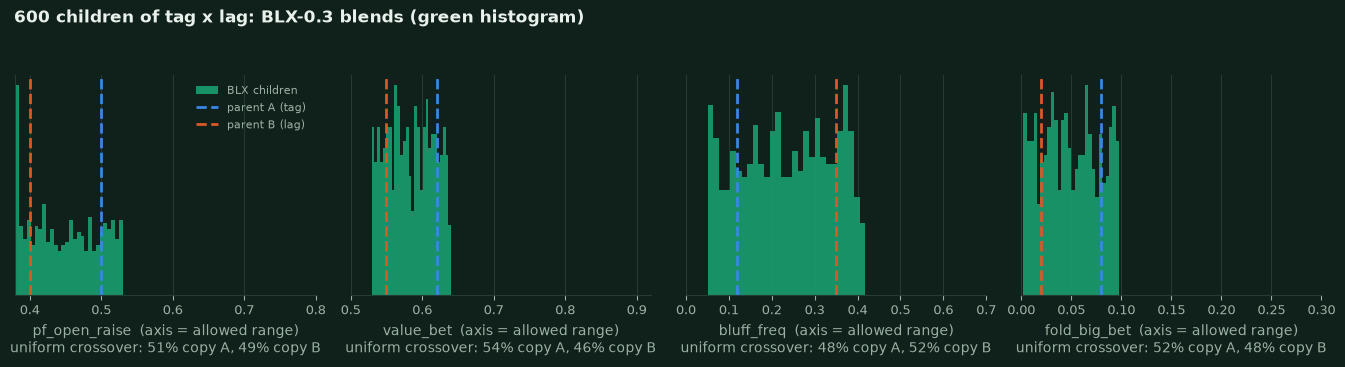

One concrete child of each kind (gene by gene). In 33% of all BLX child genes the value falls *outside* the interval spanned by the parents - that is the extrapolation uniform crossover cannot do:

| gene | parent A (tag) | parent B (lag) | BLX child | uniform child | uniform took |
|---|---|---|---|---|---|
| `pf_play_btn` | 0.420 | 0.350 | 0.399 | 0.350 | B |
| `pf_open_raise` | 0.500 | 0.400 | 0.514 | 0.500 | A |
| `pf_bb_raise` | 0.580 | 0.480 | 0.574 | 0.480 | B |
| `pf_defend` | 0.500 | 0.420 | 0.425 | 0.420 | B |
| `pf_3bet` | 0.680 | 0.580 | 0.598 | 0.580 | B |
| `pf_shove` | 0.800 | 0.750 | 0.805 | 0.750 | B |
| `value_bet` | 0.620 | 0.550 | 0.530 | 0.620 | A |
| `value_raise` | 0.780 | 0.700 | 0.781 | 0.780 | A |
| `shove_threshold` | 0.920 | 0.880 | 0.919 | 0.920 | A |
| `call_margin` | 0.030 | -0.020 | 0.002 | -0.020 | B |
| `fold_big_bet` | 0.080 | 0.020 | 0.031 | 0.080 | A |
| `deep_stack_caution` | 0.040 | 0.000 | 0.006 | 0.040 | A |
| `position_bonus` | 0.030 | 0.060 | 0.033 | 0.060 | B |
| `bluff_freq` | 0.120 | 0.350 | 0.215 | 0.120 | A |
| `semi_bluff_freq` | 0.500 | 0.850 | 0.678 | 0.850 | B |
| `big_bet_prob` | 0.350 | 0.550 | 0.467 | 0.350 | A |
| `adapt_fold` | 0.300 | 0.300 | 0.300 | 0.300 | A |
| `adapt_aggression` | 0.000 | 0.000 | 0.000 | 0.000 | A |

In [14]:
demo_rng = np.random.default_rng(DEMO_SEED)
parent_a, parent_b = PRESETS["tag"].to_vector(), PRESETS["lag"].to_vector()
N_CHILDREN = 600
blx_children = np.array([blx_crossover(parent_a, parent_b, GA_CONFIG.blx_alpha, BOUNDS, demo_rng) for _ in range(N_CHILDREN)])
uniform_children = np.array([uniform_crossover(parent_a, parent_b, demo_rng) for _ in range(N_CHILDREN)])

SHOWN_GENES = ["pf_open_raise", "value_bet", "bluff_freq", "fold_big_bet"]
fig, axes = plt.subplots(1, len(SHOWN_GENES), figsize=(13.5, 3.7))
for ax, gene in zip(axes, SHOWN_GENES):
    k = GENE_NAMES.index(gene)
    ax.hist(blx_children[:, k], bins=28, color=nbp.ACCENT, alpha=0.9, label="BLX children")
    ax.axvline(parent_a[k], color=nbp.SERIES[1], linestyle="--", linewidth=2, label="parent A (tag)")
    ax.axvline(parent_b[k], color=nbp.SERIES[2], linestyle="--", linewidth=2, label="parent B (lag)")
    ax.set_xlim(GENE_LOWS[k], GENE_HIGHS[k])
    ax.set_yticks([])
    copies_a = float(np.mean(uniform_children[:, k] == parent_a[k]))
    ax.set_xlabel(f"{gene}  (axis = allowed range)\nuniform crossover: {copies_a:.0%} copy A, {1 - copies_a:.0%} copy B")
axes[0].legend(loc="upper right", fontsize=8)
fig.suptitle(f"{N_CHILDREN} children of tag x lag: BLX-{GA_CONFIG.blx_alpha} blends (green histogram)", x=0.01, ha="left", fontsize=12, fontweight="bold", color=nbp.TEXT)
fig.tight_layout(rect=(0, 0, 1, 0.93))
nbp.savefig("nb03_operators_crossover", fig)
plt.show()

low, high = np.minimum(parent_a, parent_b), np.maximum(parent_a, parent_b)
outside = float(np.mean((blx_children < low - 1e-12) | (blx_children > high + 1e-12)))
example = pd.DataFrame(
    {
        "gene": [f"`{n}`" for n in GENE_NAMES],
        "parent A (tag)": parent_a,
        "parent B (lag)": parent_b,
        "BLX child": blx_children[0],
        "uniform child": uniform_children[0],
        "uniform took": ["A" if c == a else "B" for c, a in zip(uniform_children[0], parent_a)],
    }
)
display(Markdown(f"One concrete child of each kind (gene by gene). In {outside:.0%} of all BLX child genes the value falls *outside* the interval spanned by the parents - that is the extrapolation uniform crossover cannot do:"))
display(md_table(example))

### 4.2 Gaussian mutation and its decaying step size

Each gene of a child is perturbed with probability `mutation_rate` by a Gaussian whose standard deviation is
`mutation_scale` x the gene's range, then clipped into the bounds. The scale shrinks linearly during the run
(large early steps explore, small late steps refine). Demo: 5000 mutants of the evolved genome at three stages of the run.

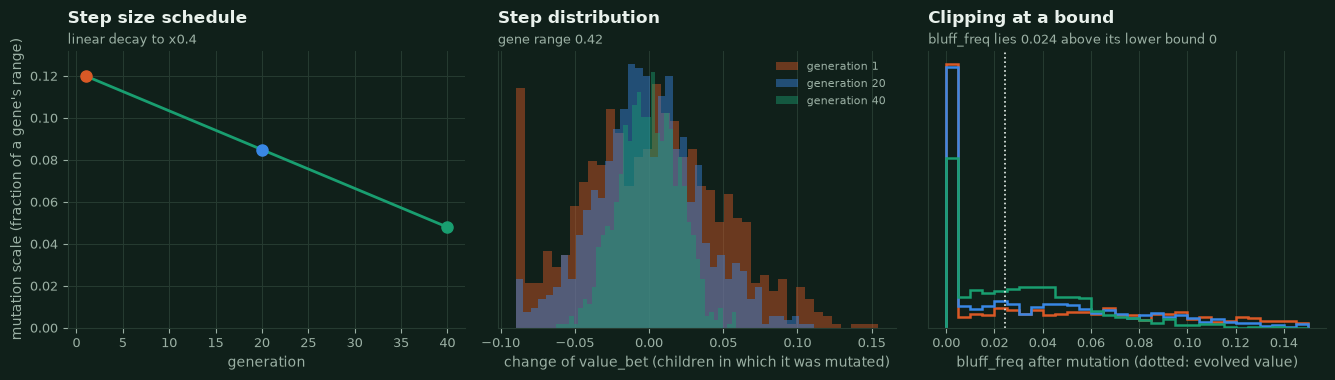

With rate 0.2 on 18 genes a child has on average 3.6 perturbed genes (expected 3.6). A gene sitting close to a bound is *clipped onto it* by a large share of its mutations: of the children whose `bluff_freq` was mutated, 37% end exactly at 0 in generation 1, 35% end exactly at 0 in generation 20, 22% end exactly at 0 in generation 40.

In [15]:
stage_generations = {"generation 1": 0, f"generation {GA_CONFIG.generations // 2}": GA_CONFIG.generations // 2 - 1, f"generation {GA_CONFIG.generations}": GA_CONFIG.generations - 1}
base = EVOLVED.to_vector()
mutants = {
    name: np.array([gaussian_mutation(base, GA_CONFIG.mutation_rate, mutation_scale_at(GA_CONFIG, g), BOUNDS, demo_rng) for _ in range(5000)])
    for name, g in stage_generations.items()
}
stage_colors = dict(zip(stage_generations, (nbp.SERIES[2], nbp.SERIES[1], nbp.ACCENT)))
k_step, k_bluff = GENE_NAMES.index("value_bet"), GENE_NAMES.index("bluff_freq")

fig, (ax, ax2, ax3) = plt.subplots(1, 3, figsize=(13.5, 3.9))
generations_axis = np.arange(1, GA_CONFIG.generations + 1)
ax.plot(generations_axis, [mutation_scale_at(GA_CONFIG, g) for g in range(GA_CONFIG.generations)], color=nbp.ACCENT)
for name, g in stage_generations.items():
    ax.plot(g + 1, mutation_scale_at(GA_CONFIG, g), "o", color=stage_colors[name], markersize=8)
ax.set_xlabel("generation")
ax.set_ylabel("mutation scale (fraction of a gene's range)")
ax.set_ylim(0, GA_CONFIG.mutation_scale * 1.1)
nbp.title(ax, "Step size schedule", f"linear decay to x{GA_CONFIG.mutation_end_factor}")
for name, values in mutants.items():
    changed = values[:, k_step] != base[k_step]
    ax2.hist(values[changed, k_step] - base[k_step], bins=40, histtype="stepfilled", alpha=0.45, color=stage_colors[name], label=name)
ax2.set_yticks([])
ax2.set_xlabel("change of value_bet (children in which it was mutated)")
ax2.legend(fontsize=8)
nbp.title(ax2, "Step distribution", f"gene range {SPAN[k_step]:.2f}")
for name, values in mutants.items():
    changed = values[:, k_bluff] != base[k_bluff]
    ax3.hist(values[changed, k_bluff], bins=np.linspace(GENE_LOWS[k_bluff], GENE_LOWS[k_bluff] + 0.15, 31), histtype="step", linewidth=1.8, color=stage_colors[name], label=name)
ax3.axvline(base[k_bluff], color=nbp.TEXT, linestyle=":", linewidth=1.2)
ax3.set_yticks([])
ax3.set_xlabel("bluff_freq after mutation (dotted: evolved value)")
nbp.title(ax3, "Clipping at a bound", f"bluff_freq lies {base[k_bluff] - GENE_LOWS[k_bluff]:.3f} above its lower bound 0")
fig.tight_layout()
nbp.savefig("nb03_operators_mutation", fig)
plt.show()
changed_per_child = {name: float(np.mean(np.sum(values != base, axis=1))) for name, values in mutants.items()}
clipped = {name: float(np.sum(values[:, k_bluff] == GENE_LOWS[k_bluff]) / np.sum(values[:, k_bluff] != base[k_bluff])) for name, values in mutants.items()}
display(Markdown(
    f"With rate {GA_CONFIG.mutation_rate} on {len(GENE_NAMES)} genes a child has on average {np.mean(list(changed_per_child.values())):.1f} perturbed genes "
    f"(expected {GA_CONFIG.mutation_rate * len(GENE_NAMES):.1f}). A gene sitting close to a bound is *clipped onto it* by a large share of its mutations: "
    "of the children whose `bluff_freq` was mutated, " + ", ".join(f"{clipped[n]:.0%} end exactly at 0 in {n}" for n in mutants) + "."
))

### 4.3 Tournament selection and selection pressure

A parent is the winner of a small tournament among `tournament_size` genomes drawn at random: size 1 is blind
choice, larger tournaments favour the fittest ever more strongly. The demo uses the *saved* training fitness of the final
population (sorted best first, so the index is the rank) and draws 20,000 parents per tournament size.

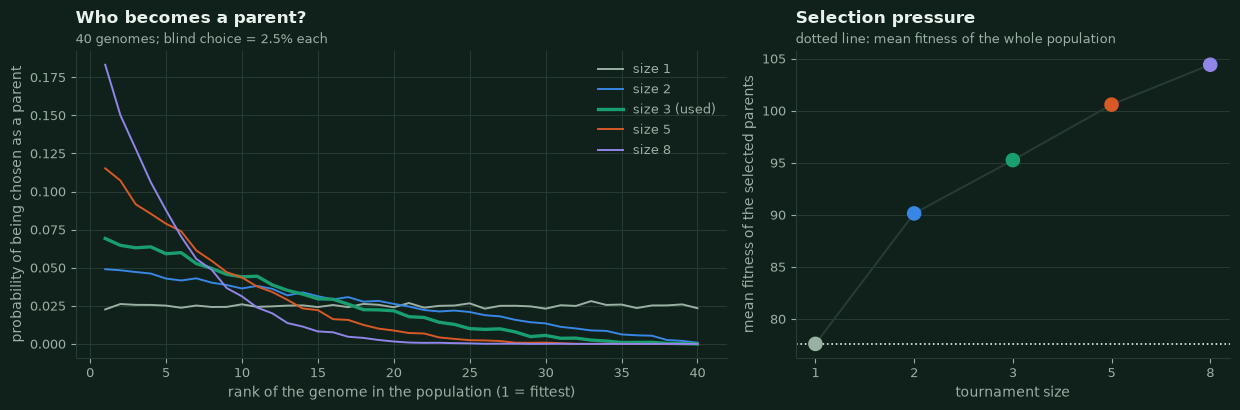

| tournament size | P(fittest is chosen), simulated | P(fittest is chosen), theory 1-(1-1/n)^k | share of parents from the better half | mean parent fitness |
|---|---|---|---|---|
| 1 | 0.023 | 0.025 | 0.498 | 77.614 |
| 2 | 0.049 | 0.049 | 0.747 | 90.144 |
| 3 | 0.069 | 0.073 | 0.875 | 95.258 |
| 5 | 0.115 | 0.119 | 0.969 | 100.591 |
| 8 | 0.183 | 0.183 | 0.996 | 104.420 |

In [16]:
population_fitness = np.array(pop_doc["fitness"])  # [saved] fitness of the final population, best first
n_pop = len(population_fitness)
sizes = (1, 2, 3, 5, 8)
draws = {k: tournament_select(population_fitness, k, 20_000, demo_rng) for k in sizes}
rank_share = {k: np.bincount(draws[k], minlength=n_pop) / len(draws[k]) for k in sizes}
size_colors = dict(zip(sizes, (nbp.MUTED, nbp.SERIES[1], nbp.ACCENT, nbp.SERIES[2], nbp.SERIES[3])))

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
for k in sizes:
    ax.plot(np.arange(1, n_pop + 1), rank_share[k], color=size_colors[k], linewidth=2.4 if k == GA_CONFIG.tournament_size else 1.4, label=f"size {k}" + (" (used)" if k == GA_CONFIG.tournament_size else ""))
ax.set_xlabel("rank of the genome in the population (1 = fittest)")
ax.set_ylabel("probability of being chosen as a parent")
nbp.title(ax, "Who becomes a parent?", f"{n_pop} genomes; blind choice = {1 / n_pop:.1%} each")
ax.legend()
mean_parent = [float(population_fitness[draws[k]].mean()) for k in sizes]
ax2.axhline(population_fitness.mean(), color=nbp.TEXT, linestyle=":", linewidth=1.2)
ax2.plot(range(len(sizes)), mean_parent, color=nbp.GRID, linewidth=1.5, zorder=1)
ax2.scatter(range(len(sizes)), mean_parent, s=90, color=[size_colors[k] for k in sizes], zorder=3)
ax2.set_xticks(range(len(sizes)), [str(k) for k in sizes])
ax2.set_xlabel("tournament size")
ax2.set_ylabel("mean fitness of the selected parents")
ax2.grid(axis="x", visible=False)
nbp.title(ax2, "Selection pressure", "dotted line: mean fitness of the whole population")
fig.tight_layout()
nbp.savefig("nb03_operators_selection", fig)
plt.show()
table = pd.DataFrame(
    {
        "tournament size": sizes,
        "P(fittest is chosen), simulated": [rank_share[k][0] for k in sizes],
        "P(fittest is chosen), theory 1-(1-1/n)^k": [1 - (1 - 1 / n_pop) ** k for k in sizes],
        "share of parents from the better half": [float(np.mean(draws[k] < n_pop / 2)) for k in sizes],
        "mean parent fitness": mean_parent,
    }
)
display(md_table(table))

### 4.4 One generation, assembled

`next_generation` combines the operators: the best `elite_count` genomes are copied unchanged, the offspring are
made by tournament selection + crossover + mutation, and a few fresh random *immigrants* keep exploring. Applied to the saved
final population (its saved fitness) with the run's configuration:

In [17]:
final_population = np.array(pop_doc["population"])
next_population = next_generation(final_population, population_fitness, GA_CONFIG, GA_CONFIG.generations - 1, BOUNDS, demo_rng)
n_elite, n_immigrant = GA_CONFIG.elite_count, GA_CONFIG.immigrant_count
parts = {
    "elites (copied)": next_population[:n_elite],
    "offspring (select + cross + mutate)": next_population[n_elite : len(next_population) - n_immigrant],
    "random immigrants": next_population[len(next_population) - n_immigrant :],
}


def nearest_parent_distance(vector: np.ndarray) -> float:
    """Mean per-gene distance (fraction of the range) to the closest genome of the old population."""
    return float(np.min(np.mean(np.abs(final_population - vector) / SPAN, axis=1)))


anatomy = pd.DataFrame(
    {
        "part": list(parts),
        "genomes": [len(v) for v in parts.values()],
        "mean distance to the nearest old genome": [float(np.mean([nearest_parent_distance(x) for x in v])) for v in parts.values()],
    }
)
display(md_table(anatomy))
display(Markdown(
    f"Diversity (mean per-gene standard deviation / range; 0 = clones, about 0.29 = uniform random): "
    f"old population **{population_diversity(final_population, BOUNDS):.3f}** -> next population **{population_diversity(next_population, BOUNDS):.3f}**. "
    f"Offspring stay close to their parents (small mutation step at the end of the run) while immigrants are about as far from the population as random genomes are."
))

| part | genomes | mean distance to the nearest old genome |
|---|---|---|
| elites (copied) | 2 | 0.000 |
| offspring (select + cross + mutate) | 36 | 0.027 |
| random immigrants | 2 | 0.330 |

Diversity (mean per-gene standard deviation / range; 0 = clones, about 0.29 = uniform random): old population **0.113** -> next population **0.109**. Offspring stay close to their parents (small mutation step at the end of the run) while immigrants are about as far from the population as random genomes are.

## 5. Fitness evolution across generations `[saved]`

Training fitness values are only comparable *within* a generation (fresh deals and a growing hall of fame every
generation), so the validation curves - fixed held-out deals and opponents - are the honest progress meter. Four views:
(a) training fitness, (b) held-out validation of each generation's best genome, (c) held-out validation of **every**
genome of the first and of the last population (the cleanest evidence: no maximum is taken), (d) diversity.
All numbers in this section were recorded during training, i.e. under the **legacy single-table duplicate protocol** (section 3.5).

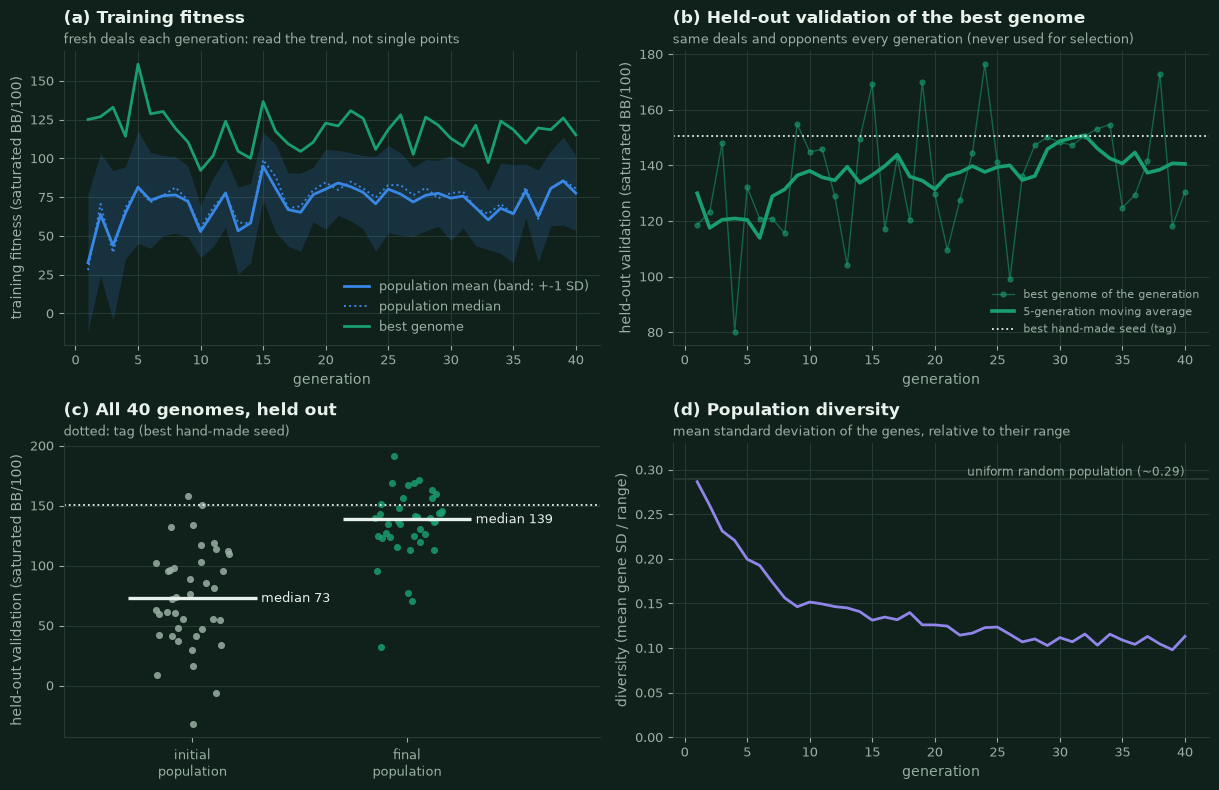

| population | 10% quantile | 25% quantile | 50% quantile | 75% quantile | 90% quantile | max |
|---|---|---|---|---|---|---|
| initial (random + 3 seeds) | 28 | 46 | 73 | 102 | 120 | 158 |
| final | 111 | 125 | 139 | 149 | 167 | 191 |


**What the saved history shows**

* **Population level (clean evidence).** Held-out median of the whole population: **73 -> 139** saturated BB/100
  (difference +66, bootstrap 95% CI [+43, +84]; one-sided Mann-Whitney p = 8.3e-10).
  25% of the final genomes beat the best hand-made seed (tag, 151) on the held-out set, against 2% of the initial population.
* **Training fitness of the population** rose from a mean of 57 (generations 1-5) to 77 (last five); its spread (SD) fell
  from 44 to 24.
* **The whole distribution moved up, the ceiling much less.** 10% quantile of the held-out scores 28 -> 111, median 73 -> 139,
  best genome 158 -> 191: evolution mainly removed poor genomes and concentrated the population around a good region.
* **Plateau of the best genome (noise, not progress).** The best genome's *training* fitness did not trend upward (132 in generations 1-5 vs
  118 in the last five). Assumption: a maximum over 40 noisy scores is already high in generation 1 (the first population holds good genomes, e.g. the seeds) and later maxima are
  inflated by the same winner's-curse effect. Its *held-out* validation moved from 120 to 138 (SD over the run 21, range 80-176): the generation-to-generation scatter is as large as the improvement, so the curve in (b) must not be over-read.
* Training best and held-out validation of the same genome are only weakly related across generations (Spearman rho = -0.20, p = 0.22) - a direct measure of how noisy a single generation's ranking is.


In [18]:
ini = np.array(TRAIN["population_validation_fitness"]["initial"]["genomes"])
fin = np.array(TRAIN["population_validation_fitness"]["final"]["genomes"])
best_preset, best_preset_value = max(TRAIN["reference_validation_fitness"].items(), key=lambda item: item[1])
gen = history["generation"].to_numpy() + 1
val = history["validation_fitness"].to_numpy()
val_smooth = pd.Series(val).rolling(5, center=True, min_periods=1).mean().to_numpy()

fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.0))
(a, b), (c, d) = axes
a.fill_between(gen, history["mean_fitness"] - history["std_fitness"], history["mean_fitness"] + history["std_fitness"], color=nbp.SERIES[1], alpha=0.18, linewidth=0)
a.plot(gen, history["mean_fitness"], color=nbp.SERIES[1], label="population mean (band: +-1 SD)")
a.plot(gen, history["median_fitness"], color=nbp.SERIES[1], linestyle=":", linewidth=1.4, label="population median")
a.plot(gen, history["best_fitness"], color=nbp.ACCENT, label="best genome")
a.set_xlabel("generation")
a.set_ylabel("training fitness (saturated BB/100)")
nbp.title(a, "(a) Training fitness", "fresh deals each generation: read the trend, not single points")
a.legend(loc="lower right")

b.plot(gen, val, color=nbp.ACCENT, linewidth=1.0, alpha=0.55, marker="o", markersize=3.5, label="best genome of the generation")
b.plot(gen, val_smooth, color=nbp.ACCENT, linewidth=2.6, label="5-generation moving average")
b.axhline(best_preset_value, color=nbp.TEXT, linestyle=":", linewidth=1.3, label=f"best hand-made seed ({best_preset})")
b.set_xlabel("generation")
b.set_ylabel("held-out validation (saturated BB/100)")
nbp.title(b, "(b) Held-out validation of the best genome", "same deals and opponents every generation (never used for selection)")
b.legend(loc="lower right", fontsize=8)

rng_strip = np.random.default_rng(DEMO_SEED)
for x_pos, (label, values, color) in enumerate((("initial\npopulation", ini, nbp.MUTED), ("final\npopulation", fin, nbp.ACCENT))):
    c.scatter(x_pos + rng_strip.uniform(-0.17, 0.17, len(values)), values, s=26, color=color, alpha=0.85, linewidths=0)
    c.hlines(np.median(values), x_pos - 0.3, x_pos + 0.3, color=nbp.TEXT, linewidth=2.4)
    c.annotate(f"median {np.median(values):.0f}", (x_pos + 0.32, np.median(values)), va="center", color=nbp.TEXT, fontsize=9)
c.axhline(best_preset_value, color=nbp.TEXT, linestyle=":", linewidth=1.3)
c.set_xticks([0, 1], ["initial\npopulation", "final\npopulation"])
c.set_xlim(-0.6, 1.9)
c.set_ylabel("held-out validation (saturated BB/100)")
c.grid(axis="x", visible=False)
nbp.title(c, "(c) All 40 genomes, held out", f"dotted: {best_preset} (best hand-made seed)")

d.plot(gen, history["diversity"], color=nbp.SERIES[3])
d.axhline(0.29, color=nbp.GRID, linewidth=1.2)
d.annotate("uniform random population (~0.29)", (gen[-1], 0.29), ha="right", va="bottom", fontsize=8.5, color=nbp.MUTED)
d.set_ylim(0, 0.33)
d.set_xlabel("generation")
d.set_ylabel("diversity (mean gene SD / range)")
nbp.title(d, "(d) Population diversity", "mean standard deviation of the genes, relative to their range")
fig.tight_layout()
nbp.savefig("nb03_fitness_evolution", fig)
plt.show()

quantiles = (0.1, 0.25, 0.5, 0.75, 0.9, 1.0)
display(md_table(pd.DataFrame(
    {"population": ["initial (random + 3 seeds)", "final"], **{("max" if q == 1.0 else f"{q:.0%} quantile"): [np.quantile(ini, q), np.quantile(fin, q)] for q in quantiles}}
), "{:.0f}"))
boot = np.random.default_rng(DEMO_SEED)
median_gain = float(np.median(fin) - np.median(ini))
gain_samples = [np.median(boot.choice(fin, len(fin))) - np.median(boot.choice(ini, len(ini))) for _ in range(5000)]
gain_low, gain_high = np.percentile(gain_samples, [2.5, 97.5])
mann_whitney = stats.mannwhitneyu(fin, ini, alternative="greater")
head, tail = slice(0, 5), slice(-5, None)
rho_noise = stats.spearmanr(history["best_fitness"], history["validation_fitness"])
display(Markdown(f"""
**What the saved history shows**

* **Population level (clean evidence).** Held-out median of the whole population: **{np.median(ini):.0f} -> {np.median(fin):.0f}** saturated BB/100
  (difference {median_gain:+.0f}, bootstrap 95% CI [{gain_low:+.0f}, {gain_high:+.0f}]; one-sided Mann-Whitney p = {mann_whitney.pvalue:.1e}).
  {np.mean(fin > best_preset_value):.0%} of the final genomes beat the best hand-made seed ({best_preset}, {best_preset_value:.0f}) on the held-out set, against {np.mean(ini > best_preset_value):.0%} of the initial population.
* **Training fitness of the population** rose from a mean of {history['mean_fitness'].iloc[head].mean():.0f} (generations 1-5) to {history['mean_fitness'].iloc[tail].mean():.0f} (last five); its spread (SD) fell
  from {history['std_fitness'].iloc[0]:.0f} to {history['std_fitness'].iloc[-1]:.0f}.
* **The whole distribution moved up, the ceiling much less.** 10% quantile of the held-out scores {np.quantile(ini, 0.1):.0f} -> {np.quantile(fin, 0.1):.0f}, median {np.median(ini):.0f} -> {np.median(fin):.0f},
  best genome {ini.max():.0f} -> {fin.max():.0f}: evolution mainly removed poor genomes and concentrated the population around a good region.
* **Plateau of the best genome (noise, not progress).** The best genome's *training* fitness did not trend upward ({history['best_fitness'].iloc[head].mean():.0f} in generations 1-5 vs
  {history['best_fitness'].iloc[tail].mean():.0f} in the last five). Assumption: a maximum over 40 noisy scores is already high in generation 1 (the first population holds good genomes, e.g. the seeds) and later maxima are
  inflated by the same winner's-curse effect. Its *held-out* validation moved from {val[head].mean():.0f} to {val[tail].mean():.0f} (SD over the run {val.std(ddof=1):.0f}, range {val.min():.0f}-{val.max():.0f}): the generation-to-generation scatter is as large as the improvement, so the curve in (b) must not be over-read.
* Training best and held-out validation of the same genome are only weakly related across generations (Spearman rho = {rho_noise.statistic:.2f}, p = {rho_noise.pvalue:.2f}) - a direct measure of how noisy a single generation's ranking is.
"""))

## 6. The best strategy: parameter values and a readable rule summary `[saved]`

The evolved genome (`best_genome.json`) is the highest-scoring of the finalists after they were re-evaluated on
fresh deal sets (the guard against the winner's curse). Next to it: the hand-made styles. `tag`, `lag` and `nit`
were *seeds* of the initial population; `passive` and `maniac-ish` were sparring partners in the pool;
`balanced` and `bluffer` never appeared in training.

| gene | evolved | tag (seed) | lag (seed) | nit (seed) | passive | maniac-ish | balanced (held out) | bluffer (held out) |
|---|---|---|---|---|---|---|---|---|
| `pf_play_btn` | 0.404 | 0.420 | 0.350 | 0.560 | 0.360 | 0.330 | 0.400 | 0.460 |
| `pf_open_raise` | 0.418 | 0.500 | 0.400 | 0.620 | 0.750 | 0.380 | 0.520 | 0.520 |
| `pf_bb_raise` | 0.455 | 0.580 | 0.480 | 0.720 | 0.820 | 0.400 | 0.600 | 0.620 |
| `pf_defend` | 0.404 | 0.500 | 0.420 | 0.600 | 0.420 | 0.360 | 0.460 | 0.520 |
| `pf_3bet` | 0.631 | 0.680 | 0.580 | 0.780 | 0.920 | 0.500 | 0.720 | 0.640 |
| `pf_shove` | 0.918 | 0.800 | 0.750 | 0.840 | 0.930 | 0.700 | 0.820 | 0.850 |
| `value_bet` | 0.590 | 0.620 | 0.550 | 0.720 | 0.800 | 0.500 | 0.580 | 0.660 |
| `value_raise` | 0.851 | 0.780 | 0.700 | 0.860 | 0.960 | 0.570 | 0.740 | 0.820 |
| `shove_threshold` | 0.933 | 0.920 | 0.880 | 0.970 | 0.990 | 0.780 | 0.900 | 0.950 |
| `call_margin` | 0.038 | 0.030 | -0.020 | 0.100 | -0.030 | 0.000 | 0.050 | 0.060 |
| `fold_big_bet` | 0.229 | 0.080 | 0.020 | 0.150 | 0.000 | 0.000 | 0.100 | 0.050 |
| `deep_stack_caution` | 0.055 | 0.040 | 0.000 | 0.080 | 0.000 | 0.000 | 0.030 | 0.020 |
| `position_bonus` | -0.005 | 0.030 | 0.060 | 0.000 | 0.000 | 0.000 | 0.040 | 0.050 |
| `bluff_freq` | 0.024 | 0.120 | 0.350 | 0.020 | 0.000 | 0.600 | 0.200 | 0.500 |
| `semi_bluff_freq` | 0.462 | 0.500 | 0.850 | 0.100 | 0.050 | 1.000 | 0.600 | 0.900 |
| `big_bet_prob` | 0.329 | 0.350 | 0.550 | 0.300 | 0.200 | 0.800 | 0.500 | 0.750 |
| `adapt_fold` | 0.627 | 0.300 | 0.300 | 0.000 | 0.000 | 0.000 | 0.400 | 0.500 |
| `adapt_aggression` | -0.187 | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 | 0.100 | -0.100 |

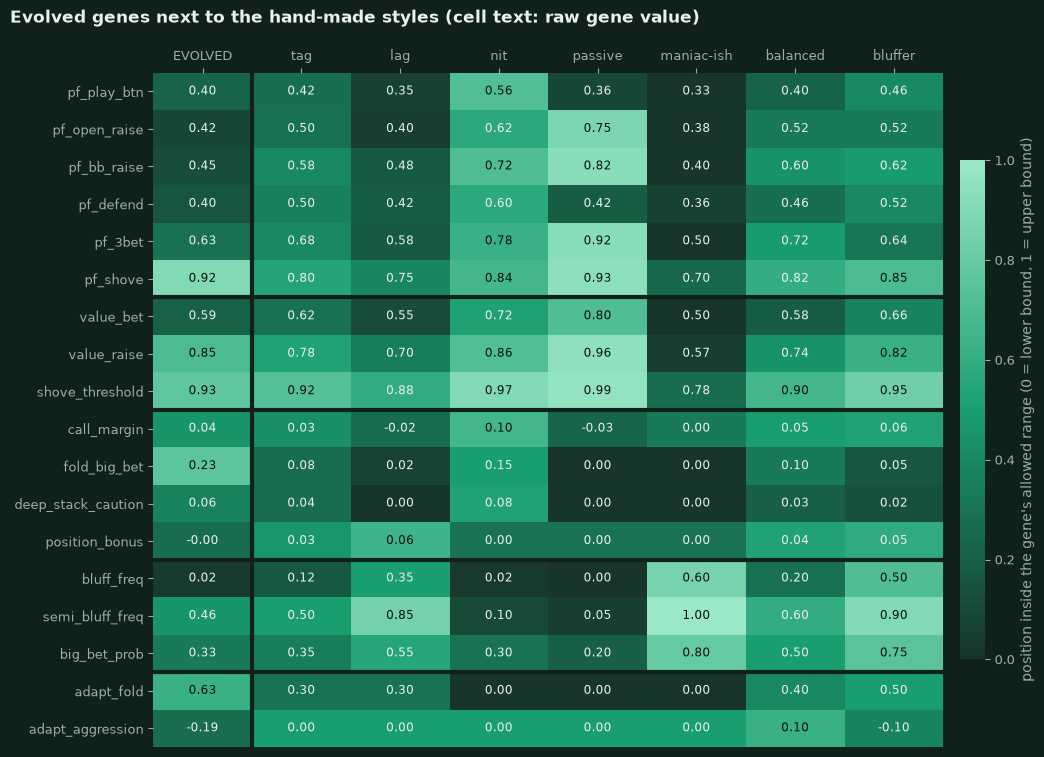

In [19]:
GENOMES = {"evolved": EVOLVED, **{name: PRESETS[name] for name in ("tag", "lag", "nit", "passive", "maniac-ish", "balanced", "bluffer")}}
ORDER = list(GENOMES)
gene_values = pd.DataFrame({name: genome.to_vector() for name, genome in GENOMES.items()}, index=GENE_NAMES)
display(md_table(gene_values.rename(columns={"tag": "tag (seed)", "lag": "lag (seed)", "nit": "nit (seed)", "balanced": "balanced (held out)", "bluffer": "bluffer (held out)"}).reset_index(names="gene").assign(gene=lambda f: "`" + f["gene"] + "`")))

unit_values = np.array([to_unit(GENOMES[name].to_vector()) for name in ORDER]).T  # genes x agents
fig, ax = plt.subplots(figsize=(10.5, 7.6))
image = ax.imshow(unit_values, cmap=nbp.SEQUENTIAL, vmin=0, vmax=1, aspect="auto")
for i in range(unit_values.shape[0]):
    for j in range(unit_values.shape[1]):
        ax.text(j, i, f"{gene_values.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8.5, color="#0b1210" if unit_values[i, j] > 0.62 else nbp.TEXT)
ax.set_xticks(range(len(ORDER)), [n if n != "evolved" else "EVOLVED" for n in ORDER])
ax.set_yticks(range(len(GENE_NAMES)), GENE_NAMES)
ax.xaxis.tick_top()
ax.grid(False)
group_edges = np.cumsum([sum(1 for s in GENE_SPECS if s.group == g) for g in dict.fromkeys(s.group for s in GENE_SPECS)])[:-1] - 0.5
for edge in group_edges:
    ax.axhline(edge, color=nbp.SURFACE, linewidth=3)
ax.axvline(0.5, color=nbp.SURFACE, linewidth=3)
for spine in ax.spines.values():
    spine.set_visible(False)
colorbar = fig.colorbar(image, ax=ax, fraction=0.03, pad=0.02)
colorbar.set_label("position inside the gene's allowed range (0 = lower bound, 1 = upper bound)", color=nbp.MUTED)
colorbar.outline.set_visible(False)
fig.suptitle("Evolved genes next to the hand-made styles (cell text: raw gene value)", x=0.01, ha="left", fontsize=12, fontweight="bold", color=nbp.TEXT, y=0.99)
fig.tight_layout()
nbp.savefig("nb03_strategy_heatmap", fig)
plt.show()

### 6.1 The strategy along the equity axis

The same genes seen as *decision zones*: for each strategy, which action does hand strength (equity against a random
hand) trigger? The fold/call boundary facing a bet really is `max(pf_defend, pot odds + call_margin + fold_big_bet x bet size)`;
the diamond shows the equity needed to continue against a **pot-sized** bet (pot odds 1/3), which for genomes with a large
`fold_big_bet` is far above the plain `pf_defend` threshold.

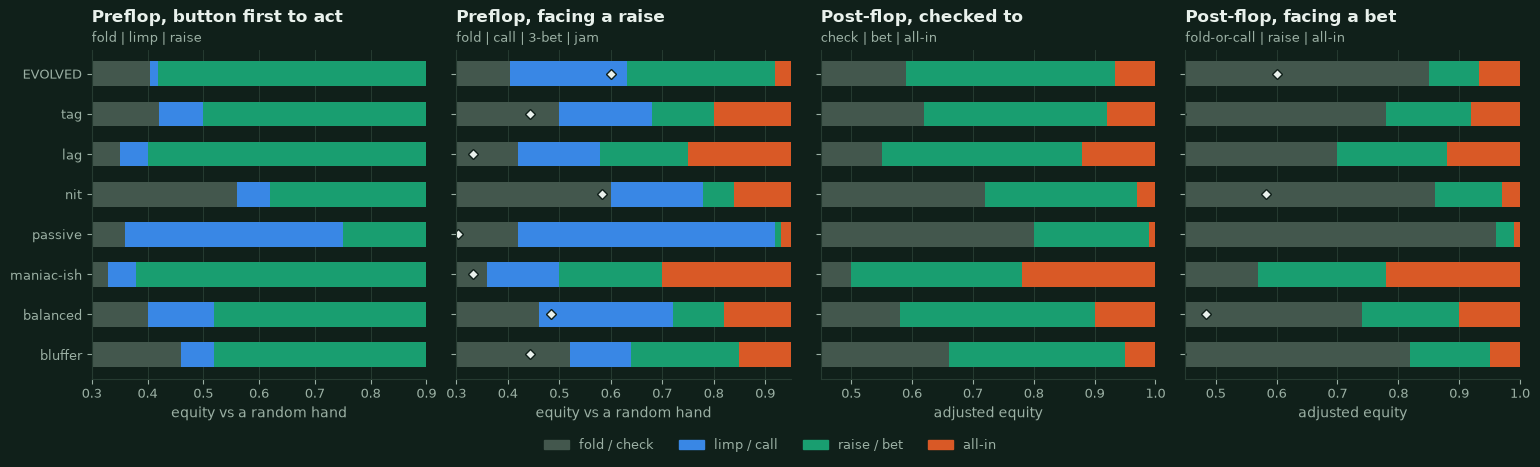

In [20]:
FOLD_C, PASSIVE_C, RAISE_C, JAM_C = "#43574d", nbp.SERIES[1], nbp.ACCENT, nbp.SERIES[2]
POT_BET_ODDS = 1 / 3  # pot odds when facing a pot-sized bet


def zone_segments(genome: Genome) -> dict[str, list[tuple[float, float, str]]]:
    """Equity zones of each decision situation, derived from the genes exactly as the rule cascade orders them."""
    g = genome
    button = [(0.0, g.pf_play_btn, FOLD_C)]
    if g.pf_open_raise > g.pf_play_btn:
        button.append((g.pf_play_btn, g.pf_open_raise, PASSIVE_C))
    button.append((max(g.pf_play_btn, g.pf_open_raise), 1.0, RAISE_C))
    facing = [(0.0, g.pf_defend, FOLD_C), (g.pf_defend, max(g.pf_defend, min(g.pf_3bet, g.pf_shove)), PASSIVE_C)]
    if g.pf_3bet < g.pf_shove:
        facing.append((g.pf_3bet, g.pf_shove, RAISE_C))
    facing.append((max(g.pf_shove, g.pf_defend), 1.0, JAM_C))
    checked = [(0.0, g.value_bet, FOLD_C), (g.value_bet, g.shove_threshold, RAISE_C), (g.shove_threshold, 1.0, JAM_C)]
    bet = [(0.0, g.value_raise, FOLD_C), (g.value_raise, max(g.value_raise, g.shove_threshold), RAISE_C), (g.shove_threshold, 1.0, JAM_C)]
    return {"button": button, "facing": facing, "checked": checked, "bet": bet}


PANELS = (
    ("button", "Preflop, button first to act", "fold | limp | raise", (0.30, 0.90)),
    ("facing", "Preflop, facing a raise", "fold | call | 3-bet | jam", (0.30, 0.95)),
    ("checked", "Post-flop, checked to", "check | bet | all-in", (0.45, 1.0)),
    ("bet", "Post-flop, facing a bet", "fold-or-call | raise | all-in", (0.45, 1.0)),
)
LADDER = ["evolved", "tag", "lag", "nit", "passive", "maniac-ish", "balanced", "bluffer"]
fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.6), sharey=True)
for ax, (key, name, subtitle, (x_lo, x_hi)) in zip(axes, PANELS):
    for row, agent in enumerate(LADDER):
        genome = GENOMES[agent]
        for lo, hi, color in zone_segments(genome)[key]:
            lo, hi = max(lo, x_lo), min(hi, x_hi)
            if hi > lo:
                ax.barh(row, hi - lo, left=lo, height=0.62, color=color, linewidth=0)
        if key in ("facing", "bet"):  # equity needed to continue against a pot-sized bet
            ax.plot(POT_BET_ODDS + genome.call_margin + genome.fold_big_bet, row, "D", color=nbp.TEXT, markersize=5.5, markeredgecolor=nbp.SURFACE)
    ax.set_xlim(x_lo, x_hi)
    ax.set_ylim(len(LADDER) - 0.4, -0.6)
    ax.set_xlabel("equity vs a random hand" if key in ("button", "facing") else "adjusted equity")
    ax.grid(axis="y", visible=False)
    nbp.title(ax, name, subtitle)
axes[0].set_yticks(range(len(LADDER)), [n.upper() if n == "evolved" else n for n in LADDER])
fig.legend(
    handles=[Patch(color=FOLD_C, label="fold / check"), Patch(color=PASSIVE_C, label="limp / call"), Patch(color=RAISE_C, label="raise / bet"), Patch(color=JAM_C, label="all-in")],
    loc="lower center", ncol=4, frameon=False, labelcolor=nbp.MUTED, fontsize=9, bbox_to_anchor=(0.5, -0.02),
)
fig.tight_layout(rect=(0, 0.04, 1, 1))
nbp.savefig("nb03_threshold_ladder", fig)
plt.show()

**Preflop ranges in plain numbers.** Equity before the flop is a table look-up, so each threshold translates exactly into the
share of the 1,326 equally likely two-card starting hands that falls on each side of it (`poker_arena.equity.preflop_equity`):

In [21]:
starting_hands = list(combinations(ALL_CARDS, 2))
hand_equity = np.array([preflop_equity(hand) for hand in starting_hands])
share = lambda mask: float(np.mean(mask))  # noqa: E731
preflop_ranges = {}
for name, g in GENOMES.items():
    pot_raise_requirement = max(g.pf_defend, POT_BET_ODDS + g.call_margin + g.fold_big_bet)
    preflop_ranges[name] = {
        "button: fold": share(hand_equity < g.pf_play_btn),
        "button: limp": share((hand_equity >= g.pf_play_btn) & (hand_equity < g.pf_open_raise)),
        "button: raise first-in": share(hand_equity >= max(g.pf_open_raise, g.pf_play_btn)),
        "big blind vs a limp: raise": share(hand_equity >= g.pf_bb_raise),
        "vs a raise: threshold pf_defend": share(hand_equity >= g.pf_defend),
        "vs a pot-sized raise: continue": share(hand_equity >= pot_raise_requirement),
        "vs a raise: 3-bet or jam": share(hand_equity >= min(g.pf_3bet, g.pf_shove)),
    }
range_table = pd.DataFrame(preflop_ranges).T.map(lambda v: f"{v:.0%}").reset_index(names="strategy")
range_table["strategy"] = [f"**{n}**" if n == "evolved" else n for n in range_table["strategy"]]
display(md_table(range_table))

| strategy | button: fold | button: limp | button: raise first-in | big blind vs a limp: raise | vs a raise: threshold pf_defend | vs a pot-sized raise: continue | vs a raise: 3-bet or jam |
|---|---|---|---|---|---|---|---|
| **evolved** | 19% | 5% | 76% | 64% | 81% | 14% | 8% |
| tag | 24% | 27% | 49% | 20% | 49% | 49% | 3% |
| lag | 5% | 14% | 81% | 56% | 76% | 76% | 20% |
| nit | 72% | 18% | 10% | 3% | 14% | 14% | 1% |
| passive | 6% | 92% | 2% | 1% | 76% | 76% | 0% |
| maniac-ish | 1% | 11% | 88% | 81% | 94% | 94% | 49% |
| balanced | 19% | 41% | 41% | 14% | 63% | 53% | 3% |
| bluffer | 37% | 22% | 41% | 10% | 41% | 41% | 7% |

### 6.2 Evolved vs hand-made: which genes moved, and which style is it closest to?

In [22]:
tag_unit, evolved_unit = to_unit(PRESETS["tag"].to_vector()), to_unit(EVOLVED.to_vector())
shift = evolved_unit - tag_unit
top = np.argsort(-np.abs(shift))[:6]
distance = {name: float(np.mean(np.abs(to_unit(GENOMES["evolved"].to_vector()) - to_unit(GENOMES[name].to_vector())))) for name in ORDER[1:]}
nearest = min(distance, key=distance.get)
display(Markdown(
    "**Largest shifts from the `tag` defaults** (share of the gene's allowed range): "
    + "; ".join(f"`{GENE_NAMES[i]}` {PRESETS['tag'].to_dict()[GENE_NAMES[i]]:.2f} -> {EVOLVED.to_dict()[GENE_NAMES[i]]:.2f} ({shift[i]:+.0%})" for i in top)
    + ".\n\n**Distance of the evolved genome to each hand-made style** (mean absolute difference per gene, fraction of the range; random genomes are about 0.33 apart): "
    + ", ".join(f"{name} {value:.2f}" for name, value in sorted(distance.items(), key=lambda item: item[1]))
    + f". Closest: **{nearest}**."
))
display(Markdown("**The same strategy in words** - `strategy_card()` of the evolved genome and of its closest hand-made style:"))
for title_text, genome in (("evolved", EVOLVED), (nearest, PRESETS[nearest])):
    display(Markdown(f"*{title_text}*\n\n" + "\n".join(f"- {line}" for line in genome.strategy_card())))

**Largest shifts from the `tag` defaults** (share of the gene's allowed range): `fold_big_bet` 0.08 -> 0.23 (+50%); `pf_shove` 0.80 -> 0.92 (+36%); `adapt_fold` 0.30 -> 0.63 (+33%); `pf_bb_raise` 0.58 -> 0.45 (-28%); `adapt_aggression` 0.00 -> -0.19 (-23%); `pf_defend` 0.50 -> 0.40 (-20%).

**Distance of the evolved genome to each hand-made style** (mean absolute difference per gene, fraction of the range; random genomes are about 0.33 apart): tag 0.17, balanced 0.20, bluffer 0.25, lag 0.27, nit 0.27, passive 0.35, maniac-ish 0.38. Closest: **tag**.

**The same strategy in words** - `strategy_card()` of the evolved genome and of its closest hand-made style:

*evolved*

- Button, first to act: fold below equity 0.40, limp up to 0.42, raise at or above 0.42.
- Big blind vs a limp: raise with equity >= 0.45, otherwise check.
- Preflop vs a raise: call with equity >= 0.40 (and pot odds +0.04), 3-bet at >= 0.63, jam all-in at >= 0.92.
- Postflop (adjusted equity): bet for value at >= 0.59; facing a bet, raise at >= 0.85, go all-in at >= 0.93.
- Facing a bet: call when equity >= pot odds +0.04 + 0.23 per pot-size of the bet.
- Adjusted equity = equity -0.00 in position (+0.00 out of position) minus up to 0.06 for deep stacks.
- Bluffs 2% of weak hands when checked to; semi-bluffs 46% of flush/straight draws.
- Bet sizing: pot-size 33% of the time, otherwise half pot.
- Adaptation: bluff frequency +0.63 per +1.0 opponent fold-to-bet above neutral; call margin -0.19 per +1.0 opponent aggression above neutral.

*tag*

- Button, first to act: fold below equity 0.42, limp up to 0.50, raise at or above 0.50.
- Big blind vs a limp: raise with equity >= 0.58, otherwise check.
- Preflop vs a raise: call with equity >= 0.50 (and pot odds +0.03), 3-bet at >= 0.68, jam all-in at >= 0.80.
- Postflop (adjusted equity): bet for value at >= 0.62; facing a bet, raise at >= 0.78, go all-in at >= 0.92.
- Facing a bet: call when equity >= pot odds +0.03 + 0.08 per pot-size of the bet.
- Adjusted equity = equity +0.03 in position (-0.03 out of position) minus up to 0.04 for deep stacks.
- Bluffs 12% of weak hands when checked to; semi-bluffs 50% of flush/straight draws.
- Bet sizing: pot-size 35% of the time, otherwise half pot.
- Adaptation: bluff frequency +0.30 per +1.0 opponent fold-to-bet above neutral; call margin +0.00 per +1.0 opponent aggression above neutral.

## 7. Population evolution `[saved]` (+ the exactly reproducible initial population)

The run saved the final population and, per generation, the mean and standard deviation of every gene plus the best
genome - but not the *initial* population. That one is a deterministic function of the seed (`make_initial_population`
with the operator stream `derive_seed("ga_fitness", seed, "operators")`), so it can be rebuilt and **checked against the
saved generation-0 statistics**.

In [23]:
operator_rng = np.random.default_rng(derive_seed("ga_fitness", GA_CONFIG.seed, "operators"))
seed_vectors = [PRESETS[name].to_vector() for name in run_cfg["effective_config"]["SEED_PRESETS"]]
initial_population = make_initial_population(GA_CONFIG.population_size, seed_vectors, BOUNDS, operator_rng)
final_population = np.array(pop_doc["population"])
mean_by_gen = history[[f"mean_{g}" for g in GENE_NAMES]].to_numpy()
std_by_gen = history[[f"std_{g}" for g in GENE_NAMES]].to_numpy()
best_by_gen = history[[f"best_{g}" for g in GENE_NAMES]].to_numpy()
error_initial = max(np.abs(initial_population.mean(axis=0) - mean_by_gen[0]).max(), np.abs(initial_population.std(axis=0) - std_by_gen[0]).max())
error_final = max(np.abs(final_population.mean(axis=0) - mean_by_gen[-1]).max(), np.abs(final_population.std(axis=0) - std_by_gen[-1]).max())
display(Markdown(
    f"Rebuilt initial population vs the saved generation-0 mean/SD of all {len(GENE_NAMES)} genes: max abs. difference **{error_initial:.1e}**; "
    f"saved final population vs saved last-generation statistics: **{error_final:.1e}** - the reconstruction is exact."
))

Rebuilt initial population vs the saved generation-0 mean/SD of all 18 genes: max abs. difference **9.0e-17**; saved final population vs saved last-generation statistics: **3.3e-16** - the reconstruction is exact.

### 7.1 Gene distributions: first vs last population

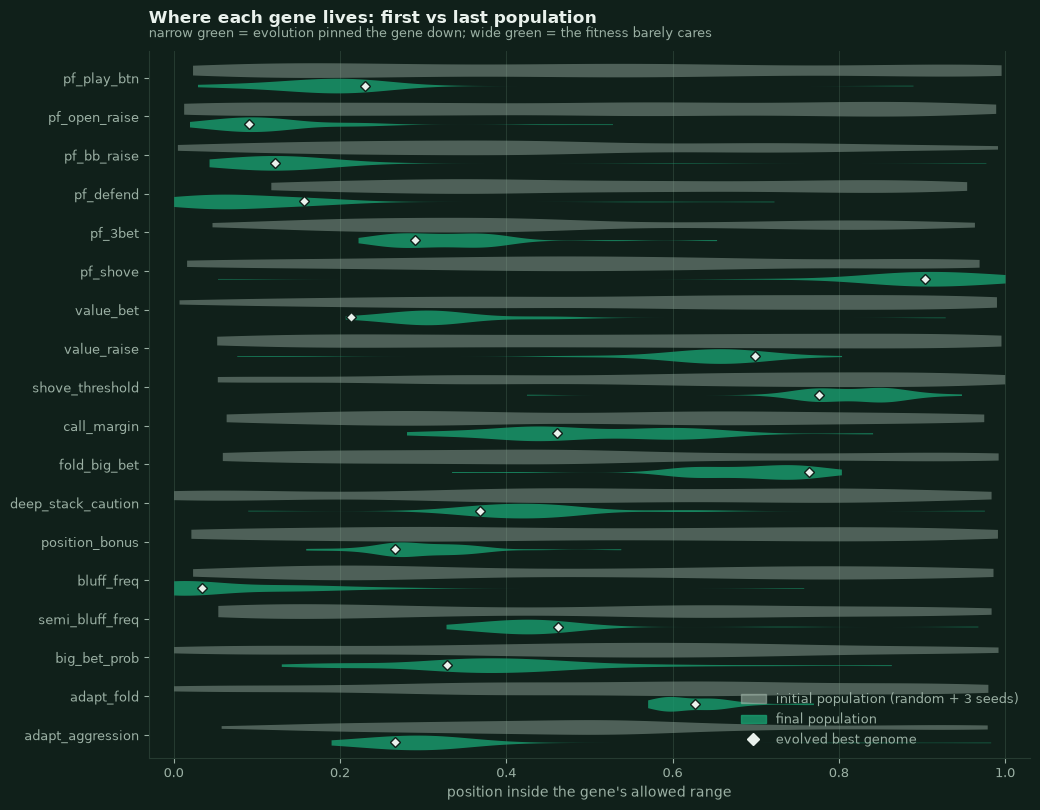

In [24]:
fig, ax = plt.subplots(figsize=(10.5, 8.2))
for i, gene in enumerate(GENE_NAMES):
    for offset, population, color, alpha in ((-0.2, initial_population, nbp.MUTED, 0.45), (0.2, final_population, nbp.ACCENT, 0.8)):
        values = (population[:, i] - GENE_LOWS[i]) / SPAN[i]
        grid = np.linspace(values.min(), values.max(), 120)  # a violin spans the observed values only
        density = stats.gaussian_kde(values, bw_method=0.35)(grid)
        half_height = 0.19 * density / density.max()
        ax.fill_between(grid, i + offset - half_height, i + offset + half_height, color=color, alpha=alpha, linewidth=0)
    ax.plot(evolved_unit[i], i + 0.2, "D", color=nbp.TEXT, markersize=5.5, markeredgecolor=nbp.SURFACE, zorder=4)
ax.set_yticks(range(len(GENE_NAMES)), GENE_NAMES)
ax.set_ylim(len(GENE_NAMES) - 0.4, -0.7)
ax.set_xlim(-0.03, 1.03)
ax.set_xlabel("position inside the gene's allowed range")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=nbp.MUTED, alpha=0.6, label="initial population (random + 3 seeds)"), Patch(color=nbp.ACCENT, alpha=0.8, label="final population"),
                   plt.Line2D([], [], marker="D", color=nbp.TEXT, linestyle="", label="evolved best genome")], loc="lower right")  # fmt: skip
nbp.title(ax, "Where each gene lives: first vs last population", "narrow green = evolution pinned the gene down; wide green = the fitness barely cares")
fig.tight_layout()
nbp.savefig("nb03_population_genes", fig)
plt.show()

### 7.2 Trajectories: mean and spread of every gene over the generations

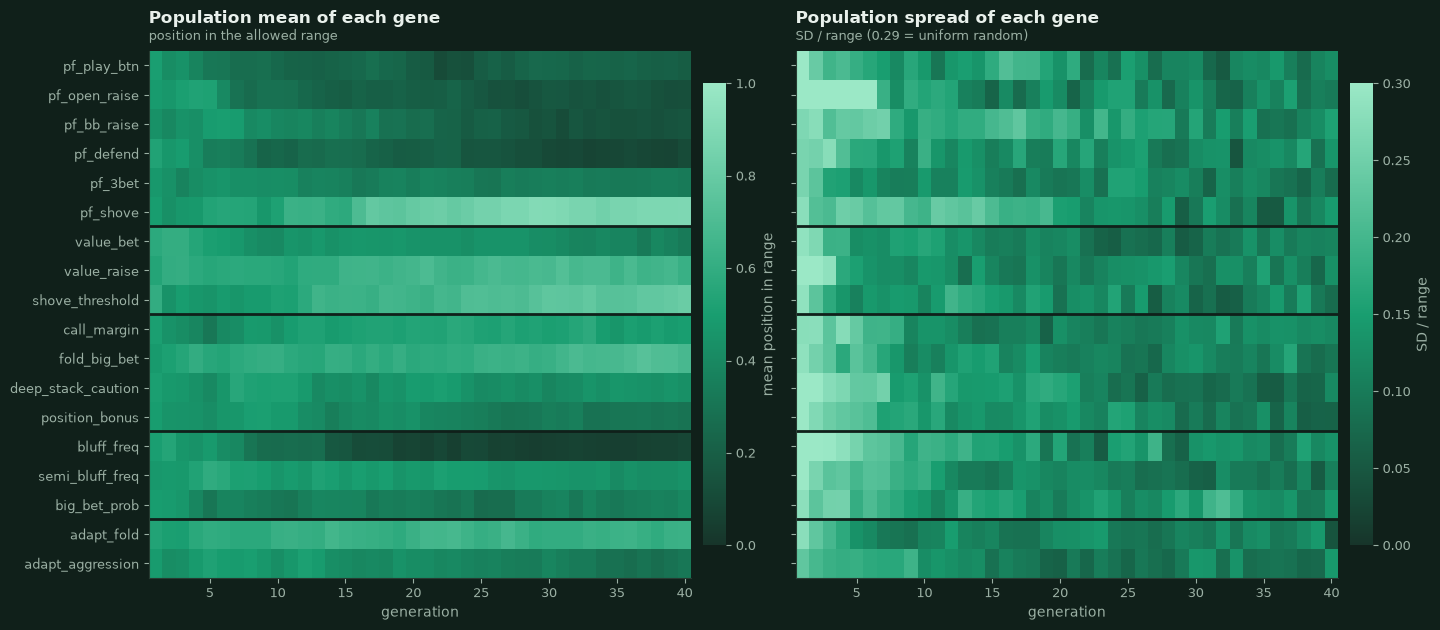

**Most converged genes** (final SD / range, initial about 0.29): `adapt_fold` 0.05, `position_bonus` 0.07, `pf_3bet` 0.08, `shove_threshold` 0.08, `fold_big_bet` 0.09.  
**Loosest genes** (the population still disagrees about them): `pf_bb_raise` 0.16, `pf_shove` 0.15, `adapt_aggression` 0.14, `big_bet_prob` 0.14, `pf_defend` 0.14.  
Mean spread 0.29 -> 0.11; the number of genes with a final spread below one third of the initial one: 6 of 18.

In [25]:
unit_mean = (mean_by_gen - GENE_LOWS) / SPAN  # generations x genes
unit_std = std_by_gen / SPAN
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14.5, 6.4), sharey=True)
extent = (0.5, len(history) + 0.5, len(GENE_NAMES) - 0.5, -0.5)
im1 = ax.imshow(unit_mean.T, cmap=nbp.SEQUENTIAL, vmin=0, vmax=1, aspect="auto", extent=extent)
im2 = ax2.imshow(unit_std.T, cmap=nbp.SEQUENTIAL, vmin=0, vmax=0.3, aspect="auto", extent=extent)
for axis in (ax, ax2):
    axis.set_xlabel("generation")
    axis.grid(False)
    for edge in group_edges:
        axis.axhline(edge + 0.0, color=nbp.SURFACE, linewidth=2)
ax.set_yticks(range(len(GENE_NAMES)), GENE_NAMES)
nbp.title(ax, "Population mean of each gene", "position in the allowed range")
nbp.title(ax2, "Population spread of each gene", "SD / range (0.29 = uniform random)")
for image, axis, label in ((im1, ax, "mean position in range"), (im2, ax2, "SD / range")):
    colorbar = fig.colorbar(image, ax=axis, fraction=0.04, pad=0.02)
    colorbar.set_label(label, color=nbp.MUTED)
    colorbar.outline.set_visible(False)
fig.tight_layout()
nbp.savefig("nb03_population_heatmaps", fig)
plt.show()

spread_first, spread_last = unit_std[0], unit_std[-1]
order_pinned = np.argsort(spread_last)
display(Markdown(
    f"**Most converged genes** (final SD / range, initial about {spread_first.mean():.2f}): "
    + ", ".join(f"`{GENE_NAMES[i]}` {spread_last[i]:.2f}" for i in order_pinned[:5])
    + ".  \n**Loosest genes** (the population still disagrees about them): "
    + ", ".join(f"`{GENE_NAMES[i]}` {spread_last[i]:.2f}" for i in order_pinned[::-1][:5])
    + f".  \nMean spread {spread_first.mean():.2f} -> {spread_last.mean():.2f}; the number of genes with a final spread below one third of the initial one: {int(np.sum(spread_last < spread_first / 3))} of {len(GENE_NAMES)}."
))

### 7.3 A 2-D projection of the search: PCA of the gene vectors

PCA (via SVD) of the range-normalised genomes of the first and last population; the path of each generation's best
genome and the hand-made styles are projected into the same plane. A projection of 18 dimensions loses information -
read it as a picture of *where* the population went, not as a measure of distances.

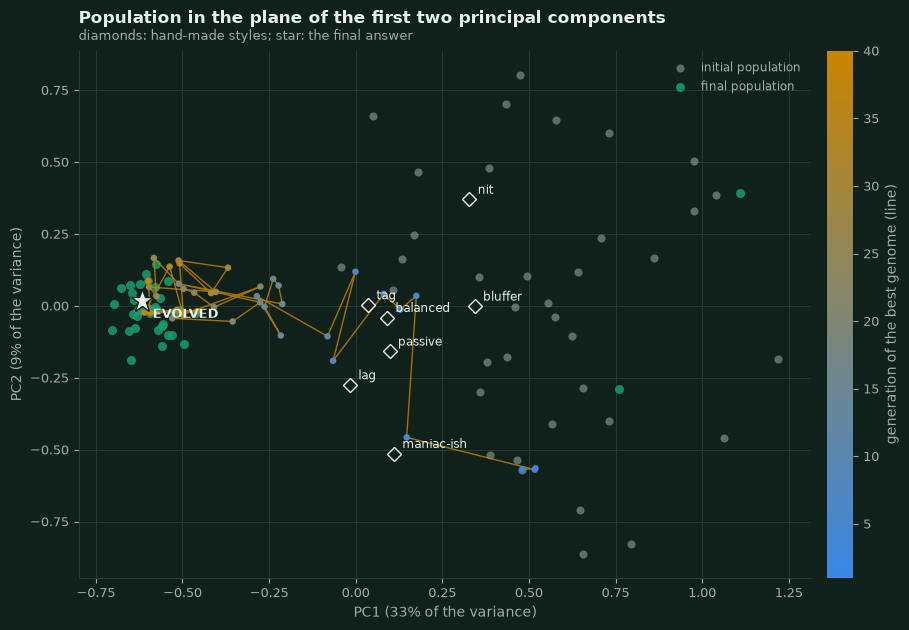

The first two components explain 41% of the variance of the pooled populations. PC1 is dominated by `pf_defend` (+0.42), `bluff_freq` (+0.40), `pf_open_raise` (+0.37), `pf_shove` (-0.36); PC2 by `pf_play_btn` (+0.55), `call_margin` (+0.46), `semi_bluff_freq` (+0.32), `bluff_freq` (-0.28) (loadings in parentheses). Mean distance of a genome from its population's centre in this plane: 0.47 (initial) -> 0.18 (final). The final population's centre is 1.03 away from the initial centre.

In [26]:
PATH_CMAP = LinearSegmentedColormap.from_list("early_to_late", [nbp.SERIES[1], nbp.SERIES[4]])  # blue (generation 1) -> yellow (last)
pool = np.vstack([to_unit(initial_population), to_unit(final_population)])
center = pool.mean(axis=0)
_, singular_values, components = np.linalg.svd(pool - center, full_matrices=False)
explained = singular_values**2 / np.sum(singular_values**2)
project = lambda vectors: (to_unit(np.atleast_2d(vectors)) - center) @ components[:2].T  # noqa: E731
p_initial, p_final, p_best = project(initial_population), project(final_population), project(best_by_gen)
fig, ax = plt.subplots(figsize=(9.2, 6.4))
ax.scatter(*p_initial.T, s=34, color=nbp.MUTED, alpha=0.55, linewidths=0, label="initial population")
ax.scatter(*p_final.T, s=42, color=nbp.ACCENT, alpha=0.85, linewidths=0, label="final population")
ax.plot(*p_best.T, color=nbp.SERIES[4], linewidth=1.0, alpha=0.8)
path = ax.scatter(*p_best.T, c=np.arange(1, len(p_best) + 1), cmap=PATH_CMAP, s=22, zorder=3, linewidths=0)
for name in ("tag", "lag", "nit", "passive", "maniac-ish", "balanced", "bluffer"):
    x, y = project(PRESETS[name].to_vector())[0]
    ax.plot(x, y, "D", markerfacecolor=nbp.SURFACE, markeredgecolor=nbp.TEXT, markersize=7, zorder=4)
    ax.annotate(name, (x, y), xytext=(6, 4), textcoords="offset points", fontsize=8.5, color=nbp.TEXT)
x, y = project(EVOLVED.to_vector())[0]
ax.plot(x, y, "*", color=nbp.TEXT, markersize=17, markeredgecolor=nbp.SURFACE, zorder=5)
ax.annotate("EVOLVED", (x, y), xytext=(8, -12), textcoords="offset points", fontsize=9.5, fontweight="bold", color=nbp.TEXT)
ax.set_xlabel(f"PC1 ({explained[0]:.0%} of the variance)")
ax.set_ylabel(f"PC2 ({explained[1]:.0%} of the variance)")
colorbar = fig.colorbar(path, ax=ax, fraction=0.04, pad=0.02)
colorbar.set_label("generation of the best genome (line)", color=nbp.MUTED)
colorbar.outline.set_visible(False)
ax.legend(loc="best", fontsize=8.5)
nbp.title(ax, "Population in the plane of the first two principal components", "diamonds: hand-made styles; star: the final answer")
fig.tight_layout()
nbp.savefig("nb03_population_pca", fig)
plt.show()
top_loadings = [
    ", ".join(f"`{GENE_NAMES[i]}` ({components[c][i]:+.2f})" for i in np.argsort(-np.abs(components[c]))[:4]) for c in range(2)
]
radius_initial = float(np.mean(np.linalg.norm(p_initial - p_initial.mean(axis=0), axis=1)))
radius_final = float(np.mean(np.linalg.norm(p_final - p_final.mean(axis=0), axis=1)))
display(Markdown(
    f"The first two components explain {explained[:2].sum():.0%} of the variance of the pooled populations. "
    f"PC1 is dominated by {top_loadings[0]}; PC2 by {top_loadings[1]} (loadings in parentheses). "
    f"Mean distance of a genome from its population's centre in this plane: {radius_initial:.2f} (initial) -> {radius_final:.2f} (final). "
    f"The final population's centre is {np.linalg.norm(p_final.mean(axis=0) - p_initial.mean(axis=0)):.2f} away from the initial centre."
))

## 8. Evaluation of the evolved behaviour

**What "held out" means here.** Three kinds of evidence, in decreasing order of independence from the training run:

1. **Held-out opponents** - `teacher`, `balanced`, `bluffer` never appeared in the training pool (the teacher cannot, by
   construction, section 3.4). Results against them cannot come from adapting to a training opponent.
2. **Pool opponents on fresh deals** - random, call station, maniac, nit, tag, lag (and passive, maniac-ish in the fresh
   evaluation) were training sparring partners; every deal used for evaluation is new, but the *style* of the opponent is known to the
   GA. These show strength against familiar opponents, not generalisation to unfamiliar ones.
3. **Same-run bookkeeping** (training fitness curves, section 5) is *not* evaluation.

BB/100 = big blinds won per 100 hands, always from the evolved agent's point of view. Every interval is a 95% Student-t
interval over **duplicate pairs** (hands inside a pair are strongly dependent, so hands are never treated as independent).
"wins" / "loses" below mean *the interval excludes zero*; "no significant difference" is **absence of evidence**, not equal strength.

### 8a. Saved held-out evaluation (training run) `[saved]`

Many duplicate pairs per opponent (the figure footnote gives the number) on identical deals for the evolved genome and the reference presets
`tag`, `lag`, `nit` (the presets that seeded the population). This evaluation was **recomputed after the duplicate-protocol change**
(`train_ga.py --evaluate-only`, two-table protocol, current teacher); the training itself was not repeated (section 3.5).

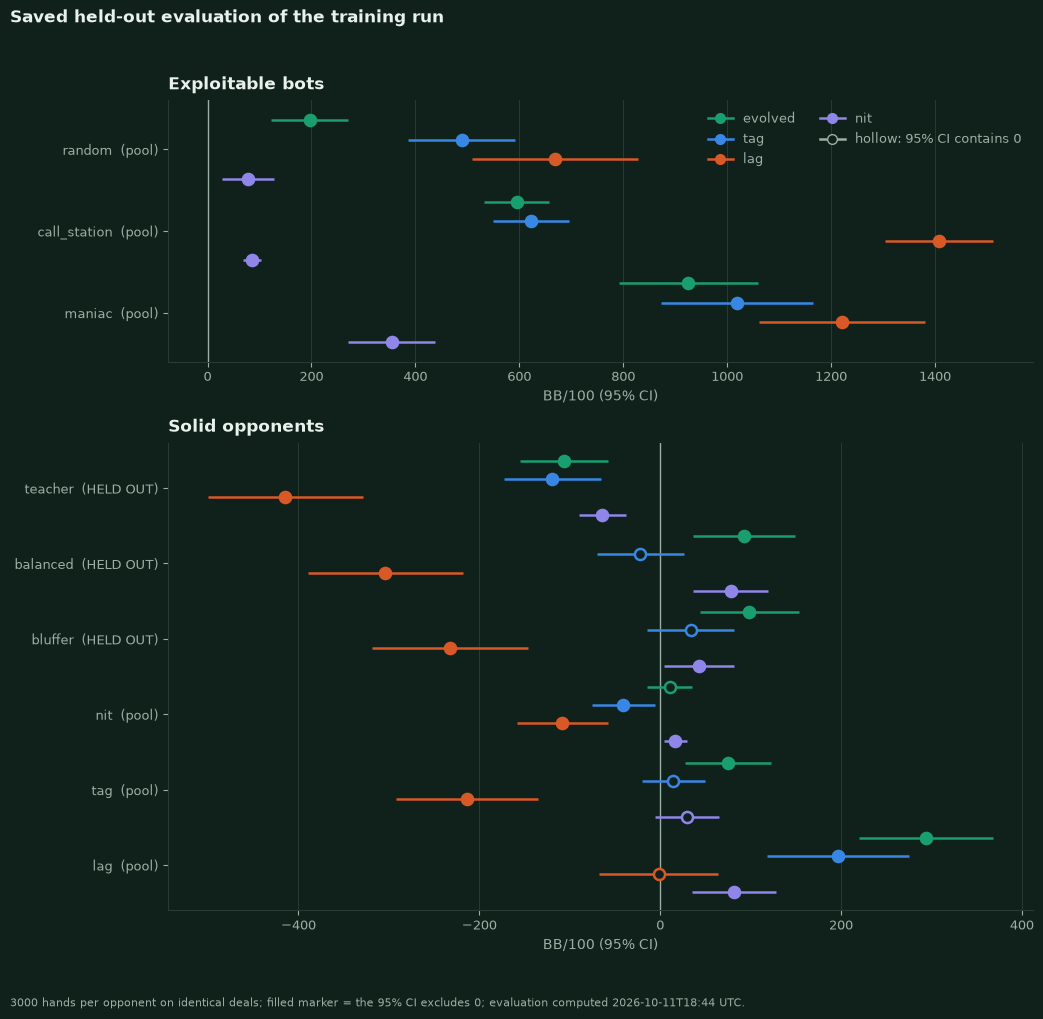

BB/100 [95% CI] of each agent against each opponent `[saved]`:

| opponent | held out? | evolved | evolved vs this opponent | tag | lag | nit |
|---|---|---|---|---|---|---|
| `random` | no (pool) | +197 [+122, +271] | wins | +489 [+387, +591] | +669 [+510, +828] | +78 [+28, +128] |
| `call_station` | no (pool) | +595 [+532, +658] | wins | +623 [+550, +696] | +1408 [+1304, +1512] | +85 [+67, +102] |
| `maniac` | no (pool) | +925 [+792, +1059] | wins | +1019 [+873, +1164] | +1221 [+1062, +1381] | +354 [+270, +438] |
| `teacher` | **yes** | -106 [-155, -57] | loses | -119 [-173, -65] | -414 [-501, -328] | -64 [-89, -38] |
| `balanced` | **yes** | +93 [+37, +149] | wins | -22 [-70, +27] | -304 [-389, -219] | +78 [+37, +119] |
| `bluffer` | **yes** | +99 [+44, +153] | wins | +34 [-14, +82] | -232 [-319, -146] | +43 [+4, +82] |
| `nit` | no (pool) | +10 [-14, +35] | no significant difference | -41 [-75, -6] | -108 [-159, -58] | +17 [+4, +30] |
| `tag` | no (pool) | +75 [+28, +122] | wins | +14 [-21, +50] | -213 [-292, -135] | +30 [-6, +65] |
| `lag` | no (pool) | +294 [+220, +368] | wins | +197 [+118, +276] | -2 [-67, +64] | +82 [+36, +128] |

In [27]:
BOTS = ("random", "call_station", "maniac")
AGENT_COLORS = {"evolved": nbp.ACCENT, "tag": nbp.SERIES[1], "lag": nbp.SERIES[2], "nit": nbp.SERIES[3]}


def evaluation_figure(table: dict, opponents: list[str], in_pool: dict[str, bool], file_name: str, headline: str, footer: str) -> None:
    """Forest plot of BB/100 with 95% CI: exploitable bots on their own (huge) scale above, solid opponents below.
    ``table[agent][opponent] = (estimate, ci_low, ci_high)``."""
    groups = (("Exploitable bots", [o for o in opponents if o in BOTS]), ("Solid opponents", [o for o in opponents if o not in BOTS]))
    row_height = 0.18 * len(table) + 0.1
    fig, axes = plt.subplots(
        2, 1, figsize=(10.5, row_height * sum(len(g) for _, g in groups) + 2.6),
        gridspec_kw={"height_ratios": [len(groups[0][1]) + 0.8, len(groups[1][1]) + 0.8]},
    )  # fmt: skip
    for ax, (name, members) in zip(axes, groups):
        missing = (np.nan, np.nan, np.nan)  # an agent does not play itself
        series = {agent: tuple(zip(*(table[agent].get(o, missing) for o in members))) for agent in table}
        labels = [f"{o}  ({'pool' if in_pool[o] else 'HELD OUT'})" for o in members]
        nbp.forest_plot(ax, labels, series, colors=AGENT_COLORS, x_label="BB/100 (95% CI)", legend=ax is axes[0])
        nbp.title(ax, name)
    fig.suptitle(headline, x=0.01, ha="left", fontsize=12, fontweight="bold", color=nbp.TEXT)
    nbp.footnote(fig, footer)
    fig.tight_layout(rect=(0, 0.02, 1, 0.96))
    nbp.savefig(file_name, fig)
    plt.show()


saved_table = {a: {o: (r["bb_per_100"], r["ci_low"], r["ci_high"]) for o, r in entry.items() if o != "style"} for a, entry in FINAL["results"].items()}
saved_in_pool = {o: flag["in_training_pool"] for o, flag in FINAL["opponents"].items()}
evaluation_figure(
    saved_table, list(FINAL["opponents"]), saved_in_pool, "nb03_eval_saved", "Saved held-out evaluation of the training run",
    f"{FINAL['hands_per_opponent']} hands per opponent on identical deals; filled marker = the 95% CI excludes 0; evaluation computed {meta.get('final_evaluation_refreshed_at', meta['created_at'])[:16]} UTC.",
)
rows = []
for opponent in FINAL["opponents"]:
    cells = {a: saved_table[a][opponent] for a in saved_table}
    rows.append(
        {
            "opponent": f"`{opponent}`",
            "held out?": "no (pool)" if saved_in_pool[opponent] else "**yes**",
            "evolved": ci_text(*cells["evolved"]),
            "evolved vs this opponent": verdict(cells["evolved"][1], cells["evolved"][2]),
            **{a: ci_text(*cells[a]) for a in saved_table if a != "evolved"},
        }
    )
display(Markdown("BB/100 [95% CI] of each agent against each opponent `[saved]`:"))
display(md_table(pd.DataFrame(rows)))

### 8b. Fresh, independent duplicate-deal evaluation `[fresh]`

New simulations with `poker_arena.data.evaluation.pair_results` / `summarize`: seed namespace **`eval`**, master seed
`EVAL_SEED` (the training run used 2026 in `ga_fitness` / `ga_validation`; section 3.3 verified that no deal coincides).
Heroes: the evolved agent and the reference presets `tag`, `lag`, `nit`. Opponents: the three bots, the teacher and all seven
hand-made styles. Every hero plays the *same* deals against a given opponent (common random numbers), so differences between
heroes are paired. Matches use the package-default two-table duplicate protocol (section 3.5) and, like the tournament, independent short sessions
(`pair_results`: 50 pairs = 100 hands, fresh agents and opponent statistics each); the saved evaluation plays one long session per opponent (follow-up after the replication check). Agents are rebuilt through the registry
(`AgentSpec`), so this is exactly what the app and the tournament would play.

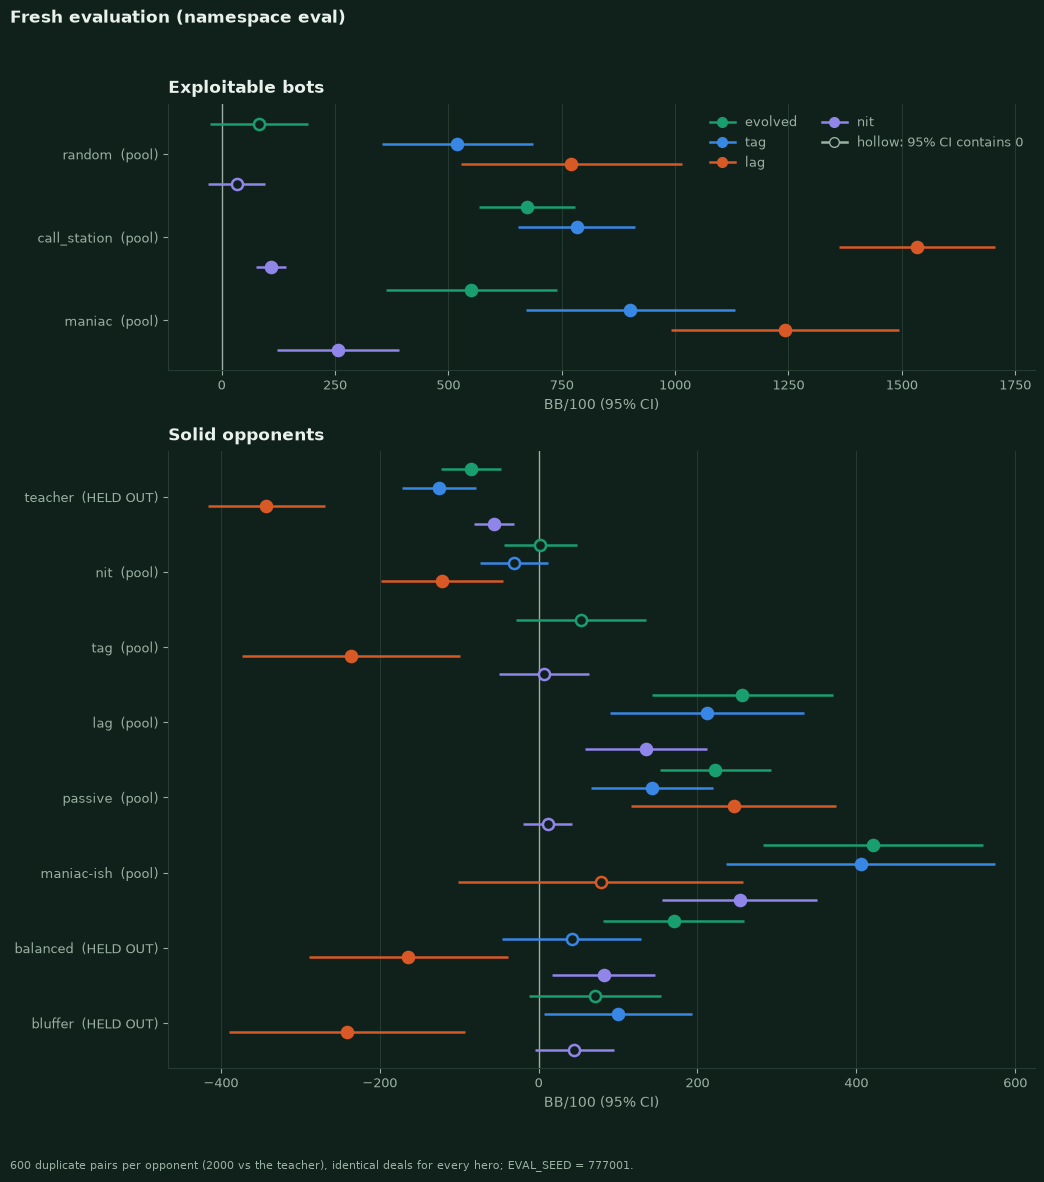

**[fresh]** 60,400 hands in 35 s on 6 worker processes. BB/100 [95% CI] of the evolved agent and of the reference presets:

| opponent | held out? | pairs | evolved BB/100 [95% CI] | result | conservative CI over 50-pair matches | tag | lag | nit |
|---|---|---|---|---|---|---|---|---|
| `random` | no (pool) | 600 | +82 [-25, +190] | no significant difference | [-49, +214] | +520 [+354, +686] | +771 [+527, +1015] | +33 [-31, +97] |
| `call_station` | no (pool) | 600 | +673 [+567, +779] | wins | [+585, +760] | +783 [+654, +912] | +1534 [+1362, +1706] | +108 [+75, +141] |
| `maniac` | no (pool) | 600 | +550 [+362, +739] | wins | [+330, +770] | +902 [+672, +1131] | +1242 [+990, +1494] | +257 [+123, +392] |
| `teacher` | **yes** | 2000 | -85 [-122, -47] | loses | [-124, -46] | -125 [-172, -79] | -343 [-417, -270] | -56 [-82, -31] |
| `nit` | no (pool) | 600 | +2 [-43, +48] | no significant difference | [-55, +60] | -31 [-74, +12] | -121 [-198, -44] | - |
| `tag` | no (pool) | 600 | +53 [-29, +135] | no significant difference | [-46, +152] | - | -236 [-373, -99] | +7 [-50, +64] |
| `lag` | no (pool) | 600 | +257 [+142, +371] | wins | [+111, +402] | +212 [+90, +334] | - | +135 [+58, +212] |
| `passive` | no (pool) | 600 | +222 [+153, +292] | wins | [+135, +310] | +143 [+66, +219] | +245 [+117, +374] | +11 [-20, +43] |
| `maniac-ish` | no (pool) | 600 | +421 [+282, +559] | wins | [+287, +554] | +406 [+236, +575] | +78 [-101, +257] | +253 [+156, +350] |
| `balanced` | **yes** | 600 | +170 [+81, +259] | wins | [+18, +322] | +42 [-46, +129] | -164 [-290, -38] | +82 [+17, +147] |
| `bluffer` | **yes** | 600 | +71 [-12, +154] | no significant difference | [-50, +192] | +100 [+7, +193] | -241 [-389, -93] | +45 [-5, +95] |

In [28]:
EVAL_OPPONENTS = ["random", "call_station", "maniac", "teacher", "nit", "tag", "lag", "passive", "maniac-ish", "balanced", "bluffer"]
EVAL_HEROES = ["evolved", "tag", "lag", "nit"]
EVAL_SPECS = {
    "evolved": EVOLVED_SPEC,
    "random": AgentSpec("random"), "call_station": AgentSpec("call_station"), "maniac": AgentSpec("maniac"),
    "teacher": AgentSpec("teacher", label="teacher"),
    **{name: preset_spec(name) for name in PRESETS},
}  # fmt: skip
IN_POOL = {o: (o in TRAIN["training_opponents"]) for o in EVAL_OPPONENTS}
pairs_for = lambda opponent: EVAL_PAIRS_TEACHER if opponent == "teacher" else EVAL_PAIRS  # noqa: E731

started = time.perf_counter()
eval_pairs = run_pairs(
    {(hero, opp): (EVAL_SPECS[hero], EVAL_SPECS[opp], pairs_for(opp), (EVAL_SEED, opp)) for hero in EVAL_HEROES for opp in EVAL_OPPONENTS if hero != opp}
)
fresh = {key: summarize(*key, pairs) for key, pairs in eval_pairs.items()}
fresh_seconds = time.perf_counter() - started
total_hands = sum(r.n_hands for r in fresh.values())
fresh_table = {hero: {opp: (fresh[hero, opp].bb_per_100, fresh[hero, opp].ci_low, fresh[hero, opp].ci_high) for opp in EVAL_OPPONENTS if (hero, opp) in fresh} for hero in EVAL_HEROES}
evaluation_figure(
    fresh_table, EVAL_OPPONENTS, IN_POOL, "nb03_eval_fresh", "Fresh evaluation (namespace eval)",
    f"{EVAL_PAIRS} duplicate pairs per opponent ({EVAL_PAIRS_TEACHER} vs the teacher), identical deals for every hero; EVAL_SEED = {EVAL_SEED}.",
)
rows = []
for opp in EVAL_OPPONENTS:
    r = fresh["evolved", opp]
    rows.append(
        {
            "opponent": f"`{opp}`",
            "held out?": "no (pool)" if IN_POOL[opp] else "**yes**",
            "pairs": r.n_pairs,
            "evolved BB/100 [95% CI]": ci_text(r.bb_per_100, r.ci_low, r.ci_high),
            "result": verdict(r.ci_low, r.ci_high),
            "conservative CI over 50-pair matches": "-" if np.isnan(r.match_ci_low) else f"[{r.match_ci_low:+.0f}, {r.match_ci_high:+.0f}]",
            **{h: ci_text(fresh[h, opp].bb_per_100, fresh[h, opp].ci_low, fresh[h, opp].ci_high) if (h, opp) in fresh else "-" for h in EVAL_HEROES[1:]},
        }
    )
display(Markdown(f"**[fresh]** {total_hands:,} hands in {fresh_seconds:.0f} s on {N_WORKERS} worker processes. BB/100 [95% CI] of the evolved agent and of the reference presets:"))
display(md_table(pd.DataFrame(rows)))

In [29]:
# replication: does the fresh evaluation agree with the saved one? (two independent estimates of the same quantity)
rows, z_values = [], []
for opp in FINAL["opponents"]:
    saved, new = FINAL["results"]["evolved"][opp], fresh["evolved", opp]
    z = (new.bb_per_100 - saved["bb_per_100"]) / np.hypot(new.std_error, saved["se"])
    z_values.append(z)
    rows.append({"opponent": f"`{opp}`", "saved": ci_text(saved["bb_per_100"], saved["ci_low"], saved["ci_high"]), "fresh": ci_text(new.bb_per_100, new.ci_low, new.ci_high), "z of the difference": f"{z:+.1f}"})
worst_z, worst_opponent = max(zip(z_values, FINAL["opponents"]), key=lambda item: abs(item[0]))
display(Markdown(
    f"**Replication check (evolved agent).** Saved (two-table, {FINAL['pairs_per_opponent']} pairs) vs fresh (two-table, {EVAL_PAIRS} pairs; {EVAL_PAIRS_TEACHER} vs the teacher) estimate against the same {len(rows)} opponents; "
    f"z = difference / sqrt(SE_saved^2 + SE_fresh^2). {sum(abs(z) < 2 for z in z_values)} of {len(z_values)} opponents agree within |z| < 2 "
    f"(about 1 in 20 is expected to exceed 2 by chance); {sum(abs(z) > 3 for z in z_values)} exceed 3 (about 1 in 370). The largest |z| is {abs(worst_z):.1f}, against `{worst_opponent}` "
    f"(excess kurtosis of its fresh per-pair results {stats.kurtosis(eval_pairs['evolved', worst_opponent]):.1f}, so heavy tails do not explain it). A difference of the two evaluation set-ups is a candidate - see the follow-up below."
))
display(md_table(pd.DataFrame(rows)))

**Replication check (evolved agent).** Saved (two-table, 1500 pairs) vs fresh (two-table, 600 pairs; 2000 vs the teacher) estimate against the same 9 opponents; z = difference / sqrt(SE_saved^2 + SE_fresh^2). 8 of 9 opponents agree within |z| < 2 (about 1 in 20 is expected to exceed 2 by chance); 1 exceed 3 (about 1 in 370). The largest |z| is 3.2, against `maniac` (excess kurtosis of its fresh per-pair results 0.6, so heavy tails do not explain it). A difference of the two evaluation set-ups is a candidate - see the follow-up below.

| opponent | saved | fresh | z of the difference |
|---|---|---|---|
| `random` | +197 [+122, +271] | +82 [-25, +190] | -1.7 |
| `call_station` | +595 [+532, +658] | +673 [+567, +779] | +1.2 |
| `maniac` | +925 [+792, +1059] | +550 [+362, +739] | -3.2 |
| `teacher` | -106 [-155, -57] | -85 [-122, -47] | +0.7 |
| `balanced` | +93 [+37, +149] | +170 [+81, +259] | +1.4 |
| `bluffer` | +99 [+44, +153] | +71 [-12, +154] | -0.5 |
| `nit` | +10 [-14, +35] | +2 [-43, +48] | -0.3 |
| `tag` | +75 [+28, +122] | +53 [-29, +135] | -0.5 |
| `lag` | +294 [+220, +368] | +257 [+142, +371] | -0.5 |

**Follow-up on the largest discrepancy `[fresh]`.** The saved evaluation plays *one long session* per opponent (the opponent statistics that
adaptive agents read keep building up over the whole match), whereas `pair_results` cuts a match into independent 50-pair (100-hand) sessions with fresh
opponent statistics. For an agent with adaptation genes the session length is part of the experiment. The same genome, on fresh `eval` deals, with the
training run's own machinery (`PokerFitness.play_against`, one long session, two-table):

In [30]:
LONG_SESSION_OPPONENTS = ("random", "maniac", "teacher")
long_cfg = replace(fit_cfg, master_seed=EVAL_SEED)  # the seed parts of play_against start with the master seed: a visible, different one
with MatchRunner(N_WORKERS) as runner:
    long_session = PokerFitness(long_cfg, runner).play_against(
        [EVOLVED.to_vector()], tuple(opponent_from_name(o) for o in LONG_SESSION_OPPONENTS), "eval", "long-session", FINAL["pairs_per_opponent"]
    )[0]
rows, closer, session_gap = [], 0, {}
for opponent, match in zip(LONG_SESSION_OPPONENTS, long_session):
    long_estimate = t_estimate(scale_to_bb_per_100(np.asarray(match.pair_profits, dtype=float) / GAME.big_blind, 2))
    saved_value, short = FINAL["results"]["evolved"][opponent], fresh["evolved", opponent]
    closer += abs(long_estimate.mean - saved_value["bb_per_100"]) < abs(short.bb_per_100 - saved_value["bb_per_100"])
    gap_z = (long_estimate.mean - short.bb_per_100) / np.hypot(long_estimate.se, short.std_error)
    session_gap[opponent] = (long_estimate, short, gap_z)
    rows.append(
        {
            "opponent": f"`{opponent}`",
            f"saved: one session, {FINAL['pairs_per_opponent']} pairs, final deals": ci_text(saved_value["bb_per_100"], saved_value["ci_low"], saved_value["ci_high"]),
            f"fresh: one session, {FINAL['pairs_per_opponent']} pairs, eval deals": ci_text(long_estimate.mean, long_estimate.ci_low, long_estimate.ci_high),
            "fresh: 100-hand sessions (8b)": ci_text(short.bb_per_100, short.ci_low, short.ci_high),
            "long minus short (z)": f"{long_estimate.mean - short.bb_per_100:+.0f} ({gap_z:+.1f})",
        }
    )
resolvable_gap = [o for o, (_, _, z) in session_gap.items() if abs(z) > 2]
display(Markdown(
    f"The fresh long-session estimate is closer to the saved one than the 100-hand-session estimate for {closer} of {len(rows)} opponents; the gap between the two fresh set-ups is resolvable (|z| > 2) for "
    f"{', '.join(f'`{o}`' for o in resolvable_gap) or 'none'}. Assumption (not tested further): the evolved genome adapts to the opponent through statistics that build up over a long session, so it earns more there than in "
    "100-hand sessions with fresh statistics; this is a property of the evaluation set-up, not a contradiction. All other fresh numbers in this notebook use the tournament-style short sessions."
))
display(md_table(pd.DataFrame(rows)))

The fresh long-session estimate is closer to the saved one than the 100-hand-session estimate for 3 of 3 opponents; the gap between the two fresh set-ups is resolvable (|z| > 2) for `maniac`. Assumption (not tested further): the evolved genome adapts to the opponent through statistics that build up over a long session, so it earns more there than in 100-hand sessions with fresh statistics; this is a property of the evaluation set-up, not a contradiction. All other fresh numbers in this notebook use the tournament-style short sessions.

| opponent | saved: one session, 1500 pairs, final deals | fresh: one session, 1500 pairs, eval deals | fresh: 100-hand sessions (8b) | long minus short (z) |
|---|---|---|---|---|
| `random` | +197 [+122, +271] | +205 [+125, +285] | +82 [-25, +190] | +122 (+1.8) |
| `maniac` | +925 [+792, +1059] | +909 [+772, +1046] | +550 [+362, +739] | +359 (+3.0) |
| `teacher` | -106 [-155, -57] | -87 [-130, -44] | -85 [-122, -47] | -2 (-0.1) |

**Evolved vs the hand-made presets as heroes.** The two heroes play identical deals against the same opponent, so the
difference is estimated on *paired* per-pair results (equal weight per opponent, Student-t interval):

In [31]:
GROUPS_OF_OPPONENTS = {"held-out opponents (teacher, balanced, bluffer)": ("teacher", "balanced", "bluffer"), "exploitable bots (random, call_station, maniac)": BOTS}
rows, paired_estimates = [], {}
for reference in ("tag", "lag", "nit"):
    row = {"evolved minus": f"`{reference}`"}
    for name, members in GROUPS_OF_OPPONENTS.items():
        estimate = pool_groups([scale_to_bb_per_100(eval_pairs["evolved", o] - eval_pairs[reference, o], 2) for o in members], weighting="equal")
        paired_estimates[reference, name] = estimate
        row[name] = f"{ci_text(estimate.mean, estimate.ci_low, estimate.ci_high)} - {verdict(estimate.ci_low, estimate.ci_high)}"
    rows.append(row)
display(Markdown("**[fresh]** Difference in BB/100 (evolved - reference), averaged over the opponents of each group:"))
display(md_table(pd.DataFrame(rows)))

**[fresh]** Difference in BB/100 (evolved - reference), averaged over the opponents of each group:

| evolved minus | held-out opponents (teacher, balanced, bluffer) | exploitable bots (random, call_station, maniac) |
|---|---|---|
| `tag` | +47 [-9, +103] - no significant difference | -300 [-396, -203] - loses |
| `lag` | +301 [+223, +380] - wins | -747 [-880, -614] - loses |
| `nit` | +29 [-17, +75] - no significant difference | +302 [+230, +375] - wins |

### 8c. Playing style: VPIP, PFR, aggression, fold / call / raise frequencies `[fresh]`

A style depends on who you play against, so all nine strategy agents (the evolved agent, the teacher and the seven
hand-made styles) play a **round-robin league** with the project's tournament framework (`run_tournament`, one duplicate match
per pairing, `load_results` to read it back); each agent's style is pooled over its eight opponents. The run goes to
`artifacts/tmp/` (not the official `latest` tournament). Definitions: **VPIP** = share of hands with a voluntary call/bet/raise
preflop; **PFR** = share of hands with a preflop raise; **aggression freq.** = (bets + raises) / all post-flop actions;
fold / call / raise frequencies split *all* decisions (call = check or call).

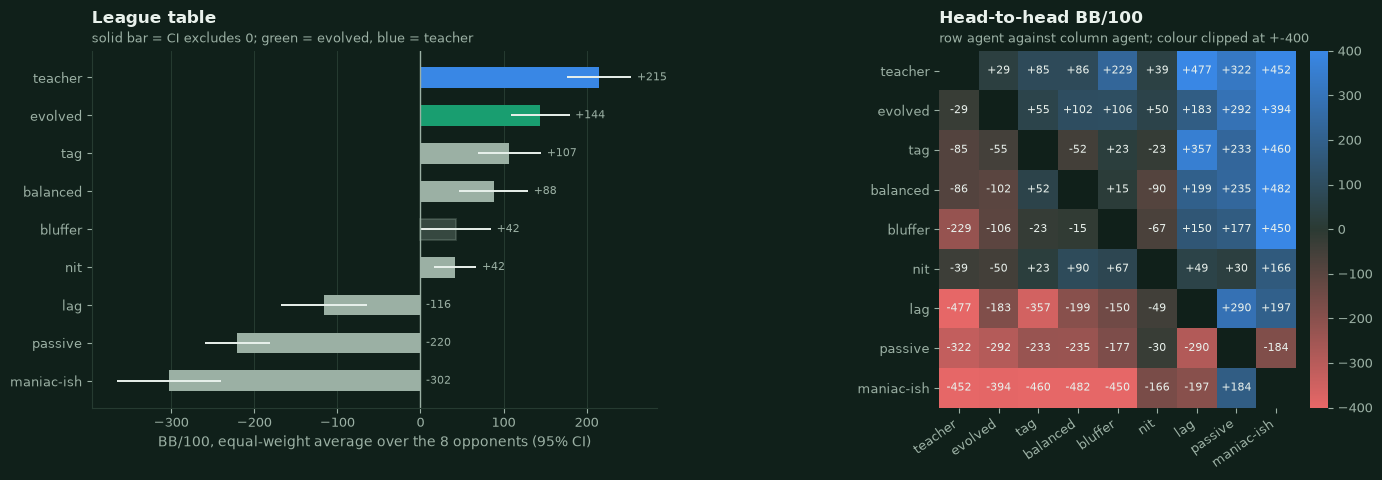

**[fresh]** League of 9 agents, 36 pairings x 1000 hands (500 duplicate pairs each), 19 s. The evolved agent ranks **#2 of 9** with +144 BB/100 (95% CI [+109, +180]); it has 5 significant wins, 0 significant losses and 3 undecided pairings (a pairing is only a 'win' if its CI excludes 0).

| rank | agent | bb_per_100 | ci_low | ci_high | wins | losses | draws |
|---|---|---|---|---|---|---|---|
| 1 | `teacher` | 215 | 176 | 254 | 5 | 0 | 3 |
| 2 | `evolved` | 144 | 109 | 180 | 5 | 0 | 3 |
| 3 | `tag` | 107 | 69 | 145 | 3 | 1 | 4 |
| 4 | `balanced` | 88 | 47 | 130 | 3 | 2 | 3 |
| 5 | `bluffer` | 42 | -1 | 85 | 2 | 2 | 4 |
| 6 | `nit` | 42 | 17 | 67 | 2 | 0 | 6 |
| 7 | `lag` | -116 | -168 | -64 | 2 | 4 | 2 |
| 8 | `passive` | -220 | -259 | -182 | 0 | 7 | 1 |
| 9 | `maniac-ish` | -302 | -365 | -240 | 1 | 7 | 0 |

In [32]:
LEAGUE_AGENTS = ["evolved", "teacher", "nit", "tag", "lag", "passive", "maniac-ish", "balanced", "bluffer"]
league_specs = [EVOLVED_SPEC, EVAL_SPECS["teacher"], *(preset_spec(name) for name in LEAGUE_AGENTS[2:])]
league_root = ARTIFACTS_DIR / "tmp" / "nb03_league"
shutil.rmtree(league_root, ignore_errors=True)
started = time.perf_counter()
league_dir = run_tournament(
    league_specs, MatchConfig(game=GAME, num_hands=STYLE_LEAGUE_HANDS, seed=EVAL_SEED, n_workers=N_WORKERS, keep_hands=SILENT),
    run_name="nb03-league", out_dir=league_root, mark_latest=False,
)  # fmt: skip
league = load_results(league_dir)
board = league.leaderboard()
style = league.style_table().set_index("agent").loc[LEAGUE_AGENTS]
matrix = league.matchup_matrix()
league_pairs = league.pairwise_table()
league_vs_teacher = league_pairs[(league_pairs["agent"] == "evolved") & (league_pairs["opponent"] == "teacher")].iloc[0]
league_seconds = time.perf_counter() - started

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14.0, 4.9), gridspec_kw={"width_ratios": [1, 1.25]})
ranked = board["agent"].tolist()
nbp.bar_with_ci(ax, ranked, board["bb_per_100"], board["ci_low"], board["ci_high"],
                colors=[nbp.ACCENT if a == "evolved" else nbp.SERIES[1] if a == "teacher" else nbp.MUTED for a in ranked])  # fmt: skip
ax.set_xlabel("BB/100, equal-weight average over the 8 opponents (95% CI)")
nbp.title(ax, "League table", "solid bar = CI excludes 0; green = evolved, blue = teacher")
order = [a for a in ranked]
grid = matrix.loc[order, order].to_numpy(dtype=float)
limit = 400.0
image = ax2.imshow(np.clip(grid, -limit, limit), cmap=nbp.DIVERGING, vmin=-limit, vmax=limit)
for i in range(len(order)):
    for j in range(len(order)):
        if i != j:
            ax2.text(j, i, f"{grid[i, j]:+.0f}", ha="center", va="center", fontsize=8, color=nbp.TEXT)
ax2.set_xticks(range(len(order)), order, rotation=35, ha="right")
ax2.set_yticks(range(len(order)), order)
ax2.grid(False)
for spine in ax2.spines.values():
    spine.set_visible(False)
nbp.title(ax2, "Head-to-head BB/100", "row agent against column agent; colour clipped at +-400")
colorbar = fig.colorbar(image, ax=ax2, fraction=0.04, pad=0.02)
colorbar.outline.set_visible(False)
fig.tight_layout()
nbp.savefig("nb03_league", fig)
plt.show()
n_pairs_league = STYLE_LEAGUE_HANDS // 2
evolved_row = board.set_index("agent").loc["evolved"]
display(Markdown(
    f"**[fresh]** League of {len(LEAGUE_AGENTS)} agents, {len(LEAGUE_AGENTS) * (len(LEAGUE_AGENTS) - 1) // 2} pairings x {STYLE_LEAGUE_HANDS} hands ({n_pairs_league} duplicate pairs each), {league_seconds:.0f} s. "
    f"The evolved agent ranks **#{int(evolved_row['rank'])} of {len(board)}** with {evolved_row['bb_per_100']:+.0f} BB/100 (95% CI [{evolved_row['ci_low']:+.0f}, {evolved_row['ci_high']:+.0f}]); "
    f"it has {int(evolved_row['wins'])} significant wins, {int(evolved_row['losses'])} significant losses and {int(evolved_row['draws'])} undecided pairings (a pairing is only a 'win' if its CI excludes 0)."
))
display(md_table(board[["rank", "agent", "bb_per_100", "ci_low", "ci_high", "wins", "losses", "draws"]].assign(agent=lambda f: "`" + f["agent"] + "`"), "{:.0f}"))

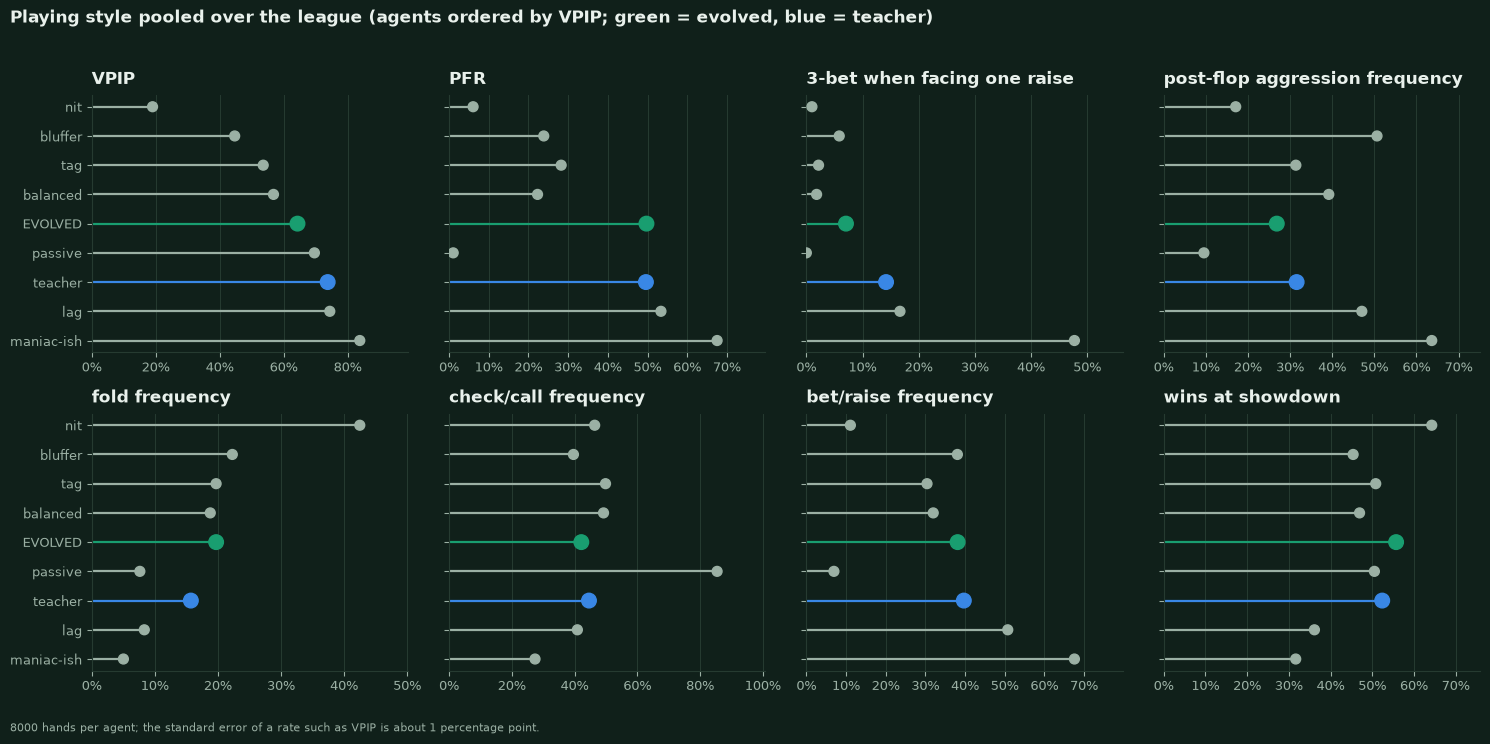

| agent | VPIP | PFR | 3-bet when facing one raise | post-flop aggression frequency | fold frequency | check/call frequency | bet/raise frequency | wins at showdown | aggression factor (bets+raises / calls) |
|---|---|---|---|---|---|---|---|---|---|
| `evolved` | 0.64 | 0.50 | 0.07 | 0.27 | 0.20 | 0.42 | 0.38 | 0.56 | 2.32 |
| `teacher` | 0.74 | 0.50 | 0.14 | 0.32 | 0.16 | 0.45 | 0.40 | 0.52 | 2.21 |
| `nit` | 0.19 | 0.06 | 0.01 | 0.17 | 0.42 | 0.46 | 0.11 | 0.64 | 0.78 |
| `tag` | 0.54 | 0.28 | 0.02 | 0.31 | 0.20 | 0.50 | 0.30 | 0.51 | 1.37 |
| `lag` | 0.74 | 0.53 | 0.17 | 0.47 | 0.08 | 0.41 | 0.51 | 0.36 | 2.26 |
| `passive` | 0.70 | 0.01 | 0.00 | 0.10 | 0.08 | 0.85 | 0.07 | 0.51 | 0.15 |
| `maniac-ish` | 0.84 | 0.68 | 0.48 | 0.64 | 0.05 | 0.27 | 0.68 | 0.32 | 3.75 |
| `balanced` | 0.57 | 0.22 | 0.02 | 0.39 | 0.19 | 0.49 | 0.32 | 0.47 | 1.29 |
| `bluffer` | 0.45 | 0.24 | 0.06 | 0.51 | 0.22 | 0.40 | 0.38 | 0.45 | 1.81 |

**Cross-check with the saved evaluation** (evolved vs the 9 saved opponents, 27,000 hands): VPIP 64%, PFR 49%, aggression factor 2.0, fold share of actions 19%, wins 54% of its showdowns - in the league: VPIP 64%, PFR 50%, aggression factor 2.3, fold frequency 20%.

In [33]:
STYLE_METRICS = (
    ("vpip", "VPIP"), ("pfr", "PFR"), ("three_bet", "3-bet when facing one raise"), ("aggression_freq_postflop", "post-flop aggression frequency"),
    ("fold_freq", "fold frequency"), ("call_freq", "check/call frequency"), ("raise_freq", "bet/raise frequency"), ("showdown_win_rate", "wins at showdown"),
)  # fmt: skip
fig, axes = plt.subplots(2, 4, figsize=(15.0, 7.2), sharey=True)
ranked_by_vpip = style["vpip"].sort_values().index.tolist()
for ax, (metric, name) in zip(axes.flat, STYLE_METRICS):
    values = style.loc[ranked_by_vpip, metric]
    colors = [nbp.ACCENT if a == "evolved" else nbp.SERIES[1] if a == "teacher" else nbp.MUTED for a in ranked_by_vpip]
    ax.hlines(range(len(values)), 0, values, color=colors, linewidth=1.6)
    ax.scatter(values, range(len(values)), s=[110 if a in ("evolved", "teacher") else 50 for a in ranked_by_vpip], color=colors, zorder=3)
    ax.set_xlim(0, max(values.max() * 1.18, 0.05))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="y", visible=False)
    nbp.title(ax, name)
axes[0, 0].set_yticks(range(len(ranked_by_vpip)), [a.upper() if a == "evolved" else a for a in ranked_by_vpip])
axes[0, 0].invert_yaxis()
fig.suptitle("Playing style pooled over the league (agents ordered by VPIP; green = evolved, blue = teacher)", x=0.01, ha="left", fontsize=12, fontweight="bold", color=nbp.TEXT)
nbp.footnote(fig, f"{STYLE_LEAGUE_HANDS * (len(LEAGUE_AGENTS) - 1)} hands per agent; the standard error of a rate such as VPIP is about 1 percentage point.")
fig.tight_layout(rect=(0, 0.01, 1, 0.96))
nbp.savefig("nb03_style", fig)
plt.show()

display(md_table(style[[m for m, _ in STYLE_METRICS] + ["aggression_factor"]].rename(columns=dict(STYLE_METRICS) | {"aggression_factor": "aggression factor (bets+raises / calls)"}).reset_index().assign(agent=lambda f: "`" + f["agent"] + "`"), "{:.2f}"))
saved_style = FINAL["results"]["evolved"]["style"]
display(Markdown(
    f"**Cross-check with the saved evaluation** (evolved vs the 9 saved opponents, {int(saved_style['hands']):,} hands): VPIP {saved_style['vpip']:.0%}, PFR {saved_style['pfr']:.0%}, "
    f"aggression factor {saved_style['aggression_factor']:.1f}, fold share of actions {saved_style['fold_share']:.0%}, wins {saved_style['showdown_win_rate']:.0%} of its showdowns - "
    f"in the league: VPIP {style.loc['evolved', 'vpip']:.0%}, PFR {style.loc['evolved', 'pfr']:.0%}, aggression factor {style.loc['evolved', 'aggression_factor']:.1f}, fold frequency {style.loc['evolved', 'fold_freq']:.0%}."
))

### 8d. Which gene groups carry the performance? A swap test `[fresh]`

For each group of genes we copy the `tag` values of that group into the evolved genome (keeping everything else) and replay
the evaluation against the same opponents on the **same deals** as the evolved agent. The paired difference
(swapped - evolved) says how much of the evolved performance is lost when that group is reverted. The last row replaces *all* genes
(that is the `tag` preset itself). Caveats: one group at a time, so interactions between groups are invisible; and
an effect smaller than the interval is simply not resolved.

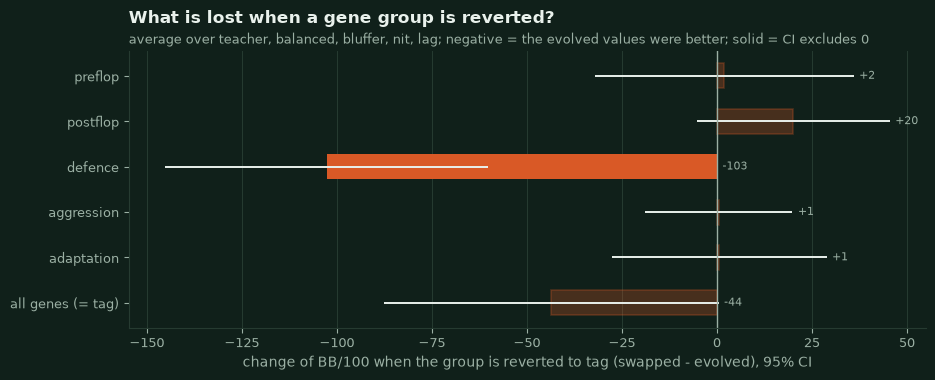

**[fresh]** 21 s. Change of BB/100 against each opponent (* = this opponent's paired CI excludes 0) and averaged (equal weight):

| genes swapped to tag | teacher | balanced | bluffer | nit | lag | average [95% CI] |
|---|---|---|---|---|---|---|
| **preflop** (6 genes) | +53* | -51 | +62 | +0 | -54 | +2 [-32, +36] |
| **postflop** (3 genes) | +0 | -16 | +46 | +15 | +55 | +20 [-5, +45] |
| **defence** (4 genes) | -215* | -174* | -37 | -30 | -58 | -103 [-145, -60] |
| **aggression** (3 genes) | +7 | +2 | -4 | +1 | -4 | +1 [-19, +20] |
| **adaptation** (2 genes) | +54* | -45 | +26 | -6 | -27 | +1 [-28, +29] |
| **all genes (= tag)** | -41 | -128* | +29 | -33 | -45 | -44 [-88, +0] |

In [34]:
GENE_GROUPS = {group: [s.name for s in GENE_SPECS if s.group == group] for group in dict.fromkeys(s.group for s in GENE_SPECS)}


def swapped_genome(group: str) -> Genome:
    vector, reference = EVOLVED.to_vector(), PRESETS["tag"].to_vector()
    index = [GENE_NAMES.index(name) for name in GENE_GROUPS[group]]
    vector[index] = reference[index]
    return Genome.from_vector(vector)


swap_specs = {group: genome_spec(f"swap_{group}", swapped_genome(group)) for group in GENE_GROUPS}
started = time.perf_counter()
swap_pairs = run_pairs({(group, opp): (spec, EVAL_SPECS[opp], pairs_for(opp), (EVAL_SEED, opp)) for group, spec in swap_specs.items() for opp in SWAP_OPPONENTS})
swap_seconds = time.perf_counter() - started
swap_rows, swap_estimates = [], {}
for group in [*GENE_GROUPS, "all genes (= tag)"]:
    source = {opp: (swap_pairs[group, opp] if group in GENE_GROUPS else eval_pairs["tag", opp]) for opp in SWAP_OPPONENTS}
    deltas = {opp: scale_to_bb_per_100(source[opp] - eval_pairs["evolved", opp], 2) for opp in SWAP_OPPONENTS}
    pooled = pool_groups(list(deltas.values()), weighting="equal")
    swap_estimates[group] = pooled
    row = {"genes swapped to tag": f"**{group}**" + (f" ({len(GENE_GROUPS[group])} genes)" if group in GENE_GROUPS else "")}
    for opp, d in deltas.items():
        low, high = stats.t.interval(0.95, len(d) - 1, loc=d.mean(), scale=stats.sem(d))
        row[opp] = f"{d.mean():+.0f}{'*' if low > 0 or high < 0 else ''}"
    row["average [95% CI]"] = ci_text(pooled.mean, pooled.ci_low, pooled.ci_high)
    swap_rows.append(row)

fig, ax = plt.subplots(figsize=(9.5, 3.9))
names = list(swap_estimates)
nbp.bar_with_ci(ax, names, [e.mean for e in swap_estimates.values()], [e.ci_low for e in swap_estimates.values()], [e.ci_high for e in swap_estimates.values()],
                colors=nbp.SERIES[2], value_format="{:+.0f}")  # fmt: skip
ax.set_xlabel("change of BB/100 when the group is reverted to tag (swapped - evolved), 95% CI")
nbp.title(ax, "What is lost when a gene group is reverted?", f"average over {', '.join(SWAP_OPPONENTS)}; negative = the evolved values were better; solid = CI excludes 0")
fig.tight_layout()
nbp.savefig("nb03_swap_test", fig)
plt.show()
display(Markdown(f"**[fresh]** {swap_seconds:.0f} s. Change of BB/100 against each opponent (* = this opponent's paired CI excludes 0) and averaged (equal weight):"))
display(md_table(pd.DataFrame(swap_rows)))

## 9. Interpretation

The three blocks below are kept strictly apart: **empirical findings** are numbers computed in this notebook (every number is
generated from the variables above, so the text stays truthful if the artifacts are regenerated); **assumptions** are things
taken as given; **speculation** are hypotheses the data suggest but that were not tested.

In [35]:
# ---- numbers quoted by the text (all computed in the cells above) ----
evolved_vs = {opp: fresh["evolved", opp] for opp in EVAL_OPPONENTS}
hand_made_opponents = [o for o in EVAL_OPPONENTS if o not in BOTS and o != "teacher"]
verdict_counts = {w: [verdict(evolved_vs[o].ci_low, evolved_vs[o].ci_high) for o in hand_made_opponents].count(w) for w in ("wins", "no significant difference", "loses")}
bots_won = sum(evolved_vs[o].ci_low > 0 for o in BOTS)
teacher_fresh, teacher_saved = evolved_vs["teacher"], FINAL["results"]["evolved"]["teacher"]
teacher_word = verdict(teacher_fresh.ci_low, teacher_fresh.ci_high)
teacher_phrase = {"loses": "**loses** to the teacher", "wins": "**beats** the teacher", "no significant difference": "is **not distinguishable** from the teacher"}[teacher_word]
board_by_agent = board.set_index("agent")
saved_teacher_word = verdict(teacher_saved["ci_low"], teacher_saved["ci_high"])
tag_held, tag_bots = paired_estimates["tag", list(GROUPS_OF_OPPONENTS)[0]], paired_estimates["tag", list(GROUPS_OF_OPPONENTS)[1]]
lag_held, nit_held = paired_estimates["lag", list(GROUPS_OF_OPPONENTS)[0]], paired_estimates["nit", list(GROUPS_OF_OPPONENTS)[0]]
group_only = {g: e for g, e in swap_estimates.items() if g in GENE_GROUPS}
costliest = min(group_only, key=lambda g: group_only[g].mean)
reverting_gains = [g for g, e in group_only.items() if e.ci_low > 0]
reverting_costs = [g for g, e in group_only.items() if e.ci_high < 0]
seed_sentence = {
    "wins": "So on held-out opponents the evolved agent is **significantly better** than the best hand-made seed in this sample.",
    "no significant difference": "So on held-out opponents these data do **not** resolve a difference between the evolved agent and the best hand-made seed (the paired interval contains 0); item 5 describes how its playing style differs.",
    "loses": "So on held-out opponents the best hand-made seed is **significantly better** than the evolved agent in this sample.",
}[verdict(tag_held.ci_low, tag_held.ci_high)]
pinned = dict(zip(GENE_NAMES, spread_last))
er, tr = preflop_ranges["evolved"], preflop_ranges["tag"]
bots_vs_tag = "less" if tag_bots.ci_high < 0 else "more" if tag_bots.ci_low > 0 else "about as much"
bottom_gain, top_gain = np.quantile(fin, 0.1) - np.quantile(ini, 0.1), fin.max() - ini.max()
gain_shape = "The gain is larger at the bottom of the population than at the top" if bottom_gain > top_gain else "The gain is at least as large at the top of the population as at the bottom"
wide_and_narrow = er["button: raise first-in"] > tr["button: raise first-in"] and er["vs a pot-sized raise: continue"] < tr["vs a pot-sized raise: continue"]
style_words = (
    "In words: **wide, aggressive entry and narrow continuation against resistance** - a steal-and-fold profile"
    if wide_and_narrow else "Compare the preflop ranges in section 6.1 for how its entry and continuation ranges differ from tag's"
)
bots_missed = [o for o in BOTS if not evolved_vs[o].ci_low > 0]
bots_note = f" (not resolved against {', '.join(bots_missed)})" if bots_missed else ""
n_replay = len(replay_estimates)
protocol_title = "does not change any verdict" if same_verdict == n_replay else f"changes {n_replay - same_verdict} of {n_replay} verdicts"
aa_text = "; ".join(
    f"{name}: legacy {ci_text(aa_results[name, SINGLE_TABLE].bb_per_100, aa_results[name, SINGLE_TABLE].ci_low, aa_results[name, SINGLE_TABLE].ci_high)} -> "
    f"two-table {ci_text(aa_results[name, TWO_TABLE].bb_per_100, aa_results[name, TWO_TABLE].ci_low, aa_results[name, TWO_TABLE].ci_high)}"
    for name in AA_SPECS
)
teacher_legacy, teacher_two = replay_estimates["teacher"][SINGLE_TABLE], replay_estimates["teacher"][TWO_TABLE]
same_session_verdict = [o for o, (long_e, short_e, _) in session_gap.items() if verdict(long_e.ci_low, long_e.ci_high) == verdict(short_e.ci_low, short_e.ci_high)]
session_text = "; ".join(
    f"{opp}: {ci_text(long_e.mean, long_e.ci_low, long_e.ci_high)} (long) vs {ci_text(short_e.bb_per_100, short_e.ci_low, short_e.ci_high)} (short)"
    for opp, (long_e, short_e, _) in session_gap.items()
)
variance_summary = "; ".join(f"{opp.replace('_', ' ')} x{r[0]:.1f} ({r[1]:.1f}-{r[2]:.1f})" for opp, r in ratios.items())
league_note = (
    ": too short to resolve a difference of the size the dedicated evaluation finds, which is the one to quote."
    if league_vs_teacher["ci_low"] <= 0 <= league_vs_teacher["ci_high"] else "."
)
pct = lambda v: f"{v:.0%}"  # noqa: E731
pp = lambda a, b: f"{abs(a - b) * 100:.0f} points"  # noqa: E731

display(Markdown(f"""
### 9.1 Empirical findings (computed in this notebook)

1. **Evolution improved the population on held-out data `[saved]`.** The median held-out score of the whole population rose from {np.median(ini):.0f} to {np.median(fin):.0f}
   (bootstrap 95% CI of the difference [{gain_low:+.0f}, {gain_high:+.0f}]); {pct(np.mean(fin > best_preset_value))} of the final genomes beat the best hand-made seed on the held-out set
   (initial population: {pct(np.mean(ini > best_preset_value))}). {gain_shape} (10% quantile {np.quantile(ini, 0.1):.0f} -> {np.quantile(fin, 0.1):.0f}; best genome
   {ini.max():.0f} -> {fin.max():.0f}); the best-of-generation curves are too noisy to show a trend on their own (Spearman rho between training best and validation of the same genome {rho_noise.statistic:.2f}).
2. **Where the evolved agent stands `[fresh]`.** On {EVAL_PAIRS} duplicate pairs per opponent it beats {bots_won} of 3 exploitable bots{bots_note}, and against the {len(hand_made_opponents)} hand-made styles it wins {verdict_counts['wins']}, is
   statistically indistinguishable from {verdict_counts['no significant difference']} and loses to {verdict_counts['loses']}. Against the three opponents it never trained against: `balanced` {ci_text(evolved_vs['balanced'].bb_per_100, evolved_vs['balanced'].ci_low, evolved_vs['balanced'].ci_high)} ({verdict(evolved_vs['balanced'].ci_low, evolved_vs['balanced'].ci_high)}),
   `bluffer` {ci_text(evolved_vs['bluffer'].bb_per_100, evolved_vs['bluffer'].ci_low, evolved_vs['bluffer'].ci_high)} ({verdict(evolved_vs['bluffer'].ci_low, evolved_vs['bluffer'].ci_high)}), teacher: see item 3.
3. **The teacher `[fresh]` `[saved]`.** On {teacher_fresh.n_pairs} fresh duplicate pairs the evolved agent {teacher_phrase}: {ci_text(teacher_fresh.bb_per_100, teacher_fresh.ci_low, teacher_fresh.ci_high)} BB/100
   (conservative match-level interval [{teacher_fresh.match_ci_low:+.0f}, {teacher_fresh.match_ci_high:+.0f}]); the saved held-out run says the same: {ci_text(teacher_saved['bb_per_100'], teacher_saved['ci_low'], teacher_saved['ci_high'])} ({saved_teacher_word}).
   The hand-made `tag` loses to the teacher too ({ci_text(fresh['tag', 'teacher'].bb_per_100, fresh['tag', 'teacher'].ci_low, fresh['tag', 'teacher'].ci_high)}), `lag` much more ({ci_text(fresh['lag', 'teacher'].bb_per_100, fresh['lag', 'teacher'].ci_low, fresh['lag', 'teacher'].ci_high)}).
   In the 9-agent league the evolved agent ranks #{int(board_by_agent.loc['evolved', 'rank'])} ({board_by_agent.loc['evolved', 'bb_per_100']:+.0f} BB/100) and the teacher #{int(board_by_agent.loc['teacher', 'rank'])} ({board_by_agent.loc['teacher', 'bb_per_100']:+.0f});
   the league's own evolved-vs-teacher pairing ({int(league_vs_teacher['units'])} pairs) reads {ci_text(league_vs_teacher['bb_per_100'], league_vs_teacher['ci_low'], league_vs_teacher['ci_high'])} ({verdict(league_vs_teacher['ci_low'], league_vs_teacher['ci_high'])}){league_note}
4. **Against the hand-made seeds `[fresh]`, paired on identical deals.** Evolved minus `tag` on the held-out opponents: {ci_text(tag_held.mean, tag_held.ci_low, tag_held.ci_high)} BB/100 ({verdict(tag_held.ci_low, tag_held.ci_high)});
   minus `lag`: {ci_text(lag_held.mean, lag_held.ci_low, lag_held.ci_high)} ({verdict(lag_held.ci_low, lag_held.ci_high)}); minus `nit`: {ci_text(nit_held.mean, nit_held.ci_low, nit_held.ci_high)} ({verdict(nit_held.ci_low, nit_held.ci_high)}).
   Against the three exploitable bots the evolved agent earns {bots_vs_tag} than `tag` ({ci_text(tag_bots.mean, tag_bots.ci_low, tag_bots.ci_high)}).
   {seed_sentence}
5. **How it plays `[fresh]`.** League-pooled VPIP {pct(style.loc['evolved', 'vpip'])} / PFR {pct(style.loc['evolved', 'pfr'])} / aggression factor {style.loc['evolved', 'aggression_factor']:.1f} (tag: {pct(style.loc['tag', 'vpip'])} / {pct(style.loc['tag', 'pfr'])} / {style.loc['tag', 'aggression_factor']:.1f};
   teacher: {pct(style.loc['teacher', 'vpip'])} / {pct(style.loc['teacher', 'pfr'])} / {style.loc['teacher', 'aggression_factor']:.1f}). It raises first-in with {pct(er['button: raise first-in'])} of all starting hands from the button (tag {pct(tr['button: raise first-in'])}), limps
   with only {pct(er['button: limp'])}, but continues against a **pot-sized** preflop raise with only {pct(er['vs a pot-sized raise: continue'])} of hands (tag {pct(tr['vs a pot-sized raise: continue'])}). Post-flop it bluffs rarely (`bluff_freq` {EVOLVED.bluff_freq:.2f}; tag {PRESETS['tag'].bluff_freq:.2f}),
   its post-flop aggression frequency is {pct(style.loc['evolved', 'aggression_freq_postflop'])} (tag {pct(style.loc['tag', 'aggression_freq_postflop'])}, teacher {pct(style.loc['teacher', 'aggression_freq_postflop'])}), and it wins {pct(style.loc['evolved', 'showdown_win_rate'])} of its showdowns (the nit: {pct(style.loc['nit', 'showdown_win_rate'])}).
   {style_words}. Its closest hand-made relative by gene values is `{nearest}` (distance {distance[nearest]:.2f}).
6. **Which genes carry the performance `[fresh]`, swap test.** Reverting one group of genes at a time to the `tag` values (average over {', '.join(SWAP_OPPONENTS)}, paired on identical deals): the largest change is for **{costliest}**
   ({ci_text(group_only[costliest].mean, group_only[costliest].ci_low, group_only[costliest].ci_high)} BB/100). Groups whose reversal costs a resolvable amount: {', '.join(f'**{g}**' for g in reverting_costs) or 'none'}.
   Groups whose reversal *gains* a resolvable amount (the evolved values were not better than tag's on this panel): {', '.join(f'**{g}**' for g in reverting_gains) or 'none'}. All other groups are within noise. Not every evolved value is an improvement.
7. **Genes that evolution pinned down `[saved]`.** Final population spread (SD / range): `fold_big_bet` {pinned['fold_big_bet']:.2f}, `adapt_fold` {pinned['adapt_fold']:.2f}, `position_bonus` {pinned['position_bonus']:.2f}, `pf_3bet` {pinned['pf_3bet']:.2f}, `shove_threshold` {pinned['shove_threshold']:.2f},
   against a mean of {spread_last.mean():.2f} (random: {spread_first.mean():.2f}). The loosest genes are `{GENE_NAMES[order_pinned[-1]]}`, `{GENE_NAMES[order_pinned[-2]]}` and `{GENE_NAMES[order_pinned[-3]]}` (whether that is weak selection or drift was not tested).
8. **What the fitness design bought `[fresh]`.** Variance of a {VARIANCE_SESSION_HANDS}-hand estimate under independent deals divided by the variance under duplicate deals (bootstrap 95% CI over {VARIANCE_SESSIONS} sessions): {variance_summary}.
   Duplicate dealing removes card luck, not the luck of an opponent's own random actions, so a ratio near 1 is expected against `random` and the intervals show how little {VARIANCE_SESSIONS} sessions resolve. Sharing the deals between genomes (CRN) gives a standard error of a genome-vs-genome
   difference of {se_crn:.0f} BB/100, against {se_independent:.0f} with different deals (r = {rho:.2f} between the genomes' per-pair results) - {crn_word} on top of the duplicate pairing. Training and held-out deals are disjoint ({sum(overlap.values())} overlaps among {len(train_deals) + len(valid_deals) + len(final_deals) + len(eval_deals):,} checked deals).
9. **The duplicate-protocol artifact {protocol_title} here `[fresh]` (section 3.5).** Identical copies against each other, first-named copy in BB/100 (0 expected): {aa_text}.
   Replaying the evolved genome's saved final evaluation under both protocols on the same deals ({PROTOCOL_PAIRS} pairs per opponent) gives the same verdict against {same_verdict} of {n_replay} opponents; the average paired shift (legacy minus two-table) is
   {ci_text(average_shift.mean, average_shift.ci_low, average_shift.ci_high)} BB/100, and against the teacher the genome scores {ci_text(teacher_legacy.mean, teacher_legacy.ci_low, teacher_legacy.ci_high)} (legacy) vs {ci_text(teacher_two.mean, teacher_two.ci_low, teacher_two.ci_high)} (two-table).
   The genome was nevertheless **trained** under the legacy protocol; retraining under the corrected one is open (9.5).
10. **The evaluation set-up matters for this adaptive agent `[fresh]` (8b follow-up).** One long session per opponent (the training run's own set-up) against 100-hand sessions (the set-up of every other fresh number here and of the league): {session_text}.
   The size of the evolved genome's edge is therefore tied to the set-up; the verdict (wins / loses / no significant difference) coincides across the two set-ups for {len(same_session_verdict)} of {len(session_gap)} opponents ({', '.join(same_session_verdict) or 'none'}).
"""))


### 9.1 Empirical findings (computed in this notebook)

1. **Evolution improved the population on held-out data `[saved]`.** The median held-out score of the whole population rose from 73 to 139
   (bootstrap 95% CI of the difference [+43, +84]); 25% of the final genomes beat the best hand-made seed on the held-out set
   (initial population: 2%). The gain is larger at the bottom of the population than at the top (10% quantile 28 -> 111; best genome
   158 -> 191); the best-of-generation curves are too noisy to show a trend on their own (Spearman rho between training best and validation of the same genome -0.20).
2. **Where the evolved agent stands `[fresh]`.** On 600 duplicate pairs per opponent it beats 2 of 3 exploitable bots (not resolved against random), and against the 7 hand-made styles it wins 4, is
   statistically indistinguishable from 3 and loses to 0. Against the three opponents it never trained against: `balanced` +170 [+81, +259] (wins),
   `bluffer` +71 [-12, +154] (no significant difference), teacher: see item 3.
3. **The teacher `[fresh]` `[saved]`.** On 2000 fresh duplicate pairs the evolved agent **loses** to the teacher: -85 [-122, -47] BB/100
   (conservative match-level interval [-124, -46]); the saved held-out run says the same: -106 [-155, -57] (loses).
   The hand-made `tag` loses to the teacher too (-125 [-172, -79]), `lag` much more (-343 [-417, -270]).
   In the 9-agent league the evolved agent ranks #2 (+144 BB/100) and the teacher #1 (+215);
   the league's own evolved-vs-teacher pairing (500 pairs) reads -29 [-95, +36] (no significant difference): too short to resolve a difference of the size the dedicated evaluation finds, which is the one to quote.
4. **Against the hand-made seeds `[fresh]`, paired on identical deals.** Evolved minus `tag` on the held-out opponents: +47 [-9, +103] BB/100 (no significant difference);
   minus `lag`: +301 [+223, +380] (wins); minus `nit`: +29 [-17, +75] (no significant difference).
   Against the three exploitable bots the evolved agent earns less than `tag` (-300 [-396, -203]).
   So on held-out opponents these data do **not** resolve a difference between the evolved agent and the best hand-made seed (the paired interval contains 0); item 5 describes how its playing style differs.
5. **How it plays `[fresh]`.** League-pooled VPIP 64% / PFR 50% / aggression factor 2.3 (tag: 54% / 28% / 1.4;
   teacher: 74% / 50% / 2.2). It raises first-in with 76% of all starting hands from the button (tag 49%), limps
   with only 5%, but continues against a **pot-sized** preflop raise with only 14% of hands (tag 49%). Post-flop it bluffs rarely (`bluff_freq` 0.02; tag 0.12),
   its post-flop aggression frequency is 27% (tag 31%, teacher 32%), and it wins 56% of its showdowns (the nit: 64%).
   In words: **wide, aggressive entry and narrow continuation against resistance** - a steal-and-fold profile. Its closest hand-made relative by gene values is `tag` (distance 0.17).
6. **Which genes carry the performance `[fresh]`, swap test.** Reverting one group of genes at a time to the `tag` values (average over teacher, balanced, bluffer, nit, lag, paired on identical deals): the largest change is for **defence**
   (-103 [-145, -60] BB/100). Groups whose reversal costs a resolvable amount: **defence**.
   Groups whose reversal *gains* a resolvable amount (the evolved values were not better than tag's on this panel): none. All other groups are within noise. Not every evolved value is an improvement.
7. **Genes that evolution pinned down `[saved]`.** Final population spread (SD / range): `fold_big_bet` 0.09, `adapt_fold` 0.05, `position_bonus` 0.07, `pf_3bet` 0.08, `shove_threshold` 0.08,
   against a mean of 0.11 (random: 0.29). The loosest genes are `pf_bb_raise`, `pf_shove` and `adapt_aggression` (whether that is weak selection or drift was not tested).
8. **What the fitness design bought `[fresh]`.** Variance of a 100-hand estimate under independent deals divided by the variance under duplicate deals (bootstrap 95% CI over 60 sessions): teacher x2.0 (1.3-3.2); call station x1.5 (1.0-2.3); maniac x1.2 (0.8-1.9); random x1.1 (0.7-2.0).
   Duplicate dealing removes card luck, not the luck of an opponent's own random actions, so a ratio near 1 is expected against `random` and the intervals show how little 60 sessions resolve. Sharing the deals between genomes (CRN) gives a standard error of a genome-vs-genome
   difference of 64 BB/100, against 60 with different deals (r = -0.03 between the genomes' per-pair results) - no measurable gain on top of the duplicate pairing. Training and held-out deals are disjoint (0 overlaps among 34,200 checked deals).
9. **The duplicate-protocol artifact does not change any verdict here `[fresh]` (section 3.5).** Identical copies against each other, first-named copy in BB/100 (0 expected): evolved genome: legacy +1 [-22, +24] -> two-table -14 [-38, +11]; teacher: legacy -30 [-49, -11] -> two-table +0 [+0, +0].
   Replaying the evolved genome's saved final evaluation under both protocols on the same deals (800 pairs per opponent) gives the same verdict against 9 of 9 opponents; the average paired shift (legacy minus two-table) is
   -17 [-46, +12] BB/100, and against the teacher the genome scores -153 [-219, -87] (legacy) vs -117 [-183, -50] (two-table).
   The genome was nevertheless **trained** under the legacy protocol; retraining under the corrected one is open (9.5).
10. **The evaluation set-up matters for this adaptive agent `[fresh]` (8b follow-up).** One long session per opponent (the training run's own set-up) against 100-hand sessions (the set-up of every other fresh number here and of the league): random: +205 [+125, +285] (long) vs +82 [-25, +190] (short); maniac: +909 [+772, +1046] (long) vs +550 [+362, +739] (short); teacher: -87 [-130, -44] (long) vs -85 [-122, -47] (short).
   The size of the evolved genome's edge is therefore tied to the set-up; the verdict (wins / loses / no significant difference) coincides across the two set-ups for 2 of 3 opponents (maniac, teacher).


### 9.2 Assumptions (taken as given, not tested here)

1. **Equity against a random hand is a usable summary of hand strength**, and a simple outs count identifies the draws worth semi-bluffing.
2. **One fixed game**: heads-up, blinds 5/10, stacks reset to 100 BB before every hand. Nothing here says how the strategies behave at other depths or in a tournament setting.
3. **The teacher is a heuristic reference opponent, not a solver.** Losing to it means "weaker than this particular rule set", not "weak".
4. **The training pool and the three held-out opponents stand in for "solid" play.** BB/100 against exploitable bots (random, call station, maniac) measures how much a weakness is punished, not the quality of the strategy.
5. **Duplicate pairs are treated as independent units.** In the two-table protocol nothing a table learns about one deal reaches the other table, but consecutive deals at a table stay dependent through the opponent statistics of adaptive agents (the evolved agent, teacher, balanced, bluffer); the more conservative match-level interval is shown next to every result in section 8b so that the effect can be judged.
6. **Multiplicity.** Dozens of intervals are shown; a few will exclude 0 by chance (the replication check in 8b is the reminder). Findings that rest on one marginal interval should be read as hints.

### 9.3 Speculation (hypotheses suggested by the data, not tested)

1. **The GA mainly learned to correct the optimism of "equity vs a random hand" when facing bets.** Findings 5-7 give the numbers (the defence group, `fold_big_bet` in particular, and how far the population converged on it); they are *consistent* with this reading, they do not test it. An explicit experiment (freeze all other genes, scan this one gene) would.
2. **The adaptation genes may be tuned to the training pool.** The pool contains a maniac, a calling station and two loose-aggressive styles; an `adapt_aggression` that calls aggressive opponents down lighter can pay there and cost against a solid aggressive opponent such as the teacher. The per-opponent cells of the swap table in 8d (the adaptation row against the teacher in particular) are where this would show up; even there it would not be proof.
3. **The teacher's remaining edge probably comes from what the 18-gene cascade cannot express** - bet-size-dependent range penalties with relief for strong hands, board-texture-aware continuation bets, short-stack push/fold. That is a statement about representation, not about the search.
4. **A different seed would probably produce a different genome of similar quality.** A sizeable share of the final genomes beats the best hand-made seed on the held-out set (finding 1) and the final population is still spread out in several genes (finding 7), which suggests a broad plateau of good strategies rather than one sharp optimum; only one run exists, so this is not measured.
5. **Earning less than the seeds from exploitable bots is the intended effect of the saturating utility** (section 3): beyond the cap, extra profit from one opponent does not raise the fitness, so nothing pushes the population toward squeezing the bots harder. Not tested against a run without saturation.
6. **Training against the teacher would likely narrow or close the gap** - and would destroy the teacher's role as a held-out judge. A fair design needs a second, never-trained-against reference (see below).

### 9.4 Limitations

* **Single training run** (seed 2026): no estimate of run-to-run variability, no comparison with another optimiser.
* **Noisy fitness.** a few thousand hands per genome and generation (section 1), fresh deals each generation: rankings inside a generation are noisy (section 5), the maximum is inflated (winner's curse; mitigated by re-ranking the finalists on fresh deal sets, which is itself small).
* **Equity-vs-random heuristic** and a hand-written rule cascade: the search space is small by design (that is what makes it readable) and bounded by the cascade.
* **Opponent-pool dependence.** The pool, its seeds and the hand-made styles were chosen by us; only three opponents are truly held out, and two of them are also hand-made.
* **No opponent-range modelling.** Adaptation uses two smoothed statistics (fold-to-bet, aggression); nothing tracks what an opponent's actions say about its cards.
* **Training protocol.** The GA was trained, and its validation curves were recorded, under the legacy single-table duplicate protocol; only the final evaluation and everything marked `[fresh]` use the corrected two-table one (section 3.5). The replay there shows how much this moves the evolved genome's *evaluation*; a GA trained under the corrected protocol could still end up elsewhere.
* **Evaluation set-up matters for adaptive agents.** The saved evaluation plays one long session per opponent, the fresh evaluations and the league play short independent sessions; for the evolved genome the two differ noticeably against some opponents (follow-up in 8b). Numbers are comparable within a set-up, not across.
* **Artifact detail.** `population_final.json` is sorted by training fitness, whereas the per-genome held-out scores in `metadata.json` follow the unsorted population order, so gene values cannot be matched to held-out scores without re-validating every genome.
* **Only genome-level swaps** were tested (one group at a time): interactions between groups, and individual genes, are unresolved at this sample size.

### 9.5 Ideas for future work

* **Retrain under the two-table protocol** (the fitness evaluator's new default) with the same seed and compare genomes, validation curves and held-out results with this run.
* **Repeat the run with several seeds** and report the spread of the evolved genomes and of their held-out scores; compare with CMA-ES / differential evolution on the same fitness.
* **A second held-out judge**: keep the teacher out of training, and add a *best-response* style exploiter or the EBM / XGBoost agents as additional never-trained-against opponents (the tournament framework already runs them).
* **A richer, still readable genome**: bet size and range-aware continuation (equity against an opponent's *estimated* range instead of a random hand), board texture, per-street bluff rates, short-stack behaviour.
* **Variance reduction for the fitness**: more pairs where the pool is hardest, stratified deals, control variates or an AIVAT-style estimator, adaptive sampling of finalists.
* **Co-evolution with a league** (hall of fame of more diverse generations, opponent sampling by difficulty) and an exploitability check of the final strategy.
* **Gene-level ablation with more pairs**, and a per-gene scan of the single most valuable gene (`fold_big_bet`).

In [36]:
runtime = time.perf_counter() - NOTEBOOK_STARTED
figure_files = sorted((ARTIFACTS_DIR / "figures").glob("nb03_*.png"))
display(Markdown(
    f"Notebook run time: **{runtime / 60:.1f} min** on {N_WORKERS} worker processes. Figures written to `artifacts/figures/` ({len(figure_files)} files, "
    f"{sum(f.stat().st_size for f in figure_files) / 1e6:.1f} MB): " + ", ".join(f"`{f.name}`" for f in figure_files) + "."
))

Notebook run time: **3.3 min** on 6 worker processes. Figures written to `artifacts/figures/` (16 files, 1.9 MB): `nb03_duplicate_variance.png`, `nb03_eval_fresh.png`, `nb03_eval_saved.png`, `nb03_fitness_design.png`, `nb03_fitness_evolution.png`, `nb03_league.png`, `nb03_operators_crossover.png`, `nb03_operators_mutation.png`, `nb03_operators_selection.png`, `nb03_population_genes.png`, `nb03_population_heatmaps.png`, `nb03_population_pca.png`, `nb03_strategy_heatmap.png`, `nb03_style.png`, `nb03_swap_test.png`, `nb03_threshold_ladder.png`.